<a href="https://colab.research.google.com/github/LuckCsta/ProjetoIntegrador/blob/main/WORKFLOW_PARTE_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 2 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: Lucas da Silva Ferreira Costa

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://colab.research.google.com/drive/1g6c2ZtiVcaIlR0ju36mEz5wWs8lDNHYz?usp=sharing)

**LINK PARA SEU GITHUB DO PROJETO COMPLETO - OBRIGATÓRIO (0.5 ponto)**: [AQUI](https://github.com/LuckCsta/ProjetoIntegrador)

**LINK PARA SEU PRÓPRIO VÍDEO NO YOUTUBE - OBRIGATÓRIO (0.5 ponto):** [Aqui](https://)

# **Cenário Fictício**:

Prezados(as) alunos(as),

É ótimo que você como **Consultor** ( ***Data Science Consultant*** ) do **Projeto Data Science** tenha chegado no **Workflow - Parte 2: Aprendizado de Máquina** (*Machine Learnning*). A *Incrível Biblioteca*:

<center>

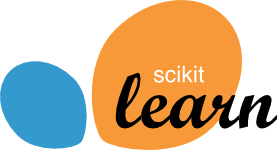

<center>

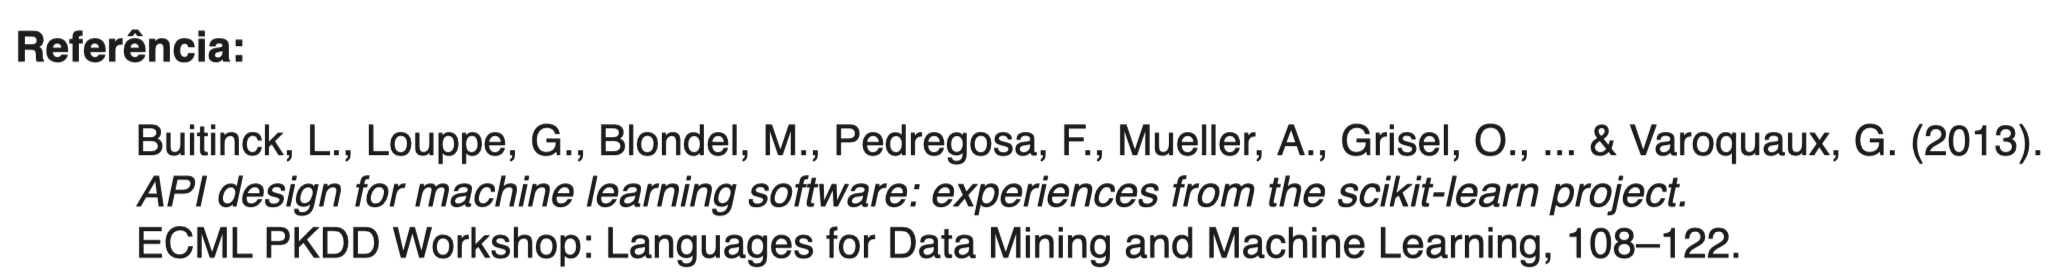

Neste etapa, você irá usar conjuntos (vários) que virão do **Workflow - Parte1**, a saber:

*   Conjunto de Treinamento: ***train***
*   Conjunto de Validação: ***validation***
*   Conjunto de Teste: ***test***

<center>

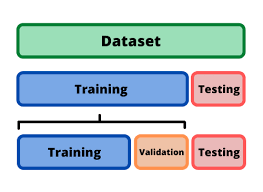

Ou seja:

<center>

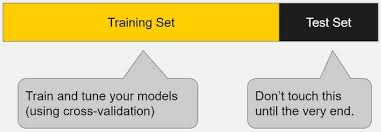


Com todas as Análises e *Insights* (**Estatistica Descritiva,** **Testes de Hipóteses** e os **Métodos Quantitativos**) que irão garatir que temos conjuntos com Qualidade (***Best Quality Analytics***) e que são ótimas amostras em relação a população ratificando justamente a importância da Parte 1 do projeto.

<center>

**EXCELENTE!!! Agora podemos ir mais longe no Universo Python!** 🚀🚀🚀

</center>

Podemos praticar as técnicas mais avançadas do **Aprendizado de Máquina** (*Machine Learnning*) e criarmos aprendizes dos seguintes modelos, a saber:

*   REGRESSOR: Modelo de Regressão: [Regression](https://scikit-learn.org/stable/supervised_learning.html)
*   CLUSTERIZADOR: Modelo de Agrupamento: [Clustering](https://scikit-learn.org/stable/modules/clustering.html)
*   CLASSIFICADOR: Modelo de Classificação:  [Classification](https://scikit-learn.org/stable/supervised_learning.html)

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do projeto, adotaremos um **Fluxo de Projeto (Ciclo de Vida)** composto pela atividades estabelecidas no **Workflow - Parte 2**, conforme a seguir:

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

## Load dos Datasets:

In [2]:
# Bibliotecas usadas em toda a Parte 2
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)

# Nomes e escolhas que se repetem no notebook inteiro
ALVO = "TOTAL (R$)"
ESTRATO = "TIPO DA CONTA"
RENDA = "RENDA BRUTO (R$)"
ORDEM_ESTRATOS = ["ESSENTIAL", "VIP", "PRIME"]
CORES = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a", "GERAL": "#898781"}

# Tamanho ideal encontrado na A1.1 da Parte 1, puxado pelo estrato PRIME
# (procedimento empírico, limiar de R$ 0,001 e 10 pontos consecutivos)
N_IDEAL = 141_900
SEMENTE = 42

# load do seu TABLE aqui: Numero 42
table42 = pd.read_csv('table42.csv', index_col=0)


def criar_conjuntos(df=None, n=N_IDEAL, semente=SEMENTE):
    """
    HELP: Monta os conjuntos da Parte 2 com a mesma base limpa e o mesmo sorteio da Parte 1.

    1. Refaz o ETL da Parte 1: remove as notas fiscais com alguma medida de vinho
       negativa, porque concentração negativa é fisicamente impossível.
    2. Embaralha as posições da base limpa com a semente 42, exatamente como na A1.3
       da Parte 1, e corta blocos seguidos, sem nenhuma nota fiscal em comum:
         train      = posições de 0 a n        -> é a SAMPLE 1 da Parte 1
         validation = posições de n a 2n       -> é a SAMPLE 2 da Parte 1
         test       = posições de 2n a 3n      -> o próximo bloco do mesmo sorteio
         populacao  = o restante da base limpa -> usada nos testes com amostra da população
    3. Salva train.csv, validation.csv e test.csv e carrega os três de volta.

    Parâmetros: df (padrão: table42), n (tamanho ideal, padrão 141.900), semente (padrão 42).
    Retorna: dicionário com train, validation, test, populacao e base_limpa.
    """
    if df is None:
        df = table42

    # Mesma regra de limpeza da Parte 1
    cols_vinho = [c for c in df.columns if c.startswith("MEAN:")]
    tem_negativo = (df[cols_vinho] < 0).any(axis=1).to_numpy()
    base_limpa = df.loc[~tem_negativo].copy()

    if 3 * n > len(base_limpa):
        raise ValueError("A base limpa não tem notas suficientes para três conjuntos sem repetição.")

    # Mesmo embaralhamento da A1.3 da Parte 1. Com a mesma semente, a ordem sai sempre igual.
    posicoes = np.random.default_rng(semente).permutation(len(base_limpa))
    blocos = {
        "train": posicoes[:n],
        "validation": posicoes[n:2 * n],
        "test": posicoes[2 * n:3 * n],
    }

    # Salvo cada conjunto em CSV, como o professor pediu, e depois carrego de volta
    for nome, pos in blocos.items():
        base_limpa.iloc[pos].to_csv(f"{nome}.csv")

    conjuntos = {nome: pd.read_csv(f"{nome}.csv", index_col=0) for nome in blocos}
    conjuntos["populacao"] = base_limpa.iloc[posicoes[3 * n:]].copy()
    conjuntos["base_limpa"] = base_limpa
    return conjuntos


conjuntos = criar_conjuntos()
train = conjuntos["train"]
validation = conjuntos["validation"]
test = conjuntos["test"]
populacao = conjuntos["populacao"]

print(f"Base original: {len(table42):,} notas | base limpa: {len(conjuntos['base_limpa']):,} notas")
for nome in ["train", "validation", "test"]:
    tamanho_mb = os.path.getsize(f"{nome}.csv") / 1024**2
    print(f"{nome}.csv: {len(conjuntos[nome]):,} notas | {tamanho_mb:,.1f} MB")
print(f"populacao (o que sobra): {len(populacao):,} notas")

Base original: 1,120,000 notas | base limpa: 1,047,523 notas
train.csv: 141,900 notas | 48.7 MB
validation.csv: 141,900 notas | 48.7 MB
test.csv: 141,900 notas | 48.7 MB
populacao (o que sobra): 621,823 notas


*Load* dos dataset aqui, a saber:

*   Conjunto de Treinamento do **TAMANHO IDEAL**: ***train***
*   Conjunto de Validação do **TAMANHO IDEAL**: ***validation***
*   Conjunto de Teste do **TAMANHO IDEAL**: ***test***

Qual o "TAMANHO IDEAL" do conjunto:

*   Conjunto de Treinamento: **141.900** notas fiscais
*   Conjunto de Validação: **141.900** notas fiscais
*   Conjunto de Teste: **141.900** notas fiscais

O tamanho ideal vem da Atividade A1.1 da Parte 1. Calculei os dois procedimentos do professor (estabilização marginal do erro-padrão e alocação de Neyman) para o geral e para cada tipo de conta, e o maior resultado foi o do estrato PRIME: **141.900 notas**, com limiar de R\$ 0,001 e 10 pontos consecutivos. Como o PRIME é o estrato com o gasto mais espalhado, esse tamanho atende com folga o ESSENTIAL, o VIP e o geral.

Os três conjuntos saem da mesma base limpa da Parte 1 (1.047.523 notas, sem as medidas de vinho negativas) e do mesmo sorteio com semente 42. O **train** é a SAMPLE 1 e o **validation** é a SAMPLE 2 da Atividade A1.3, que já passaram nos quatro testes de hipóteses: as duas amostras se mostraram independentes, com a mesma distribuição e com médias iguais. O **test** é o bloco seguinte do mesmo sorteio. Nenhuma nota fiscal aparece em mais de um conjunto, e as 621.823 notas que sobram formam a amostra da população usada nos testes finais de cada modelo.

In [3]:
# Conferência dos conjuntos: tamanho, proporção dos tipos de conta e gasto médio
def resumo_conjunto(nome, d):
    contagem = d[ESTRATO].value_counts()
    linha = {"conjunto": nome, "notas": len(d)}
    for e in ORDEM_ESTRATOS:
        linha[f"{e} (%)"] = contagem.get(e, 0) / len(d) * 100
    linha["TOTAL médio (R$)"] = d[ALVO].mean()
    linha["RENDA média (R$)"] = d[RENDA].mean()
    return linha

ordem = ["train", "validation", "test", "populacao", "base_limpa"]
print("1.1 Resumo dos conjuntos")
display(pd.DataFrame([resumo_conjunto(k, conjuntos[k]) for k in ordem]).set_index("conjunto").round(2))

# Comparo com os números que saíram na A1.3 da Parte 1.
# Se tudo conferir, o train e o validation são exatamente a SAMPLE 1 e a SAMPLE 2.
parte1 = {
    "train": {"ESSENTIAL": 84_477, "VIP": 33_273, "PRIME": 24_150, "TOTAL médio": 828.69},
    "validation": {"ESSENTIAL": 84_539, "VIP": 33_187, "PRIME": 24_174, "TOTAL médio": 832.06},
}
linhas = []
for nome, referencia in parte1.items():
    d = conjuntos[nome]
    contagem = d[ESTRATO].value_counts()
    for item, esperado in referencia.items():
        obtido = round(d[ALVO].mean(), 2) if item == "TOTAL médio" else int(contagem.get(item, 0))
        linhas.append({"conjunto": nome, "item": item, "Parte 1": esperado, "Parte 2": obtido,
                       "confere": bool(np.isclose(obtido, esperado, atol=0.005))})
print("\n1.2 Conferência com a Parte 1")
display(pd.DataFrame(linhas))

# Por fim, confiro que nenhuma nota fiscal aparece em dois conjuntos
notas = {k: set(conjuntos[k]["NOTA FISCAL"]) for k in ["train", "validation", "test", "populacao"]}
print("\n1.3 Notas fiscais em comum entre os conjuntos (o esperado é zero em todos)")
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test"),
             ("train", "populacao"), ("validation", "populacao"), ("test", "populacao")]:
    print(f"{a} x {b}: {len(notas[a] & notas[b])}")

1.1 Resumo dos conjuntos


,notas,ESSENTIAL (%),VIP (%),PRIME (%),TOTAL médio (R$),RENDA média (R$)
conjunto,,,,,,
train,141900,59.53,23.45,17.02,828.69,7525.06
validation,141900,59.58,23.39,17.04,832.06,7538.74
test,141900,59.67,23.17,17.17,828.42,7528.85
populacao,621823,59.47,23.41,17.12,830.00,7533.15
base_limpa,1047523,59.52,23.38,17.10,829.89,7532.23



1.2 Conferência com a Parte 1


,conjunto,item,Parte 1,Parte 2,confere
0,train,ESSENTIAL,84477.00,84477.00,True
1,train,VIP,33273.00,33273.00,True
2,train,PRIME,24150.00,24150.00,True
3,train,TOTAL médio,828.69,828.69,True
4,validation,ESSENTIAL,84539.00,84539.00,True
5,validation,VIP,33187.00,33187.00,True
6,validation,PRIME,24174.00,24174.00,True
7,validation,TOTAL médio,832.06,832.06,True



1.3 Notas fiscais em comum entre os conjuntos (o esperado é zero em todos)
train x validation: 0
train x test: 0
validation x test: 0
train x populacao: 0
validation x populacao: 0
test x populacao: 0


*   Os três conjuntos têm exatamente **141.900 notas fiscais**, o tamanho ideal da Parte 1. As **621.823 notas** que sobram formam a amostra da população, usada para testar cada modelo no final.
*   O **train** e o **validation** são a SAMPLE 1 e a SAMPLE 2 da Parte 1, nota por nota: as contagens por tipo de conta e o gasto médio (R\$ 828,69 e R\$ 832,06) bateram nas 8 conferências. Por isso, os quatro testes de hipóteses da Parte 1 (normalidade, independência, mesma distribuição e médias) continuam valendo para esses dois conjuntos.
*   **Nenhuma nota fiscal se repete** entre train, validation, test e população. Assim, cada modelo é avaliado sempre com dados que ele não viu no treino.
*   Os quatro conjuntos espelham a base limpa:
    *   a proporção de ESSENTIAL, VIP e PRIME (59,5%, 23,4% e 17,1%) varia no máximo 0,21 ponto percentual;
    *   o gasto médio fica entre R\$ 828,42 e R\$ 832,06, contra R\$ 829,89 na base;
    *   a renda média fica entre R\$ 7.525 e R\$ 7.539, contra R\$ 7.532 na base.

In [4]:
# Preparação dos dados para os modelos: mapear, discretizar e normalizar.
# Estas funções servem para a A1.1 (regressão), a A2.1 (clusterização) e a A3.1 (classificação).
import re
import unicodedata

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# As 25 frases da OPINIÃO DO CLIENTE formam 5 níveis, como mostramos na Parte 1
NIVEIS_OPINIAO = {
    5: ["Serviço impecável, adorei o clube: UVVine",
        "Superou expectativas o atendimento na UVVine",
        "Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine",
        "Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine",
        "Excelente experiência, recomendo muito a UVVine"],
    4: ["Entrega foi boa e rápida na UVVine",
        "Funcionou bem e me atendeu no prazo certo a UVVine",
        "Fiquei satisfeito com o serviço da UVVine",
        "Serviço eficiente, recomendo o clube: UVVine",
        "Gostei do atendimento prestado pela UVVine"],
    3: ["Nada digno de nota com a UVVine",
        "Foi indiferente minha experiência com a UVVine",
        "Não tenho muito a dizer sobre a UVVine",
        "Sem opinião formada sobre a UVVine",
        "Compro exponenciamente, opinião neutra sobre UVVine"],
    2: ["Atendimento comum, poderia melhorar em cordialidade a UVVine",
        "Nada demais, serviço regular na UVVine",
        "Experiência regular, não atendeu a política de cashback da UVVine",
        "Foi aceitável, esperava mais da UVVine",
        "Razoável, com margem de melhora no preço médio da UVVine"],
    1: ["Senti que faltou qualidade no atendimento da UVVine",
        "Tive uma experiência ruim com a UVVine",
        "Não gostei do atendimento na UVVine",
        "Serviço deixou a desejar na UVVine",
        "Produto chegou atrasado na UVVine"],
}
ESCALA_SATISFACAO = {1: "Muito insatisfeito", 2: "Insatisfeito", 3: "Indiferente",
                     4: "Satisfeito", 5: "Muito satisfeito"}


def normalizar(texto):
    # Três frases da base têm espaço duplo antes de "UVVine".
    # Padronizo acentos, espaços e maiúsculas para todas encontrarem o seu nível.
    texto = unicodedata.normalize("NFC", str(texto))
    return re.sub(r"\s+", " ", texto).strip().casefold()


MAPA_OPINIAO = {normalizar(f): nivel for nivel, frases in NIVEIS_OPINIAO.items() for f in frases}
COLS_VINHO = [c for c in train.columns if c.startswith("MEAN:")]
NUMERICAS_BASE = ["DEPENDENTES", RENDA, "NÍVEL DA OPINIÃO", "NOTA DE SATISFAÇÃO (%)"] + COLS_VINHO
CATEGORICAS_BASE = ["REGIÃO", "SEXO", "ESTADO CIVIL", ESTRATO]


def mapear_opiniao(df):
    # Mapeio cada frase distinta uma vez só e depois aplico na coluna inteira, o que é bem mais rápido
    frases = df["OPINIÃO DO CLIENTE"].astype(str)
    nivel_por_frase = {f: MAPA_OPINIAO.get(normalizar(f)) for f in frases.unique()}
    sem_nivel = [f for f, n in nivel_por_frase.items() if n is None]
    if sem_nivel:
        raise ValueError(f"Frases sem nível na escala: {sem_nivel}")
    saida = df.copy()
    saida["NÍVEL DA OPINIÃO"] = frases.map(nivel_por_frase).astype(int)
    return saida


def preparar_conjuntos(alvo=None, remover=(), conjuntos_base=None):
    """
    HELP: Prepara train, validation, test e população para um modelo do scikit-learn.

    - Mapear e discretizar: a OPINIÃO DO CLIENTE vira o NÍVEL DA OPINIÃO (1 a 5), e as
      categóricas viram colunas 0/1 (one-hot, sem a primeira categoria de cada uma).
    - Normalizar: as numéricas ficam com média 0 e desvio 1 (StandardScaler).
    - O preparador aprende tudo só no train e depois só aplica nos outros conjuntos,
      para que nenhuma informação de validation, test ou população vaze para o modelo.

    Parâmetros: alvo (coluna y, que fica de fora da transformação; None para a clusterização),
    remover (colunas que não entram como entrada), conjuntos_base (padrão: os 4 conjuntos do Load).
    Retorna: (conjuntos preparados, preparador ajustado, numéricas usadas, categóricas usadas).
    """
    if conjuntos_base is None:
        conjuntos_base = {"train": train, "validation": validation, "test": test, "populacao": populacao}

    numericas = [c for c in NUMERICAS_BASE if c not in remover and c != alvo]
    categoricas = [c for c in CATEGORICAS_BASE if c not in remover and c != alvo]

    mapeados = {nome: mapear_opiniao(d) for nome, d in conjuntos_base.items()}

    preparador = ColumnTransformer(
        [("normalizadas", StandardScaler(), numericas),
         ("one_hot", OneHotEncoder(drop="first", sparse_output=False), categoricas)],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    preparador.fit(mapeados["train"])

    preparados = {}
    for nome, d in mapeados.items():
        x = preparador.transform(d)
        if alvo is not None:
            x[alvo] = d[alvo]
        preparados[nome] = x
    return preparados, preparador, numericas, categoricas


def tabelas_preparacao(preparados, preparador, numericas, categoricas, alvo, removidas):
    # Discretização da opinião, contada no train
    niveis = mapear_opiniao(train)["NÍVEL DA OPINIÃO"].value_counts().sort_index()
    discretizacao = pd.DataFrame({
        "nível": niveis.index,
        "satisfação": niveis.index.map(ESCALA_SATISFACAO),
        "notas no train": niveis.values,
        "%": (niveis.values / niveis.sum() * 100).round(2),
    }).set_index("nível")

    # O que aconteceu com cada coluna original
    one_hot = preparador.named_transformers_["one_hot"]
    linhas = [{"coluna": c, "tratamento": "normalizada (média 0, desvio 1)", "vira": c} for c in numericas]
    linhas[numericas.index("NÍVEL DA OPINIÃO")] = {
        "coluna": "OPINIÃO DO CLIENTE", "tratamento": "mapeada para 1 a 5 e normalizada", "vira": "NÍVEL DA OPINIÃO"}
    for col, cats in zip(categoricas, one_hot.categories_):
        linhas.append({"coluna": col, "tratamento": f"one-hot (referência: {cats[0]})",
                       "vira": ", ".join(f"{col}_{c}" for c in cats[1:])})
    for col, motivo in removidas.items():
        linhas.append({"coluna": col, "tratamento": f"removida: {motivo}", "vira": "-"})
    if alvo is not None:
        linhas.append({"coluna": alvo, "tratamento": "saída y, sem transformação", "vira": alvo})
    tratamento = pd.DataFrame(linhas).set_index("coluna")

    # Conferência da normalização: no train a média é 0 e o desvio é 1 por construção.
    # Nos outros conjuntos, os valores próximos de 0 e 1 mostram que eles se parecem com o train.
    conferencia = pd.DataFrame({
        nome: {
            "linhas": len(d),
            "variáveis de entrada": d.shape[1] - (alvo is not None),
            "maior |média| das normalizadas": d[numericas].mean().abs().max(),
            "menor desvio das normalizadas": d[numericas].std().min(),
            "maior desvio das normalizadas": d[numericas].std().max(),
        } for nome, d in preparados.items()
    }).T
    return discretizacao, tratamento, conferencia


def AtividadeA1_1(alvo=ALVO):
    """
    HELP: Atividade A1.1 (1º passo da regressão): normalizar, mapear e discretizar.

    Prepara train, validation, test e população para o modelo de regressão, cuja saída (y)
    é o TOTAL (R$), o quanto o cliente gasta em cada nota fiscal.
    - Discretizar e mapear: OPINIÃO DO CLIENTE vira a escala de 1 a 5; REGIÃO, SEXO,
      ESTADO CIVIL e TIPO DA CONTA viram colunas 0/1.
    - Normalizar: DEPENDENTES, RENDA, NÍVEL DA OPINIÃO, NOTA DE SATISFAÇÃO e as 13 medidas
      do vinho ficam com média 0 e desvio 1, com médias e desvios aprendidos só no train.
    - NOTA FISCAL sai, por ser apenas um identificador.

    Retorna: dicionário com "conjuntos" (os 4 conjuntos preparados), "preparador",
    "variaveis" (nomes das entradas, na ordem), "alvo" e as tabelas exibidas.
    """
    removidas = {"NOTA FISCAL": "identificador, não descreve o cliente"}
    preparados, preparador, numericas, categoricas = preparar_conjuntos(
        alvo=alvo, remover=list(removidas))
    discretizacao, tratamento, conferencia = tabelas_preparacao(
        preparados, preparador, numericas, categoricas, alvo, removidas)

    print("1. Discretização da OPINIÃO DO CLIENTE (train)")
    display(discretizacao)
    print("\n2. Tratamento de cada coluna")
    display(tratamento)
    print("\n3. Conferência da normalização e tamanho dos conjuntos")
    display(conferencia.round(4))

    variaveis = [c for c in preparados["train"].columns if c != alvo]
    print(f"\nVariáveis de entrada (X): {len(variaveis)} | saída (y): {alvo}")
    return {"conjuntos": preparados, "preparador": preparador, "variaveis": variaveis, "alvo": alvo,
            "discretizacao": discretizacao, "tratamento": tratamento, "conferencia": conferencia}

In [5]:
# Funções da regressão: separar X e y (A1.2) e criar e comparar os regressores (A1.3)
import time

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


def separar_X_y(preparacao):
    # Cada conjunto vira um par (X, y) de ndarrays, na mesma ordem de variáveis
    alvo, variaveis = preparacao["alvo"], preparacao["variaveis"]
    pares, linhas = {}, []
    for nome, d in preparacao["conjuntos"].items():
        X = d[variaveis].to_numpy(dtype=np.float64)
        y = d[alvo].to_numpy()
        pares[nome] = (X, y)
        linhas.append({"conjunto": nome, "X (linhas, colunas)": X.shape, "y (linhas,)": y.shape,
                       "tipo de X": type(X).__name__, "tipo de y": type(y).__name__})
    return pares, pd.DataFrame(linhas).set_index("conjunto")


def AtividadeA1_2(preparacao=None):
    """
    HELP: Atividade A1.2 (2º passo da regressão): separar a entrada (X) da saída (y).

    Usa os conjuntos preparados na A1.1. X recebe as 26 variáveis de entrada, e y recebe o
    TOTAL (R$). A partir daqui, os dados ficam apenas em NDARRAY (numpy), o formato que os
    modelos do scikit-learn recebem.

    Retorna: dicionário com os pares (X, y) de train, validation, test e populacao,
    a lista de variáveis e o nome do alvo.
    """
    if preparacao is None:
        preparacao = resultado_A1_1
    pares, tabela = separar_X_y(preparacao)
    display(tabela)
    return {**pares, "variaveis": preparacao["variaveis"], "alvo": preparacao["alvo"]}


def candidatos_regressores(semente=SEMENTE):
    # Os hiperparâmetros limitam o tamanho das árvores para o notebook rodar em tempo razoável
    return {
        "Referência: média": DummyRegressor(strategy="mean"),
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=semente),
        "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=20,
                                               max_samples=0.5, n_jobs=-1, random_state=semente),
        "Gradient Boosting (Hist)": HistGradientBoostingRegressor(random_state=semente),
        "Nearest Neighbors (k=15)": KNeighborsRegressor(n_neighbors=15, n_jobs=-1),
    }


def AtividadeA1_3(dados=None, semente=SEMENTE):
    """
    HELP: Atividade A1.3 (3º passo da regressão): criar os regressores e escolher o melhor.

    Treina 6 regressores no train e mede cada um no validation. O conjunto de teste não é
    usado aqui: ele fica guardado até a avaliação final.
    Métricas:
    - R² (coeficiente de determinação): quanto da variação do gasto o modelo explica (1 = tudo).
    - RMSE e MAE: o tamanho típico do erro, em reais.
    - A diferença de R² entre train e validation indica se o modelo decorou o train (overfitting).
    O escolhido é o de maior R² no validation.

    Retorna: dicionário com a tabela de comparação, os modelos treinados, o nome e o modelo escolhido.
    """
    if dados is None:
        dados = resultado_A1_2
    X_tr, y_tr = dados["train"]
    X_va, y_va = dados["validation"]

    linhas, modelos = [], {}
    for nome, modelo in candidatos_regressores(semente).items():
        inicio = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        tempo = time.perf_counter() - inicio
        pred_tr, pred_va = modelo.predict(X_tr), modelo.predict(X_va)
        r2_tr, r2_va = r2_score(y_tr, pred_tr), r2_score(y_va, pred_va)
        linhas.append({
            "regressor": nome,
            "R² train": r2_tr,
            "R² validation": r2_va,
            "train − validation": r2_tr - r2_va,
            "RMSE validation (R$)": np.sqrt(mean_squared_error(y_va, pred_va)),
            "MAE validation (R$)": mean_absolute_error(y_va, pred_va),
            "tempo de treino (s)": tempo,
        })
        modelos[nome] = modelo
        print(f"{nome}: pronto em {tempo:,.1f} s")

    tabela = pd.DataFrame(linhas).set_index("regressor").sort_values("R² validation", ascending=False)
    melhor = tabela.index[0]
    print("\nComparação dos regressores (ordenados pelo R² no validation)")
    display(tabela.round(4))

    # Gráfico: R² no train e no validation, lado a lado, para cada regressor
    ordem = tabela.index[::-1]
    posicao = np.arange(len(ordem))
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.barh(posicao + 0.2, tabela.loc[ordem, "R² train"], height=0.38, color="#898781", label="train")
    ax.barh(posicao - 0.2, tabela.loc[ordem, "R² validation"], height=0.38, color="#1c5cab", label="validation")
    for i, nome in enumerate(ordem):
        for desloc, coluna in [(0.2, "R² train"), (-0.2, "R² validation")]:
            valor = tabela.loc[nome, coluna]
            ax.text(max(valor, 0) + 0.005, i + desloc, f"{valor:.4f}", va="center", fontsize=9)
    ax.set_yticks(posicao, ordem)
    ax.set_xlabel("R² (coeficiente de determinação)")
    ax.set_xlim(0, 1.08)
    ax.set_title(f"A1.3: R² dos regressores no train e no validation\nEscolhido: {melhor}", fontweight="bold")
    ax.legend(loc="lower right")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    print(f"Regressor escolhido (maior R² no validation): {melhor}")
    return {"comparacao": tabela, "modelos": modelos, "melhor_nome": melhor, "melhor_modelo": modelos[melhor]}

In [6]:
# Funções dos intervalos de confiança da regressão (A1.3.1 e A1.3.2) e dos coeficientes da reta
import statsmodels.api as sm
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate, cross_val_predict


def coeficientes_regressao(dados=None, confianca=0.95):
    """
    HELP: Coeficientes da Linear Regression escolhida na A1.3, com intervalo de confiança e p-valor.

    Ajusto a mesma reta no train com o statsmodels (OLS), que dá os mesmos coeficientes do
    scikit-learn e acrescenta os erros padrão. Uso erros padrão robustos (HC3), porque a
    variação do gasto não é a mesma em cada tipo de conta.
    Como as numéricas estão normalizadas, o coeficiente de uma numérica é a mudança no gasto
    (R$) quando ela sobe 1 desvio padrão. O de uma coluna 0/1 é a diferença em relação à
    categoria de referência (CENTRO-OESTE, FEMININO, CASADO e ESSENTIAL).

    Retorna: dicionário com a tabela de coeficientes, o intercepto e o modelo do statsmodels.
    """
    if dados is None:
        dados = resultado_A1_2
    X_tr, y_tr = dados["train"]
    variaveis = dados["variaveis"]

    ols = sm.OLS(y_tr, sm.add_constant(X_tr)).fit(cov_type="HC3")
    ic = ols.conf_int(alpha=1 - confianca)
    tabela = pd.DataFrame({
        "coeficiente (R$)": ols.params[1:],
        "IC inferior": ic[1:, 0],
        "IC superior": ic[1:, 1],
        "p-valor (%)": ols.pvalues[1:] * 100,
    }, index=pd.Index(variaveis, name="variável"))
    tabela["significativa a 5%"] = tabela["p-valor (%)"] < 5
    tabela = tabela.loc[tabela["coeficiente (R$)"].abs().sort_values(ascending=False).index]

    # Confiro se a reta do statsmodels é a mesma escolhida na A1.3
    modelo_sk = resultado_A1_3["melhor_modelo"]
    if isinstance(modelo_sk, LinearRegression):
        diferenca = np.abs(modelo_sk.coef_ - ols.params[1:]).max()
        print(f"Maior diferença entre os coeficientes do scikit-learn e do statsmodels: {diferenca:.2e}")
    print(f"Intercepto: R$ {ols.params[0]:,.2f} (gasto previsto para o perfil de referência, "
          f"com as numéricas na média)")
    print(f"Variáveis significativas a 5%: {tabela['significativa a 5%'].sum()} de {len(tabela)}")
    display(tabela.round(4))

    # Gráfico dos coeficientes com o intervalo de confiança de cada um
    ordem = tabela.index[::-1]
    cores = ["#1c5cab" if s else "#c3c2b7" for s in tabela.loc[ordem, "significativa a 5%"]]
    erro = np.vstack([tabela.loc[ordem, "coeficiente (R$)"] - tabela.loc[ordem, "IC inferior"],
                      tabela.loc[ordem, "IC superior"] - tabela.loc[ordem, "coeficiente (R$)"]])
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.barh(range(len(ordem)), tabela.loc[ordem, "coeficiente (R$)"], xerr=erro, color=cores,
            error_kw={"ecolor": "#333333", "capsize": 3})
    ax.set_yticks(range(len(ordem)), ordem, fontsize=9)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Efeito no gasto por nota fiscal (R\\$)")
    ax.set_title("A1.3: coeficientes da Linear Regression (train), com IC 95%\n"
                 "azul = significativa a 5% | cinza = não significativa", fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()
    return {"coeficientes": tabela, "intercepto": ols.params[0], "ols": ols}


def validacao_cruzada(modelo, X, y, k=10, semente=SEMENTE):
    # Divido os dados em k partes. O modelo treina em k-1 e é medido na parte que ficou de fora.
    folds = KFold(n_splits=k, shuffle=True, random_state=semente)
    cv = cross_validate(clone(modelo), X, y, cv=folds,
                        scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
    por_fold = pd.DataFrame({
        "R²": cv["test_r2"],
        "RMSE (R$)": -cv["test_neg_root_mean_squared_error"],
        "MAE (R$)": -cv["test_neg_mean_absolute_error"],
    }, index=pd.RangeIndex(1, k + 1, name="fold"))
    resumo = por_fold.agg(["mean", "std", "min", "max"])
    resumo.index = ["média", "desvio", "mínimo", "máximo"]
    # Previsão de cada nota feita pelo modelo que não a viu no treino
    pred_fora_do_fold = cross_val_predict(clone(modelo), X, y, cv=folds)
    return por_fold, resumo, pred_fora_do_fold


def metricas_bootstrap(y, pred, n_reamostras=9999, confianca=0.95, semente=SEMENTE, lote=50):
    # Reamostro as notas com reposição e recalculo R², RMSE e MAE em cada reamostra.
    # Faço em lotes de 50 reamostras para não estourar a memória do Colab.
    rng = np.random.default_rng(semente)
    n = len(y)
    partes, feitas = [], 0
    while feitas < n_reamostras:
        b = min(lote, n_reamostras - feitas)
        idx = rng.integers(0, n, size=(b, n))
        yb, pb = y[idx], pred[idx]
        erro = yb - pb
        sse = (erro ** 2).sum(axis=1)
        sst = ((yb - yb.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
        partes.append(np.column_stack([1 - sse / sst, np.sqrt(sse / n), np.abs(erro).mean(axis=1)]))
        feitas += b
    distribuicao = pd.DataFrame(np.vstack(partes), columns=["R²", "RMSE (R$)", "MAE (R$)"])

    alfa = (1 - confianca) / 2
    estimativa = pd.Series({"R²": r2_score(y, pred),
                            "RMSE (R$)": np.sqrt(mean_squared_error(y, pred)),
                            "MAE (R$)": mean_absolute_error(y, pred)})
    tabela = pd.DataFrame({
        "estimativa": estimativa,
        "erro padrão (bootstrap)": distribuicao.std(),
        "IC inferior": distribuicao.quantile(alfa),
        "IC superior": distribuicao.quantile(1 - alfa),
    })
    return tabela, distribuicao


def grafico_intervalo(por_fold, distribuicao, tabela_ic, titulo, cor):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

    r2 = por_fold["R²"]
    ax1.plot(r2.index, r2.values, marker="o", color=cor, linewidth=2)
    ax1.axhline(r2.mean(), linestyle="--", color="#333333", label=f"média = {r2.mean():.4f}")
    ax1.set_xticks(r2.index)
    ax1.set_xlabel("fold")
    ax1.set_ylabel("R²")
    ax1.set_title(f"Validação cruzada ({len(r2)} folds): R² em cada fold")
    ax1.legend()
    ax1.grid(linestyle="--", alpha=0.4)

    inf, sup = tabela_ic.loc["R²", "IC inferior"], tabela_ic.loc["R²", "IC superior"]
    ax2.hist(distribuicao["R²"], bins=60, color=cor, alpha=0.75)
    ax2.axvline(tabela_ic.loc["R²", "estimativa"], color="black", linewidth=2,
                label=f"R² = {tabela_ic.loc['R²', 'estimativa']:.4f}")
    ax2.axvline(inf, color="#b8292f", linestyle="--", label=f"IC 95%: {inf:.4f} a {sup:.4f}")
    ax2.axvline(sup, color="#b8292f", linestyle="--")
    ax2.set_xlabel("R²")
    ax2.set_ylabel("frequência")
    ax2.set_title(f"Bootstrap ({len(distribuicao):,} reamostras): distribuição do R²".replace(",", "."))
    ax2.legend()

    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()


def AtividadeA1_3_1(dados=None, modelo=None, k=10, n_reamostras=9999, confianca=0.95, semente=SEMENTE):
    """
    HELP: Atividade A1.3.1: intervalo de confiança do regressor escolhido, no TRAIN.

    1. Validação cruzada com 10 folds: o train é dividido em 10 partes, o modelo treina em 9
       e é medido na que ficou de fora, 10 vezes. Mostra R², RMSE e MAE de cada fold.
    2. Bootstrap: junto as previsões feitas fora do fold para as 141.900 notas e reamostro
       essas notas 9.999 vezes, com reposição, recalculando as métricas em cada reamostra.
       Os percentis 2,5% e 97,5% formam o intervalo de confiança de 95%.

    Retorna: dicionário com as métricas por fold, o resumo, o intervalo de confiança e a
    distribuição bootstrap.
    """
    if dados is None:
        dados = resultado_A1_2
    if modelo is None:
        modelo = resultado_A1_3["melhor_modelo"]
    X, y = dados["train"]

    por_fold, resumo, pred = validacao_cruzada(modelo, X, y, k, semente)
    ic, distribuicao = metricas_bootstrap(y, pred, n_reamostras, confianca, semente)

    print(f"1. Validação cruzada no train ({k} folds)")
    display(por_fold.round(4))
    display(resumo.round(4))
    print(f"\n2. Intervalo de confiança de {confianca:.0%} (bootstrap das previsões fora do fold)")
    display(ic.round(4))
    grafico_intervalo(por_fold, distribuicao, ic,
                      f"A1.3.1: intervalo de confiança no TRAIN ({type(modelo).__name__})", "#898781")
    return {"por_fold": por_fold, "resumo": resumo, "ic": ic, "distribuicao": distribuicao}


def AtividadeA1_3_2(dados=None, modelo=None, k=10, n_reamostras=9999, confianca=0.95, semente=SEMENTE):
    """
    HELP: Atividade A1.3.2: intervalo de confiança do regressor escolhido, no VALIDATION.

    1. O modelo treinado no train (A1.3) prevê as 141.900 notas do validation, e o bootstrap
       com 9.999 reamostras dá o intervalo de confiança de 95% de R², RMSE e MAE.
    2. Validação cruzada com 10 folds dentro do próprio validation: mostra se o modelo,
       treinado do zero numa amostra independente, chega ao mesmo desempenho.
    3. Compara os intervalos do train (A1.3.1) e do validation. Intervalos que se sobrepõem
       indicam que o modelo generaliza, sem overfitting.

    Retorna: dicionário com o intervalo de confiança, a distribuição bootstrap, as métricas
    por fold e a comparação com o train.
    """
    if dados is None:
        dados = resultado_A1_2
    if modelo is None:
        modelo = resultado_A1_3["melhor_modelo"]
    X_va, y_va = dados["validation"]

    pred_va = modelo.predict(X_va)
    ic, distribuicao = metricas_bootstrap(y_va, pred_va, n_reamostras, confianca, semente)
    por_fold, resumo, _ = validacao_cruzada(modelo, X_va, y_va, k, semente)

    print(f"1. Intervalo de confiança de {confianca:.0%} no validation (modelo treinado no train)")
    display(ic.round(4))
    print(f"\n2. Validação cruzada dentro do validation ({k} folds)")
    display(por_fold.round(4))
    display(resumo.round(4))

    def formatar(t, m):
        return f"{t.loc[m, 'estimativa']:.4f} ({t.loc[m, 'IC inferior']:.4f} a {t.loc[m, 'IC superior']:.4f})"
    ic_train = resultado_A1_3_1["ic"]
    comparacao = pd.DataFrame({
        "train (fora do fold)": [formatar(ic_train, m) for m in ic.index],
        "validation": [formatar(ic, m) for m in ic.index],
        "intervalos se sobrepõem": [
            bool(ic_train.loc[m, "IC inferior"] <= ic.loc[m, "IC superior"]
                 and ic.loc[m, "IC inferior"] <= ic_train.loc[m, "IC superior"]) for m in ic.index],
    }, index=ic.index)
    print("\n3. Comparação dos intervalos: train x validation")
    display(comparacao)

    grafico_intervalo(por_fold, distribuicao, ic,
                      f"A1.3.2: intervalo de confiança no VALIDATION ({type(modelo).__name__})", "#1c5cab")
    return {"ic": ic, "distribuicao": distribuicao, "por_fold": por_fold, "resumo": resumo,
            "comparacao": comparacao}

In [7]:
# Funções da A1.4: medir o score do regressor nos conjuntos train, validation e test
from statsmodels.stats.diagnostic import normal_ad

CONJUNTOS_AVALIACAO = ["train", "validation", "test"]
CORES_ESTRATOS = {e: CORES[e] for e in ORDEM_ESTRATOS}


def previsoes_regressao(conjunto, dados=None, modelo=None):
    # Gasto real, gasto estimado, resíduo e tipo de conta de cada nota fiscal do conjunto
    if dados is None:
        dados = resultado_A1_2
    if modelo is None:
        modelo = resultado_A1_3["melhor_modelo"]
    X, y = dados[conjunto]
    y_est = modelo.predict(X)
    return pd.DataFrame({"real": y, "estimado": y_est, "residuo": y - y_est,
                         ESTRATO: conjuntos[conjunto][ESTRATO].to_numpy()})


def AtividadeA1_4_1(conjunto="train", n_reamostras=9999, confianca=0.95, semente=SEMENTE):
    """
    HELP: Atividade A1.4.1: coeficiente de determinação (R²) do regressor em um conjunto.

    Usa o modelo escolhido na A1.3, treinado só no train, e mede R², RMSE e MAE no conjunto
    pedido ("train", "validation" ou "test"), com intervalo de confiança de 95% por bootstrap
    (9.999 reamostras). Também mostra as métricas dentro de cada tipo de conta.

    Retorna: dicionário com o intervalo de confiança e as métricas por tipo de conta.
    """
    p = previsoes_regressao(conjunto)
    ic, _ = metricas_bootstrap(p["real"].to_numpy(), p["estimado"].to_numpy(), n_reamostras, confianca, semente)
    print(f"Conjunto {conjunto.upper()}: R² = {ic.loc['R²', 'estimativa']:.4f} "
          f"(IC {confianca:.0%}: {ic.loc['R²', 'IC inferior']:.4f} a {ic.loc['R²', 'IC superior']:.4f})")
    display(ic.round(4))

    # Dentro de cada tipo de conta, o R² mede o quanto o modelo separa clientes do mesmo estrato
    por_estrato = pd.DataFrame({
        e: {"notas": len(g), "R²": r2_score(g["real"], g["estimado"]),
            "RMSE (R$)": np.sqrt(mean_squared_error(g["real"], g["estimado"])),
            "MAE (R$)": mean_absolute_error(g["real"], g["estimado"])}
        for e, g in p.groupby(ESTRATO)
    }).T.loc[ORDEM_ESTRATOS]
    print("Métricas dentro de cada tipo de conta")
    display(por_estrato.round(4))
    return {"ic": ic, "por_estrato": por_estrato}


def AtividadeA1_4_2():
    """
    HELP: Atividade A1.4.2: gráfico do gasto REAL (y) contra o ESTIMADO (ŷ) em train, validation e test.

    Cada ponto é uma nota fiscal, colorida pelo tipo de conta. Quanto mais perto da linha
    tracejada (real = estimado), melhor a previsão. A tabela compara a média real com a média
    estimada em cada tipo de conta, para mostrar se o modelo erra mais para cima ou para baixo
    em algum estrato.

    Retorna: a tabela de médias real e estimada por conjunto e tipo de conta.
    """
    fig, eixos = plt.subplots(1, 3, figsize=(18, 6.2), sharex=True, sharey=True)
    linhas = []
    for ax, nome in zip(eixos, CONJUNTOS_AVALIACAO):
        p = previsoes_regressao(nome)
        for e in ORDEM_ESTRATOS:
            g = p[p[ESTRATO] == e]
            ax.scatter(g["real"], g["estimado"], s=2, alpha=0.15, color=CORES[e], label=e, rasterized=True)
            linhas.append({"conjunto": nome, "tipo de conta": e, "média real (R$)": g["real"].mean(),
                           "média estimada (R$)": g["estimado"].mean(),
                           "diferença (R$)": g["estimado"].mean() - g["real"].mean()})
        limite = [min(p["real"].min(), p["estimado"].min()), max(p["real"].max(), p["estimado"].max())]
        ax.plot(limite, limite, color="black", linestyle="--", linewidth=1.2, label="real = estimado")
        ax.set_title(f"{nome.upper()}: R² = {r2_score(p['real'], p['estimado']):.4f}", fontweight="bold")
        ax.set_xlabel("Gasto real, y (R\\$)")
        ax.grid(linestyle="--", alpha=0.4)
    eixos[0].set_ylabel("Gasto estimado, ŷ (R\\$)")
    eixos[0].legend(markerscale=6, loc="upper left")
    fig.suptitle("A1.4.2: gasto REAL × ESTIMADO pela Linear Regression", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()

    tabela = pd.DataFrame(linhas).set_index(["conjunto", "tipo de conta"])
    display(tabela.round(2))
    return tabela


def AtividadeA1_4_3(amostra_teste=5000, semente=SEMENTE):
    """
    HELP: Atividade A1.4.3: análise dos resíduos, ε = y_real − y_estimado, em train, validation e test.

    - Estatísticas dos resíduos: média (deveria ser perto de zero), desvio, assimetria, curtose
      e a porcentagem de notas dentro de ±1 e ±2 desvios.
    - Normalidade: teste de Anderson-Darling numa subamostra de 5.000 resíduos, como na Parte 1.
    - Viés por tipo de conta: média e desvio dos resíduos em cada estrato.
    - Gráficos: histograma com a curva normal de referência e QQ-plot de cada conjunto.

    Retorna: dicionário com o resumo dos resíduos e a tabela por tipo de conta.
    """
    rng = np.random.default_rng(semente)
    resumo, por_estrato, residuos = {}, [], {}
    for nome in CONJUNTOS_AVALIACAO:
        p = previsoes_regressao(nome)
        r = p["residuo"]
        residuos[nome] = r.to_numpy()
        desvio = r.std()
        sub = rng.choice(residuos[nome], size=amostra_teste, replace=False)
        resumo[nome] = {
            "média (R$)": r.mean(), "desvio (R$)": desvio, "mediana (R$)": r.median(),
            "assimetria": stats.skew(r), "curtose (excesso)": stats.kurtosis(r),
            "% dentro de ±1 desvio": (r.abs() <= desvio).mean() * 100,
            "% dentro de ±2 desvios": (r.abs() <= 2 * desvio).mean() * 100,
            "p-valor Anderson-Darling (%)": normal_ad(sub)[1] * 100,
        }
        for e, g in p.groupby(ESTRATO):
            por_estrato.append({"conjunto": nome, "tipo de conta": e,
                                "média do resíduo (R$)": g["residuo"].mean(),
                                "desvio do resíduo (R$)": g["residuo"].std()})

    resumo = pd.DataFrame(resumo)
    print("1. Estatísticas dos resíduos (uma normal teria 68,3% dentro de ±1 desvio e 95,4% dentro de ±2)")
    display(resumo.round(4))
    por_estrato = (pd.DataFrame(por_estrato).set_index(["conjunto", "tipo de conta"])
                   .reindex(pd.MultiIndex.from_product([CONJUNTOS_AVALIACAO, ORDEM_ESTRATOS])))
    print("\n2. Resíduos por tipo de conta")
    display(por_estrato.round(2))

    fig, eixos = plt.subplots(2, 3, figsize=(18, 10))
    for j, nome in enumerate(CONJUNTOS_AVALIACAO):
        r = residuos[nome]
        ax = eixos[0, j]
        ax.hist(r, bins=120, density=True, color="#1c5cab", alpha=0.7)
        grade = np.linspace(r.min(), r.max(), 400)
        ax.plot(grade, stats.norm.pdf(grade, 0, r.std()), color="#b8292f", linewidth=2, label="normal de referência")
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_title(f"{nome.upper()}: histograma dos resíduos", fontweight="bold")
        ax.set_xlabel("Resíduo, ε (R\\$)")
        ax.set_ylabel("densidade")
        ax.legend()
        ax = eixos[1, j]
        stats.probplot(rng.choice(r, size=amostra_teste, replace=False), dist="norm", plot=ax)
        ax.get_lines()[0].set(markersize=3, alpha=0.5, color="#1c5cab")
        ax.get_lines()[1].set(color="#b8292f", linewidth=2)
        ax.set_title(f"{nome.upper()}: QQ-plot ({amostra_teste:,} resíduos)".replace(",", "."), fontweight="bold")
        ax.set_xlabel("quantis da normal")
        ax.set_ylabel("quantis dos resíduos (R\\$)")
    fig.suptitle("A1.4.3: análise dos resíduos da Linear Regression", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()
    return {"resumo": resumo, "por_estrato": por_estrato}


def AtividadeA1_4_4(faixas=5):
    """
    HELP: Atividade A1.4.4: gráfico JOINT dos resíduos (ε) contra os valores estimados (ŷ).

    Um jointplot do seaborn por conjunto (train, validation e test), colorido pelo tipo de
    conta, com as distribuições de ŷ e de ε nas margens. Num bom modelo, os pontos ficam
    espalhados em volta de zero, sem curva. Se o espalhamento crescer com ŷ (formato de funil),
    o erro aumenta junto com o gasto previsto (heterocedasticidade).
    A tabela mostra o desvio dos resíduos em 5 faixas de ŷ. As faixas são os quintis do train,
    aplicados igualmente aos três conjuntos para que possam ser comparados linha a linha.

    Retorna: a tabela do desvio dos resíduos por faixa de ŷ.
    """
    # Limites das faixas: quintis de ŷ no train, os mesmos para os três conjuntos
    limites = np.quantile(previsoes_regressao("train")["estimado"], np.linspace(0, 1, faixas + 1))
    limites[0], limites[-1] = -np.inf, np.inf
    rotulos = []
    for i in range(faixas):
        if i == 0:
            texto = f"até R$ {limites[1]:,.0f}"
        elif i == faixas - 1:
            texto = f"acima de R$ {limites[i]:,.0f}"
        else:
            texto = f"R$ {limites[i]:,.0f} a R$ {limites[i + 1]:,.0f}"
        rotulos.append(f"{i + 1}ª faixa: {texto}".replace(",", "."))

    tabela = {}
    for nome in CONJUNTOS_AVALIACAO:
        p = previsoes_regressao(nome)
        g = sns.jointplot(data=p, x="estimado", y="residuo", hue=ESTRATO, hue_order=ORDEM_ESTRATOS,
                          palette=CORES_ESTRATOS, s=4, alpha=0.2, linewidth=0, rasterized=True,
                          height=7, marginal_kws={"common_norm": False})
        g.ax_joint.axhline(0, color="black", linestyle="--", linewidth=1.2)
        g.set_axis_labels("Gasto estimado, ŷ (R\\$)", "Resíduo, ε = y − ŷ (R\\$)")
        g.figure.suptitle(f"A1.4.4: JOINT resíduos × estimados: {nome.upper()}", fontweight="bold", y=1.02)
        plt.show()

        p["faixa de ŷ"] = pd.cut(p["estimado"], limites, labels=rotulos)
        tabela[nome] = p.groupby("faixa de ŷ", observed=False)["residuo"].agg(["count", "std"])

    tabela = pd.concat(tabela, axis=1)
    tabela.columns = [f"{conj}: {'notas' if m == 'count' else 'desvio (R$)'}" for conj, m in tabela.columns]
    print("Desvio dos resíduos (R$) por faixa de gasto estimado (faixas = quintis de ŷ no train)")
    display(tabela.round(2))
    return tabela

In [8]:
def diagnostico_razao_gasto_renda(conjunto="train", top=20, pontos_grafico=30000, semente=SEMENTE):
    """
    HELP: Complemento da A1.4.2: investiga os "raios" do gráfico real × estimado.

    Calcula, para cada nota fiscal, a razão p = TOTAL / RENDA (a fração da renda gasta na nota) e verifica:
    1. se p assume poucos valores fixos, o que explicaria os raios;
    2. se p muda com o tipo de conta;
    3. o R² do melhor previsor que só conhece a renda, ŷ = k × RENDA (k aprendido no train),
       comparado com o R² da Linear Regression nos três conjuntos.

    Retorna: dicionário com a tabela de frequências de p, p por tipo de conta, a comparação dos R² e k.
    """
    d = conjuntos[conjunto]
    p = d[ALVO] / d[RENDA]
    frequencia = p.round(3).value_counts()
    tabela_freq = pd.DataFrame({"notas": frequencia.head(top),
                                "%": frequencia.head(top) / len(p) * 100})
    tabela_freq["% acumulado"] = tabela_freq["%"].cumsum()
    tabela_freq = tabela_freq.rename_axis("p = TOTAL / RENDA")
    print(f"1. Razão p no {conjunto}: {frequencia.size:,} valores distintos (arredondando em 3 casas)".replace(",", "."))
    print(f"   Os {top} valores mais comuns cobrem {tabela_freq['% acumulado'].iloc[-1]:.2f}% das notas")
    display(tabela_freq.sort_index().round(2))

    por_estrato = p.groupby(d[ESTRATO]).agg(["mean", "median", "std", "min", "max"]).loc[ORDEM_ESTRATOS]
    por_estrato.columns = ["média", "mediana", "desvio", "mínimo", "máximo"]
    print("\n2. Razão p por tipo de conta")
    display(por_estrato.round(4))

    # O melhor multiplicador k para prever TOTAL = k × RENDA, por mínimos quadrados, aprendido só no train
    k = (train[ALVO] * train[RENDA]).sum() / (train[RENDA] ** 2).sum()
    linhas = []
    for nome in CONJUNTOS_AVALIACAO:
        dd = conjuntos[nome]
        prev = previsoes_regressao(nome)
        linhas.append({"conjunto": nome,
                       "R² de ŷ = k × RENDA": r2_score(dd[ALVO], k * dd[RENDA]),
                       "R² da Linear Regression (26 variáveis)": r2_score(prev["real"], prev["estimado"])})
    comparacao = pd.DataFrame(linhas).set_index("conjunto")
    print(f"\n3. Previsor só com a renda: ŷ = {k:.4f} × RENDA (k aprendido no train)")
    display(comparacao.round(4))

    rng = np.random.default_rng(semente)
    amostra = d.iloc[rng.choice(len(d), size=min(pontos_grafico, len(d)), replace=False)]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))
    ax1.hist(p, bins=400, range=(0, 0.3), color="#1c5cab")
    ax1.set_xlabel("p = TOTAL / RENDA (fração da renda gasta na nota)")
    ax1.set_ylabel("notas fiscais")
    ax1.set_title(f"Distribuição de p no {conjunto.upper()}", fontweight="bold")
    ax1.grid(linestyle="--", alpha=0.4)
    for e in ORDEM_ESTRATOS:
        g = amostra[amostra[ESTRATO] == e]
        ax2.scatter(g[RENDA], g[ALVO], s=3, alpha=0.3, color=CORES[e], label=e, rasterized=True)
    ax2.set_xlabel("Renda bruta (R\\$)")
    ax2.set_ylabel("Gasto na nota, TOTAL (R\\$)")
    ax2.set_title(f"Renda × gasto ({len(amostra):,} notas sorteadas do {conjunto})".replace(",", "."), fontweight="bold")
    ax2.legend(markerscale=6)
    ax2.grid(linestyle="--", alpha=0.4)
    fig.suptitle("Complemento da A1.4.2: o gasto é uma fração da renda?", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()
    return {"frequencia": tabela_freq, "por_estrato": por_estrato, "comparacao": comparacao, "k": k}

In [9]:
def AtividadeA1_5(n_amostras=200, n=N_IDEAL, exemplos=10, semente=SEMENTE):
    """
    HELP: Atividade A1.5 (5º passo da regressão): testar o modelo em dados da população.

    A população são as 621.823 notas da base limpa que não entraram em train, validation
    nem test. O modelo é a Linear Regression treinada só no train.
    1. Mede R², RMSE, MAE e erro médio na população inteira e em cada tipo de conta.
    2. Sorteia 200 amostras aleatórias do tamanho ideal (141.900 notas) da população e mede o
       R² em cada uma, para ver quanto o score varia de uma amostra para outra.
    3. Compara com o R² de train, validation e test (A1.4.1) num gráfico-resumo.
    4. Mostra 10 notas sorteadas, com o gasto real, o estimado e o erro, como exemplo de uso.

    Retorna: dicionário com as métricas, a distribuição do R² nas amostras, a comparação e os exemplos.
    """
    p = previsoes_regressao("populacao")

    def metricas(g):
        return {"notas": len(g), "R²": r2_score(g["real"], g["estimado"]),
                "RMSE (R$)": np.sqrt(mean_squared_error(g["real"], g["estimado"])),
                "MAE (R$)": mean_absolute_error(g["real"], g["estimado"]),
                "erro médio (R$)": (g["estimado"] - g["real"]).mean()}

    tabela = pd.DataFrame({"GERAL": metricas(p), **{e: metricas(g) for e, g in p.groupby(ESTRATO)}}).T
    tabela = tabela.loc[["GERAL"] + ORDEM_ESTRATOS]
    print(f"1. Desempenho na população inteira ({len(p):,} notas)".replace(",", "."))
    display(tabela.round(4))

    # Amostras aleatórias do tamanho ideal, cada uma sorteada sem reposição da população
    rng = np.random.default_rng(semente)
    real, estimado = p["real"].to_numpy(), p["estimado"].to_numpy()
    r2_amostras = np.empty(n_amostras)
    for i in range(n_amostras):
        idx = rng.choice(len(p), size=n, replace=False)
        r2_amostras[i] = r2_score(real[idx], estimado[idx])
    r2_test = resultado_A1_4_1_test["ic"].loc["R²", "estimativa"]
    resumo_amostras = pd.Series({
        "amostras": n_amostras, "notas por amostra": n,
        "R² médio": r2_amostras.mean(), "desvio do R²": r2_amostras.std(ddof=1),
        "percentil 2,5%": np.percentile(r2_amostras, 2.5), "percentil 97,5%": np.percentile(r2_amostras, 97.5),
        "mínimo": r2_amostras.min(), "máximo": r2_amostras.max(),
        "% das amostras com R² abaixo do test": (r2_amostras < r2_test).mean() * 100,
    })
    print(f"\n2. R² em {n_amostras} amostras aleatórias do tamanho ideal, sorteadas da população")
    display(resumo_amostras.to_frame("valor").round(4))

    # Comparação de todos os conjuntos
    linhas = []
    for nome, res in [("train", resultado_A1_4_1_train), ("validation", resultado_A1_4_1_validation),
                      ("test", resultado_A1_4_1_test)]:
        ic = res["ic"].loc["R²"]
        linhas.append({"conjunto": nome, "R²": ic["estimativa"],
                       "inferior": ic["IC inferior"], "superior": ic["IC superior"]})
    linhas.append({"conjunto": "amostras da população", "R²": r2_amostras.mean(),
                   "inferior": resumo_amostras["percentil 2,5%"], "superior": resumo_amostras["percentil 97,5%"]})
    linhas.append({"conjunto": "população inteira", "R²": tabela.loc["GERAL", "R²"],
                   "inferior": np.nan, "superior": np.nan})
    comparacao = pd.DataFrame(linhas).set_index("conjunto")
    print("\n3. R² em todos os conjuntos (IC 95% por bootstrap; nas amostras, percentis 2,5% e 97,5%)")
    display(comparacao.round(4))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))
    ax1.hist(r2_amostras, bins=30, color="#c3c2b7", edgecolor="white")
    for nome, cor in [("train", "#898781"), ("validation", "#1c5cab"), ("test", "#b8292f")]:
        ax1.axvline(comparacao.loc[nome, "R²"], color=cor, linewidth=2, label=f"{nome}: {comparacao.loc[nome, 'R²']:.4f}")
    ax1.axvline(tabela.loc["GERAL", "R²"], color="black", linestyle="--", linewidth=2,
                label=f"população inteira: {tabela.loc['GERAL', 'R²']:.4f}")
    ax1.set_xlabel("R²")
    ax1.set_ylabel("amostras")
    ax1.set_title(f"R² em {n_amostras} amostras de {n:,} notas da população".replace(",", "."), fontweight="bold")
    ax1.legend(fontsize=9)
    ax1.grid(linestyle="--", alpha=0.4)

    ordem = comparacao.index[::-1]
    cores = {"train": "#898781", "validation": "#1c5cab", "test": "#b8292f",
             "amostras da população": "#c3c2b7", "população inteira": "black"}
    for i, nome in enumerate(ordem):
        linha = comparacao.loc[nome]
        if np.isnan(linha["inferior"]):
            ax2.plot(linha["R²"], i, marker="D", markersize=9, color=cores[nome])
        else:
            ax2.errorbar(linha["R²"], i, xerr=[[linha["R²"] - linha["inferior"]], [linha["superior"] - linha["R²"]]],
                         fmt="o", markersize=8, capsize=6, linewidth=2, color=cores[nome])
        ax2.text(linha["R²"], i + 0.22, f"{linha['R²']:.4f}", ha="center", fontsize=9)
    ax2.set_yticks(range(len(ordem)), ordem)
    ax2.set_xlabel("R² (coeficiente de determinação)")
    ax2.set_title("R² da Linear Regression em todos os conjuntos", fontweight="bold")
    ax2.grid(axis="x", linestyle="--", alpha=0.4)
    fig.suptitle("A1.5: teste do regressor em dados da população", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()

    # Exemplos de uso: 10 notas sorteadas da população
    sorteio = rng.choice(len(p), size=exemplos, replace=False)
    base = conjuntos["populacao"]
    exemplos_tabela = pd.DataFrame({
        "tipo de conta": p[ESTRATO].to_numpy()[sorteio],
        "renda (R$)": base[RENDA].to_numpy()[sorteio],
        "gasto real (R$)": real[sorteio],
        "gasto estimado (R$)": estimado[sorteio],
        "erro (R$)": estimado[sorteio] - real[sorteio],
        "erro (%)": (estimado[sorteio] - real[sorteio]) / real[sorteio] * 100,
        "fração da renda gasta (%)": real[sorteio] / base[RENDA].to_numpy()[sorteio] * 100,
    }, index=pd.RangeIndex(1, exemplos + 1, name="exemplo"))
    print(f"\n4. Exemplos: {exemplos} notas sorteadas da população")
    display(exemplos_tabela.round(2))

    return {"populacao": tabela, "r2_amostras": r2_amostras, "resumo_amostras": resumo_amostras,
            "comparacao": comparacao, "exemplos": exemplos_tabela}

In [10]:
# Funções da clusterização: preparar os dados (A2.1) e montar a entrada X sem saída y (A2.2)

def AtividadeA2_1():
    """
    HELP: Atividade A2.1 (1º passo da clusterização): normalizar, mapear e discretizar.

    Prepara train, validation, test e população para o modelo de clusterização, que não tem
    saída (y). Usa a mesma preparação da A1.1:
    - Discretizar e mapear: OPINIÃO DO CLIENTE vira a escala de 1 a 5, e REGIÃO, SEXO e
      ESTADO CIVIL viram colunas 0/1.
    - Normalizar: as numéricas ficam com média 0 e desvio 1, com médias e desvios aprendidos
      só no train.
    - Ficam de fora: NOTA FISCAL (identificador), TOTAL (R$) e TIPO DA CONTA. Os dois últimos
      saem para que o agrupamento não use a resposta que queremos interpretar depois.

    Retorna: dicionário com "conjuntos" (os 4 conjuntos preparados), "preparador",
    "variaveis" (nomes das entradas, na ordem) e as tabelas exibidas.
    """
    removidas = {
        "NOTA FISCAL": "identificador, não descreve o cliente",
        ALVO: "gasto da nota, fica de fora para não haver vazamento",
        ESTRATO: "tipo de conta, fica de fora para não haver vazamento",
    }
    preparados, preparador, numericas, categoricas = preparar_conjuntos(alvo=None, remover=list(removidas))
    discretizacao, tratamento, conferencia = tabelas_preparacao(
        preparados, preparador, numericas, categoricas, None, removidas)

    print("1. Discretização da OPINIÃO DO CLIENTE (train)")
    display(discretizacao)
    print("\n2. Tratamento de cada coluna")
    display(tratamento)
    print("\n3. Conferência da normalização e tamanho dos conjuntos")
    display(conferencia.round(4))

    variaveis = list(preparados["train"].columns)
    print(f"\nVariáveis de entrada (X): {len(variaveis)} | saída (y): não existe na clusterização")
    return {"conjuntos": preparados, "preparador": preparador, "variaveis": variaveis,
            "discretizacao": discretizacao, "tratamento": tratamento, "conferencia": conferencia}


def AtividadeA2_2(preparacao=None):
    """
    HELP: Atividade A2.2 (2º passo da clusterização): separar a entrada (X).

    Na clusterização não existe saída (y): o modelo forma os grupos olhando só para X.
    A partir daqui, X fica apenas em NDARRAY (numpy), o formato que o scikit-learn recebe.
    À parte, guardo o TIPO DA CONTA, o TOTAL (R$) e a RENDA de cada nota. Eles não entram
    no modelo e servem só para interpretar os clusters depois.

    Retorna: dicionário com "X" (um ndarray por conjunto), "referencia" (um DataFrame por
    conjunto, com tipo de conta, gasto e renda) e a lista de variáveis.
    """
    if preparacao is None:
        preparacao = resultado_A2_1
    variaveis = preparacao["variaveis"]
    X, referencia, linhas = {}, {}, []
    for nome, d in preparacao["conjuntos"].items():
        X[nome] = d[variaveis].to_numpy(dtype=np.float64)
        referencia[nome] = conjuntos[nome][[ESTRATO, ALVO, RENDA]].reset_index(drop=True)
        linhas.append({"conjunto": nome, "X (linhas, colunas)": X[nome].shape,
                       "tipo de X": type(X[nome]).__name__,
                       "y": "não existe",
                       "referência guardada à parte": f"{ESTRATO}, {ALVO}, {RENDA}"})
    display(pd.DataFrame(linhas).set_index("conjunto"))
    return {"X": X, "referencia": referencia, "variaveis": variaveis}

In [11]:
# Funções da clusterização: método do cotovelo (A2.3) e método da silhueta (A2.4)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def grupos_de_variaveis(variaveis):
    # Três grupos de entrada para comparar: todas, só o perfil do cliente e só a renda
    vinho = [v for v in variaveis if v.startswith("MEAN:")]
    perfil = [v for v in variaveis if v not in vinho]
    return {
        f"todas ({len(variaveis)})": variaveis,
        f"perfil do cliente ({len(perfil)})": perfil,
        "só a renda (1)": [RENDA],
    }


def X_do_grupo(conjunto, colunas, dados=None):
    # Recorta do ndarray da A2.2 só as colunas do grupo pedido
    if dados is None:
        dados = resultado_A2_2
    indices = [dados["variaveis"].index(c) for c in colunas]
    return dados["X"][conjunto][:, indices]


def ponto_cotovelo(ks, valores):
    # Normalizo a curva entre 0 e 1 e pego o k mais distante da reta que liga o primeiro
    # ao último ponto. É ali que a curva "dobra".
    x = (ks - ks.min()) / (ks.max() - ks.min())
    y = (valores - valores.min()) / (valores.max() - valores.min())
    return int(ks[np.argmax((1 - x) - y)])


def AtividadeA2_3(k_max=10, n_init=5, semente=SEMENTE):
    """
    HELP: Atividade A2.3 (3º passo da clusterização): método do cotovelo.

    Treina o K-Means no train com k = 1 a 10 clusters, para três grupos de variáveis
    (todas as 24, o perfil do cliente sem as medidas do vinho e só a renda), e mede a
    inércia: a soma das distâncias ao quadrado de cada nota ao centro do seu cluster.
    A inércia sempre cai quando k aumenta. O cotovelo é o k a partir do qual ela passa a cair
    pouco. Ele é localizado pelo ponto da curva normalizada mais distante da reta entre o
    primeiro e o último ponto.

    Retorna: dicionário com a inércia, a inércia relativa (% da inércia com k = 1), o cotovelo
    de cada grupo e os rótulos de cada ajuste no train (usados pela A2.4).
    """
    grupos = grupos_de_variaveis(resultado_A2_2["variaveis"])
    ks = np.arange(1, k_max + 1)
    inercia, rotulos = {}, {}
    for nome, colunas in grupos.items():
        X = X_do_grupo("train", colunas)
        valores = []
        for k in ks:
            km = KMeans(n_clusters=int(k), n_init=n_init, random_state=semente).fit(X)
            valores.append(km.inertia_)
            rotulos[(nome, int(k))] = km.labels_
        inercia[nome] = valores
        print(f"{nome}: pronto")

    inercia = pd.DataFrame(inercia, index=pd.Index(ks, name="k"))
    relativa = inercia / inercia.iloc[0] * 100
    cotovelo = {nome: ponto_cotovelo(ks, inercia[nome].to_numpy()) for nome in inercia}

    print("\n1. Inércia que sobra em relação a k = 1 (%)")
    display(relativa.round(2))
    print("2. Cotovelo de cada grupo de variáveis")
    display(pd.Series(cotovelo, name="k do cotovelo").to_frame())

    fig, eixos = plt.subplots(1, len(grupos), figsize=(18, 5))
    for ax, nome in zip(eixos, inercia.columns):
        ax.plot(ks, relativa[nome], marker="o", color="#1c5cab", linewidth=2)
        k_c = cotovelo[nome]
        ax.plot(k_c, relativa.loc[k_c, nome], marker="o", markersize=14, markerfacecolor="none",
                markeredgecolor="#b8292f", markeredgewidth=2.5, label=f"cotovelo: k = {k_c}")
        ax.set_xticks(ks)
        ax.set_xlabel("número de clusters (k)")
        ax.set_ylabel("inércia que sobra (% de k = 1)")
        ax.set_title(nome, fontweight="bold")
        ax.legend()
        ax.grid(linestyle="--", alpha=0.4)
    fig.suptitle("A2.3: método do cotovelo (K-Means no train)", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()
    return {"inercia": inercia, "relativa": relativa, "cotovelo": cotovelo,
            "rotulos": rotulos, "grupos": grupos}


def AtividadeA2_4(k_max=10, amostra=10000, repeticoes=3, semente=SEMENTE):
    """
    HELP: Atividade A2.4 (4º passo da clusterização): método da silhueta.

    Usa os agrupamentos do train feitos na A2.3 e mede a silhueta média para k = 2 a 10, nos
    três grupos de variáveis. A silhueta de uma nota compara a distância média dela ao próprio
    cluster com a distância média ao cluster vizinho. Vai de −1 a 1: perto de 1, os clusters
    estão bem separados; perto de 0, estão misturados.
    O cálculo exato compara todos os pares de notas e é pesado demais para 141.900 notas.
    Por isso, a silhueta é calculada em 3 sorteios de 10.000 notas do train, e a tabela mostra
    a média e o desvio entre os sorteios.
    O escolhido é o grupo de variáveis e o k com a maior silhueta média.

    Retorna: dicionário com as silhuetas médias, os desvios e a escolha (grupo e k).
    """
    a23 = resultado_A2_3
    ks = np.arange(2, k_max + 1)
    media, desvio = {}, {}
    for nome, colunas in a23["grupos"].items():
        X = X_do_grupo("train", colunas)
        medias, desvios = [], []
        for k in ks:
            notas = [silhouette_score(X, a23["rotulos"][(nome, int(k))], sample_size=amostra,
                                      random_state=semente + r) for r in range(repeticoes)]
            medias.append(np.mean(notas))
            desvios.append(np.std(notas, ddof=1))
        media[nome], desvio[nome] = medias, desvios
        print(f"{nome}: pronto")

    media = pd.DataFrame(media, index=pd.Index(ks, name="k"))
    desvio = pd.DataFrame(desvio, index=pd.Index(ks, name="k"))
    melhor_grupo = media.max().idxmax()
    melhor_k = int(media[melhor_grupo].idxmax())

    print(f"\n1. Silhueta média ({repeticoes} sorteios de {amostra:,} notas do train)".replace(",", "."))
    display(media.round(4))
    print("2. Desvio da silhueta entre os sorteios")
    display(desvio.round(4))
    resumo = pd.DataFrame({"melhor k": media.idxmax(), "silhueta": media.max()})
    print("3. Melhor k de cada grupo de variáveis")
    display(resumo.round(4))

    fig, ax = plt.subplots(figsize=(11, 5.5))
    cores = ["#898781", "#eb6834", "#1c5cab"]
    for cor, nome in zip(cores, media.columns):
        ax.errorbar(ks, media[nome], yerr=desvio[nome], marker="o", capsize=4, linewidth=2, color=cor, label=nome)
    ax.plot(melhor_k, media.loc[melhor_k, melhor_grupo], marker="o", markersize=16, markerfacecolor="none",
            markeredgecolor="#b8292f", markeredgewidth=2.5, label=f"maior silhueta: k = {melhor_k}")
    ax.set_xticks(ks)
    ax.set_xlabel("número de clusters (k)")
    ax.set_ylabel("silhueta média")
    ax.set_title("A2.4: método da silhueta (K-Means no train)", fontweight="bold")
    ax.legend()
    ax.grid(linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    print(f"Maior silhueta: {melhor_grupo}, com k = {melhor_k} (silhueta {media.loc[melhor_k, melhor_grupo]:.4f})")
    return {"media": media, "desvio": desvio, "melhor_grupo": melhor_grupo, "melhor_k": melhor_k,
            "resumo": resumo}

In [12]:
# Funções da clusterização: criar o modelo final (A2.5) e medir a proporção dos clusters (A2.6)
from sklearn.metrics import adjusted_rand_score

CORES_CLUSTERS = ["#6a51a3", "#d4a017", "#2e8b8b", "#c44e52", "#4c72b0", "#8c8c8c"]


def renda_em_reais(valores_normalizados, preparacao=None):
    # Desfaz a normalização da renda para mostrar os resultados em reais
    if preparacao is None:
        preparacao = resultado_A2_1
    escala = preparacao["preparador"].named_transformers_["normalizadas"]
    i = NUMERICAS_BASE.index(RENDA)
    return np.asarray(valores_normalizados) * escala.scale_[i] + escala.mean_[i]


def prever_clusters(conjunto, modelo_info=None):
    # Aplica o modelo e devolve os clusters já renumerados (1 = menor renda)
    if modelo_info is None:
        modelo_info = resultado_A2_5
    brutos = modelo_info["modelo"].predict(X_do_grupo(conjunto, modelo_info["colunas"]))
    return modelo_info["tabela_renumeracao"][brutos]


def silhueta_amostrada(X, rotulos, amostra=10000, repeticoes=3, semente=SEMENTE):
    notas = [silhouette_score(X, rotulos, sample_size=amostra, random_state=semente + r) for r in range(repeticoes)]
    return np.mean(notas), np.std(notas, ddof=1)


def AtividadeA2_5_treino(grupo=None, k=None, n_init=10, semente=SEMENTE):
    """
    HELP: Atividade A2.5 (5º passo da clusterização), parte 1: criar o modelo com train e validation.

    Treina o K-Means final com o grupo de variáveis e o k escolhidos na A2.4 (maior silhueta),
    usando train e validation juntos (283.800 notas) e 10 inícios diferentes, para ficar com o
    melhor agrupamento. Os clusters são renumerados pela renda: o cluster 1 tem a menor renda
    média e o último, a maior. Mostra o centro e a faixa de renda de cada cluster em reais e a
    silhueta nos dados de treinamento.

    Retorna: dicionário com o modelo, as colunas usadas, o k, a tabela de renumeração,
    os centros e limites em reais e a tabela dos clusters.
    """
    if grupo is None:
        grupo = resultado_A2_4["melhor_grupo"]
    if k is None:
        k = resultado_A2_4["melhor_k"]
    colunas = resultado_A2_3["grupos"][grupo]
    X_treino = np.vstack([X_do_grupo("train", colunas), X_do_grupo("validation", colunas)])
    modelo = KMeans(n_clusters=k, n_init=n_init, random_state=semente).fit(X_treino)

    # Renumero os clusters pela renda do centro, do menor para o maior
    coluna_renda = colunas.index(RENDA) if RENDA in colunas else 0
    ordem = np.argsort(modelo.cluster_centers_[:, coluna_renda])
    tabela_renumeracao = np.empty(k, dtype=int)
    tabela_renumeracao[ordem] = np.arange(1, k + 1)
    rotulos = tabela_renumeracao[modelo.labels_]

    centros = renda_em_reais(modelo.cluster_centers_[ordem, coluna_renda])
    limites = (centros[:-1] + centros[1:]) / 2
    faixas = []
    for i in range(k):
        inferior = "mínimo" if i == 0 else f"R$ {limites[i - 1]:,.2f}"
        superior = "máximo" if i == k - 1 else f"R$ {limites[i]:,.2f}"
        faixas.append(f"{inferior} a {superior}")
    contagem = pd.Series(rotulos).value_counts().sort_index()
    tabela = pd.DataFrame({
        "centro da renda (R$)": centros,
        "faixa de renda": faixas,
        "notas no treinamento": contagem.values,
        "%": contagem.values / len(rotulos) * 100,
    }, index=pd.Index([f"Cluster {i}" for i in range(1, k + 1)], name="cluster"))

    silhueta, desvio = silhueta_amostrada(X_treino, rotulos, semente=semente)
    print(f"Modelo: K-Means com k = {k}, variáveis: {grupo}, treinado com train + validation "
          f"({len(X_treino):,} notas)".replace(",", "."))
    display(tabela.round(2))
    if len(colunas) == 1:
        print("Com uma variável só, a fronteira entre dois clusters é o ponto médio entre os centros: "
              + " | ".join(f"R$ {v:,.2f}" for v in limites))
    print(f"Silhueta no treinamento: {silhueta:.4f} (desvio entre sorteios: {desvio:.4f})")
    return {"modelo": modelo, "colunas": colunas, "grupo": grupo, "k": k,
            "tabela_renumeracao": tabela_renumeracao, "centros": centros, "limites": limites,
            "tabela": tabela, "silhueta_treino": silhueta}


def AtividadeA2_5_teste(semente=SEMENTE):
    """
    HELP: Atividade A2.5 (5º passo da clusterização), parte 2: aplicar o modelo no test.

    O modelo treinado com train e validation, sem nenhum ajuste novo, atribui um cluster a cada
    nota do test. Mostra quantas notas caíram em cada cluster e compara a silhueta do test com
    a do treinamento. Se forem parecidas, os grupos se mantêm em dados novos.

    Retorna: dicionário com os clusters do test, a contagem e a silhueta.
    """
    info = resultado_A2_5
    rotulos = prever_clusters("test")
    X_test = X_do_grupo("test", info["colunas"])
    contagem = pd.Series(rotulos).value_counts().sort_index()
    tabela = pd.DataFrame({"notas no test": contagem.values, "%": contagem.values / len(rotulos) * 100},
                          index=pd.Index([f"Cluster {i}" for i in contagem.index], name="cluster"))
    silhueta, desvio = silhueta_amostrada(X_test, rotulos, semente=semente)
    display(tabela.round(2))
    print(f"Silhueta no test: {silhueta:.4f} (desvio entre sorteios: {desvio:.4f}) | "
          f"no treinamento: {info['silhueta_treino']:.4f}")
    return {"rotulos": rotulos, "tabela": tabela, "silhueta": silhueta}


def AtividadeA2_6(conjunto="train"):
    """
    HELP: Atividade A2.6 (6º passo da clusterização): medir a proporção dos clusters em um conjunto.

    Para o conjunto pedido ("train", "validation" ou "test"), mostra:
    1. quantas notas há em cada cluster, a faixa de renda e o gasto médio (o TOTAL não entrou
       no modelo, então ele mostra se os grupos também separam o gasto);
    2. a composição de cada cluster por tipo de conta e onde cada tipo de conta foi parar;
    3. a concordância entre clusters e tipos de conta: Adjusted Rand Index (1 = os grupos
       coincidem, 0 = coincidência por acaso) e, com 3 clusters, o percentual de notas em que
       o cluster bate com o tipo de conta (1 = ESSENTIAL, 2 = VIP, 3 = PRIME);
    4. gráficos com as proporções, a renda de cada cluster e a composição por tipo de conta.

    Retorna: dicionário com as tabelas e os índices de concordância.
    """
    info = resultado_A2_5
    k = info["k"]
    d = resultado_A2_2["referencia"][conjunto].assign(cluster=prever_clusters(conjunto))
    nomes = {i: f"Cluster {i}" for i in range(1, k + 1)}

    proporcao = d.groupby("cluster").agg(
        notas=(ALVO, "size"), renda_minima=(RENDA, "min"), renda_mediana=(RENDA, "median"),
        renda_maxima=(RENDA, "max"), gasto_medio=(ALVO, "mean"))
    proporcao.insert(1, "%", proporcao["notas"] / len(d) * 100)
    proporcao.columns = ["notas", "%", "renda mínima (R$)", "renda mediana (R$)", "renda máxima (R$)", "gasto médio (R$)"]
    proporcao.index = proporcao.index.map(nomes)

    composicao = pd.crosstab(d["cluster"], d[ESTRATO], normalize="index")[ORDEM_ESTRATOS] * 100
    composicao.index = composicao.index.map(nomes)
    destino = pd.crosstab(d[ESTRATO], d["cluster"], normalize="index").loc[ORDEM_ESTRATOS] * 100
    destino.columns = destino.columns.map(nomes)

    ari = adjusted_rand_score(d[ESTRATO], d["cluster"])
    concordancia = np.nan
    if k == len(ORDEM_ESTRATOS):
        concordancia = (d["cluster"].map(dict(zip(range(1, k + 1), ORDEM_ESTRATOS))) == d[ESTRATO]).mean() * 100

    print(f"1. Proporção dos clusters no {conjunto.upper()} ({len(d):,} notas)".replace(",", "."))
    display(proporcao.round(2))
    print("2a. Composição de cada cluster por tipo de conta (% da linha)")
    display(composicao.round(2))
    print("2b. Em que cluster caiu cada tipo de conta (% da linha)")
    display(destino.round(2))
    print(f"3. Adjusted Rand Index (clusters × tipo de conta): {ari:.4f}")
    if not np.isnan(concordancia):
        print(f"   Notas em que o cluster bate com o tipo de conta: {concordancia:.2f}%")

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 5.5))
    cores = CORES_CLUSTERS[:k]
    barras = ax1.bar(proporcao.index, proporcao["%"], color=cores)
    for b, (n, pct) in zip(barras, proporcao[["notas", "%"]].to_numpy()):
        ax1.text(b.get_x() + b.get_width() / 2, pct + 0.8, f"{pct:.2f}%\n({int(n):,} notas)".replace(",", "."),
                 ha="center", fontsize=9)
    ax1.set_ylabel("% das notas")
    ax1.set_ylim(0, proporcao["%"].max() * 1.2)
    ax1.set_title("Proporção dos clusters", fontweight="bold")
    ax1.grid(axis="y", linestyle="--", alpha=0.4)

    for i, cor in zip(range(1, k + 1), cores):
        ax2.hist(d.loc[d["cluster"] == i, RENDA], bins=150, range=(0, d[RENDA].max()), color=cor,
                 alpha=0.8, label=nomes[i])
    for v in info["limites"]:
        ax2.axvline(v, color="black", linestyle="--", linewidth=1.2)
    ax2.set_xlabel("Renda bruta (R\\$)")
    ax2.set_ylabel("notas")
    ax2.set_title("Renda de cada cluster (tracejado = fronteiras)", fontweight="bold")
    ax2.legend()
    ax2.grid(linestyle="--", alpha=0.4)

    base = np.zeros(k)
    for e in ORDEM_ESTRATOS:
        ax3.bar(composicao.index, composicao[e], bottom=base, color=CORES[e], label=e)
        for j, (b, v) in enumerate(zip(base, composicao[e])):
            if v >= 4:
                ax3.text(j, b + v / 2, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        base += composicao[e].to_numpy()
    ax3.set_ylabel("% do cluster")
    ax3.set_title("Composição de cada cluster por tipo de conta", fontweight="bold")
    ax3.legend(loc="upper left", bbox_to_anchor=(1, 1))
    fig.suptitle(f"A2.6: proporção dos clusters no {conjunto.upper()}", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()
    return {"proporcao": proporcao, "composicao": composicao, "destino": destino,
            "ari": ari, "concordancia": concordancia}

In [13]:
def AtividadeA2_7(n_amostras=200, n=N_IDEAL, semente=SEMENTE):
    """
    HELP: Atividade A2.7 (7º passo da clusterização): testar o modelo em dados da população.

    A população são as 621.823 notas da base limpa que não entraram em train, validation
    nem test. O modelo é o K-Means da A2.5, sem nenhum ajuste novo.
    1. Proporção dos clusters na população inteira (mesmas tabelas e gráficos da A2.6),
       com a silhueta.
    2. Gasto médio cruzando tipo de conta e cluster: mostra se os clientes com renda fora do
       padrão do seu tipo de conta gastam conforme o tipo de conta ou conforme a renda.
    3. 200 amostras aleatórias do tamanho ideal (141.900 notas), sorteadas da população, para
       medir a variação natural da concordância e do ARI e comparar com train, validation e test.

    Retorna: dicionário com as tabelas, a silhueta e as distribuições das 200 amostras.
    """
    info = resultado_A2_5
    print("PARTE 1: proporção dos clusters na população inteira")
    base = AtividadeA2_6("populacao")

    d = resultado_A2_2["referencia"]["populacao"].assign(cluster=prever_clusters("populacao"))
    silhueta, desvio = silhueta_amostrada(X_do_grupo("populacao", info["colunas"]), d["cluster"].to_numpy(),
                                          semente=semente)
    print(f"Silhueta na população: {silhueta:.4f} (desvio entre sorteios: {desvio:.4f})")

    # Gasto médio e número de notas cruzando tipo de conta e cluster
    gasto = d.pivot_table(index=ESTRATO, columns="cluster", values=ALVO, aggfunc="mean").loc[ORDEM_ESTRATOS]
    notas = pd.crosstab(d[ESTRATO], d["cluster"]).loc[ORDEM_ESTRATOS]
    gasto.columns = [f"Cluster {c}" for c in gasto.columns]
    notas.columns = [f"Cluster {c}" for c in notas.columns]
    print("\nPARTE 2: gasto médio (R$) por tipo de conta e cluster")
    display(gasto.round(2))
    print("Número de notas por tipo de conta e cluster")
    display(notas)

    # Variação natural em amostras do tamanho ideal
    rng = np.random.default_rng(semente)
    tipo = d[ESTRATO].map({e: i + 1 for i, e in enumerate(ORDEM_ESTRATOS)}).to_numpy()
    cluster = d["cluster"].to_numpy()
    bate = tipo == cluster
    concordancias, aris = np.empty(n_amostras), np.empty(n_amostras)
    for i in range(n_amostras):
        idx = rng.choice(len(d), size=n, replace=False)
        concordancias[i] = bate[idx].mean() * 100
        aris[i] = adjusted_rand_score(tipo[idx], cluster[idx])

    linhas = [{"conjunto": nome, "concordância (%)": r["concordancia"], "ARI": r["ari"]}
              for nome, r in [("train", resultado_A2_6_1), ("validation", resultado_A2_6_2), ("test", resultado_A2_6_3)]]
    linhas.append({"conjunto": "amostras da população: média", "concordância (%)": concordancias.mean(), "ARI": aris.mean()})
    linhas.append({"conjunto": "amostras da população: percentil 2,5%",
                   "concordância (%)": np.percentile(concordancias, 2.5), "ARI": np.percentile(aris, 2.5)})
    linhas.append({"conjunto": "amostras da população: percentil 97,5%",
                   "concordância (%)": np.percentile(concordancias, 97.5), "ARI": np.percentile(aris, 97.5)})
    linhas.append({"conjunto": "população inteira", "concordância (%)": base["concordancia"], "ARI": base["ari"]})
    comparacao = pd.DataFrame(linhas).set_index("conjunto")
    print(f"\nPARTE 3: concordância e ARI em {n_amostras} amostras de {n:,} notas, comparados com os conjuntos".replace(",", "."))
    display(comparacao.round(4))

    fig, eixos = plt.subplots(1, 2, figsize=(16, 5.2))
    for ax, valores, coluna, titulo in [(eixos[0], concordancias, "concordância (%)", "Concordância cluster × tipo de conta (%)"),
                                        (eixos[1], aris, "ARI", "Adjusted Rand Index")]:
        ax.hist(valores, bins=30, color="#c3c2b7", edgecolor="white")
        for nome, cor in [("train", "#898781"), ("validation", "#1c5cab"), ("test", "#b8292f")]:
            ax.axvline(comparacao.loc[nome, coluna], color=cor, linewidth=2,
                       label=f"{nome}: {comparacao.loc[nome, coluna]:.4f}")
        ax.axvline(comparacao.loc["população inteira", coluna], color="black", linestyle="--", linewidth=2,
                   label=f"população inteira: {comparacao.loc['população inteira', coluna]:.4f}")
        ax.set_xlabel(titulo)
        ax.set_ylabel("amostras")
        ax.set_title(f"{titulo} em {n_amostras} amostras", fontweight="bold")
        ax.legend(fontsize=9)
        ax.grid(linestyle="--", alpha=0.4)
    fig.suptitle("A2.7: teste do clusterizador em dados da população", fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()
    return {"proporcao": base, "silhueta": silhueta, "gasto": gasto, "notas": notas,
            "concordancias": concordancias, "aris": aris, "comparacao": comparacao}

In [14]:
# Funções da classificação: preparar os dados (A3.1) e separar a entrada X da saída y (A3.2)

def AtividadeA3_1(alvo=ESTRATO):
    """
    HELP: Atividade A3.1 (1º passo da classificação): normalizar, mapear e discretizar.

    Prepara train, validation, test e população para o modelo de classificação, cuja saída (y)
    é o TIPO DA CONTA (ESSENTIAL, VIP ou PRIME). Usa a mesma preparação da A1.1 e da A2.1:
    - Discretizar e mapear: OPINIÃO DO CLIENTE vira a escala de 1 a 5, e REGIÃO, SEXO e
      ESTADO CIVIL viram colunas 0/1.
    - Normalizar: as numéricas ficam com média 0 e desvio 1, com médias e desvios aprendidos
      só no train.
    - Ficam de fora: NOTA FISCAL (identificador) e TOTAL (R$). O gasto não existe no cadastro
      de um cliente novo e, como a A1.4.2 mostrou, não acrescenta informação além da renda.
    Também mostra a distribuição das classes em cada conjunto.

    Retorna: dicionário com "conjuntos", "preparador", "variaveis", "alvo", a distribuição das
    classes e as tabelas exibidas.
    """
    removidas = {
        "NOTA FISCAL": "identificador, não descreve o cliente",
        ALVO: "gasto da nota, não existe no cadastro e não acrescenta nada além da renda",
    }
    preparados, preparador, numericas, categoricas = preparar_conjuntos(alvo=alvo, remover=list(removidas))
    discretizacao, tratamento, conferencia = tabelas_preparacao(
        preparados, preparador, numericas, categoricas, alvo, removidas)

    print("1. Discretização da OPINIÃO DO CLIENTE (train)")
    display(discretizacao)
    print("\n2. Tratamento de cada coluna")
    display(tratamento)
    print("\n3. Conferência da normalização e tamanho dos conjuntos")
    display(conferencia.round(4))

    classes = pd.DataFrame({nome: d[alvo].value_counts(normalize=True) * 100
                            for nome, d in preparados.items()}).loc[ORDEM_ESTRATOS].T
    classes.columns.name = None
    print("\n4. Distribuição da saída (tipo de conta) em cada conjunto (%)")
    display(classes.round(2))

    variaveis = [c for c in preparados["train"].columns if c != alvo]
    print(f"\nVariáveis de entrada (X): {len(variaveis)} | saída (y): {alvo}")
    return {"conjuntos": preparados, "preparador": preparador, "variaveis": variaveis, "alvo": alvo,
            "classes": classes, "discretizacao": discretizacao, "tratamento": tratamento,
            "conferencia": conferencia}


def AtividadeA3_2(preparacao=None):
    """
    HELP: Atividade A3.2 (2º passo da classificação): separar a entrada (X) da saída (y).

    Usa os conjuntos preparados na A3.1. X recebe as 24 variáveis de entrada, e y recebe o
    TIPO DA CONTA. A partir daqui, os dados ficam apenas em NDARRAY (numpy), o formato que
    os classificadores do scikit-learn recebem.

    Retorna: dicionário com os pares (X, y) de train, validation, test e populacao,
    a lista de variáveis, o nome do alvo e a ordem das classes.
    """
    if preparacao is None:
        preparacao = resultado_A3_1
    pares, tabela = separar_X_y(preparacao)
    display(tabela)
    return {**pares, "variaveis": preparacao["variaveis"], "alvo": preparacao["alvo"],
            "classes": ORDEM_ESTRATOS}

In [15]:
# Classificação: comparar os 10 classificadores da lista do professor (A3.3)
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Dois classificadores não aguentam as 141.900 notas do train no Colab: o Gaussian Process
# cresce com o cubo do número de notas e o RBF SVM com o quadrado. Eles treinam numa amostra
# sorteada do train, com a mesma proporção de tipos de conta.
TREINO_REDUZIDO = {"RBF SVM": 10_000, "Gaussian Process": 1_000}


def candidatos_classificadores(semente=SEMENTE):
    # Mesma lista e mesma ordem do roteiro. Os hiperparâmetros seguem o exemplo
    # "Classifier comparison" do scikit-learn, ajustados para rodar com 141.900 notas.
    return {
        "Referência: classe mais comum": DummyClassifier(strategy="most_frequent"),
        "Nearest Neighbors": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
        "Linear SVM": LinearSVC(C=1.0, dual=False, random_state=semente),
        "RBF SVM": SVC(kernel="rbf", gamma="scale", C=1.0, random_state=semente),
        "Gaussian Process": GaussianProcessClassifier(1.0 * RBF(1.0), random_state=semente, n_jobs=-1),
        "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=semente),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=20,
                                                max_samples=0.5, n_jobs=-1, random_state=semente),
        "Neural Net": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=300,
                                    random_state=semente),
        "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=semente),
        "Naive Bayes": GaussianNB(),
        "QDA": QuadraticDiscriminantAnalysis(),
    }


def prever_em_lotes(modelo, X, lote=20_000):
    # Prevê em pedaços para o Gaussian Process e o SVM não estourarem a memória do Colab
    return np.concatenate([modelo.predict(X[i:i + lote]) for i in range(0, len(X), lote)])


def AtividadeA3_3(dados=None, semente=SEMENTE, treino_reduzido=None):
    """
    HELP: Atividade A3.3 (3º passo da classificação): criar os classificadores e escolher o melhor.

    Treina os 10 classificadores da lista (Nearest Neighbors, Linear SVM, RBF SVM, Gaussian
    Process, Decision Tree, Random Forest, Neural Net, AdaBoost, Naive Bayes e QDA), mais uma
    referência que sempre responde a classe mais comum (ESSENTIAL).
    - Treino: train inteiro. As exceções são o RBF SVM e o Gaussian Process, que treinam numa
      amostra estratificada do train (TREINO_REDUZIDO), porque o custo deles explode com o
      tamanho da base.
    - Medida: todos são medidos no train inteiro e no validation inteiro. O test fica guardado.
    - Score: acurácia, o % de notas com o tipo de conta certo (o .score() do scikit-learn).
      Também mostro a acurácia balanceada (média do acerto em cada classe) e o F1 macro,
      porque o ESSENTIAL domina a base.
    - O escolhido é o de maior acurácia no validation.

    Retorna: dicionário com a tabela de comparação, os modelos treinados, o nome e o modelo escolhido.
    """
    if dados is None:
        dados = resultado_A3_2
    if treino_reduzido is None:
        treino_reduzido = TREINO_REDUZIDO
    X_tr, y_tr = dados["train"]
    X_va, y_va = dados["validation"]

    linhas, modelos = [], {}
    for nome, modelo in candidatos_classificadores(semente).items():
        X_fit, y_fit = X_tr, y_tr
        if nome in treino_reduzido:
            X_fit, _, y_fit, _ = train_test_split(X_tr, y_tr, train_size=treino_reduzido[nome],
                                                  stratify=y_tr, random_state=semente)
        inicio = time.perf_counter()
        modelo.fit(X_fit, y_fit)
        tempo_treino = time.perf_counter() - inicio

        inicio = time.perf_counter()
        pred_tr, pred_va = prever_em_lotes(modelo, X_tr), prever_em_lotes(modelo, X_va)
        tempo_previsao = time.perf_counter() - inicio

        acc_tr, acc_va = accuracy_score(y_tr, pred_tr), accuracy_score(y_va, pred_va)
        linhas.append({
            "classificador": nome,
            "notas no treino": len(y_fit),
            "acurácia train (%)": acc_tr * 100,
            "acurácia validation (%)": acc_va * 100,
            "train − validation (p.p.)": (acc_tr - acc_va) * 100,
            "acurácia balanceada validation (%)": balanced_accuracy_score(y_va, pred_va) * 100,
            "F1 macro validation (%)": f1_score(y_va, pred_va, average="macro", zero_division=0) * 100,
            "tempo de treino (s)": tempo_treino,
            "tempo de previsão (s)": tempo_previsao,
        })
        modelos[nome] = modelo
        notas = f"{len(y_fit):,}".replace(",", ".")
        print(f"{nome}: pronto em {tempo_treino + tempo_previsao:.1f} s (treinou com {notas} notas)")

    tabela = pd.DataFrame(linhas).set_index("classificador").sort_values("acurácia validation (%)",
                                                                         ascending=False)
    melhor = tabela.index[0]
    piso = tabela.loc["Referência: classe mais comum", "acurácia validation (%)"]
    print("\nComparação dos classificadores (ordenados pela acurácia no validation)")
    display(tabela.round(2))

    # Gráfico: acurácia no train e no validation, lado a lado, com a linha da classe mais comum
    ordem = tabela.index[::-1]
    posicao = np.arange(len(ordem))
    fig, ax = plt.subplots(figsize=(11, 6.5))
    ax.barh(posicao + 0.2, tabela.loc[ordem, "acurácia train (%)"], height=0.38, color="#898781", label="train")
    ax.barh(posicao - 0.2, tabela.loc[ordem, "acurácia validation (%)"], height=0.38, color="#1c5cab",
            label="validation")
    for i, nome in enumerate(ordem):
        for desloc, coluna in [(0.2, "acurácia train (%)"), (-0.2, "acurácia validation (%)")]:
            valor = tabela.loc[nome, coluna]
            ax.text(valor + 0.3, i + desloc, f"{valor:.2f}%", va="center", fontsize=8.5)
    ax.axvline(piso, color="#b8292f", linestyle="--", linewidth=1.5,
               label=f"classe mais comum ({piso:.2f}%)")
    ax.set_yticks(posicao, ordem)
    ax.set_xlabel("acurácia (% de notas com o tipo de conta certo)")
    esquerda = min(50, np.floor(tabela[["acurácia train (%)", "acurácia validation (%)"]].min().min() - 5))
    ax.set_xlim(esquerda, 104)
    ax.set_title(f"A3.3: acurácia dos classificadores no train e no validation\nEscolhido: {melhor}",
                 fontweight="bold")
    ax.legend(loc="lower right")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    print(f"Classificador escolhido (maior acurácia no validation): {melhor} "
          f"({tabela.loc[melhor, 'acurácia validation (%)']:.2f}%)")
    return {"comparacao": tabela, "modelos": modelos, "melhor_nome": melhor,
            "melhor_modelo": modelos[melhor], "treino_reduzido": treino_reduzido}

In [16]:
# Classificação: importância das variáveis e intervalos de confiança do classificador escolhido
from sklearn.model_selection import StratifiedKFold


def importancia_variaveis(modelo=None, dados=None, top=10):
    """
    HELP: importância de cada variável de entrada no classificador escolhido na A3.3.

    Usa o atributo feature_importances_ do modelo (disponível no AdaBoost, nas árvores e no
    Random Forest): quanto cada variável contribuiu para separar os tipos de conta, somando 100%.

    Retorna: tabela com a importância (%) de todas as variáveis, da maior para a menor.
    """
    if modelo is None:
        modelo = resultado_A3_3["melhor_modelo"]
    if dados is None:
        dados = resultado_A3_2
    if not hasattr(modelo, "feature_importances_"):
        print(f"{type(modelo).__name__} não informa a importância das variáveis.")
        return None

    tabela = (pd.Series(modelo.feature_importances_ * 100, index=dados["variaveis"], name="importância (%)")
              .sort_values(ascending=False).to_frame())
    print(f"Importância das variáveis no {type(modelo).__name__} (as {top} maiores)")
    display(tabela.head(top).round(2))

    maiores = tabela.head(top)["importância (%)"][::-1]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.barh(maiores.index, maiores.values, color="#1c5cab")
    for i, valor in enumerate(maiores.values):
        ax.text(valor + 0.5, i, f"{valor:.2f}%", va="center", fontsize=9)
    ax.set_xlabel("importância (%)")
    ax.set_xlim(0, 110)
    ax.set_title(f"A3.3: importância das variáveis no {type(modelo).__name__}", fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()
    return tabela


def validacao_cruzada_classificacao(modelo, X, y, k=10, semente=SEMENTE):
    # Divido os dados em k partes com a mesma proporção de tipos de conta. O modelo treina em
    # k-1 partes e é medido na que ficou de fora. Os folds rodam em paralelo, e cada modelo do
    # fold também prevê as notas que ficaram de fora, para não treinar tudo duas vezes.
    folds = StratifiedKFold(n_splits=k, shuffle=True, random_state=semente)
    cv = cross_validate(clone(modelo), X, y, cv=folds, n_jobs=-1,
                        scoring={"acc": "accuracy", "bal": "balanced_accuracy", "f1": "f1_macro"},
                        return_estimator=True, return_indices=True)
    por_fold = pd.DataFrame({
        "acurácia (%)": cv["test_acc"] * 100,
        "acurácia balanceada (%)": cv["test_bal"] * 100,
        "F1 macro (%)": cv["test_f1"] * 100,
    }, index=pd.RangeIndex(1, k + 1, name="fold"))
    resumo = por_fold.agg(["mean", "std", "min", "max"])
    resumo.index = ["média", "desvio", "mínimo", "máximo"]

    pred_fora_do_fold = np.empty(len(y), dtype=y.dtype)
    for estimador, idx in zip(cv["estimator"], cv["indices"]["test"]):
        pred_fora_do_fold[idx] = estimador.predict(X[idx])
    return por_fold, resumo, pred_fora_do_fold


def metricas_da_matriz(matrizes):
    # Recebe várias matrizes de confusão (reamostra × real × prevista) e devolve, para cada uma,
    # a acurácia, a acurácia balanceada e o F1 macro, em %
    diagonal = np.einsum("bii->bi", matrizes).astype(float)
    total_real = matrizes.sum(axis=2)
    total_previsto = matrizes.sum(axis=1)
    acuracia = diagonal.sum(axis=1) / matrizes.sum(axis=(1, 2))
    recall = np.divide(diagonal, total_real, out=np.zeros_like(diagonal), where=total_real > 0)
    precisao = np.divide(diagonal, total_previsto, out=np.zeros_like(diagonal), where=total_previsto > 0)
    soma = precisao + recall
    f1 = np.divide(2 * precisao * recall, soma, out=np.zeros_like(diagonal), where=soma > 0)
    return np.column_stack([acuracia, recall.mean(axis=1), f1.mean(axis=1)]) * 100


def metricas_bootstrap_classificacao(y, pred, classes=ORDEM_ESTRATOS, n_reamostras=9999,
                                     confianca=0.95, semente=SEMENTE, lote=50):
    # Reamostro as notas com reposição e recalculo as três métricas em cada reamostra.
    # Cada nota vira um código de 0 a 8 (classe real × classe prevista), e a matriz de confusão
    # de cada reamostra sai de uma única contagem. Faço em lotes de 50 para poupar memória.
    k = len(classes)
    real = pd.Categorical(y, categories=classes).codes.astype(np.int64)
    prevista = pd.Categorical(pred, categories=classes).codes.astype(np.int64)
    par = real * k + prevista
    rng = np.random.default_rng(semente)
    n = len(y)

    partes, feitas = [], 0
    while feitas < n_reamostras:
        b = min(lote, n_reamostras - feitas)
        idx = rng.integers(0, n, size=(b, n))
        codigos = par[idx] + (k * k) * np.arange(b)[:, None]
        matrizes = np.bincount(codigos.ravel(), minlength=b * k * k).reshape(b, k, k)
        partes.append(metricas_da_matriz(matrizes))
        feitas += b
    colunas = ["acurácia (%)", "acurácia balanceada (%)", "F1 macro (%)"]
    distribuicao = pd.DataFrame(np.vstack(partes), columns=colunas)

    alfa = (1 - confianca) / 2
    matriz_original = np.bincount(par, minlength=k * k).reshape(1, k, k)
    estimativa = pd.Series(metricas_da_matriz(matriz_original)[0], index=colunas)
    tabela = pd.DataFrame({
        "estimativa": estimativa,
        "erro padrão (bootstrap)": distribuicao.std(),
        "IC inferior": distribuicao.quantile(alfa),
        "IC superior": distribuicao.quantile(1 - alfa),
    })
    return tabela, distribuicao


def grafico_intervalo_classificacao(por_fold, distribuicao, tabela_ic, titulo, cor, metrica="acurácia (%)"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

    serie = por_fold[metrica]
    ax1.plot(serie.index, serie.values, marker="o", color=cor, linewidth=2)
    ax1.axhline(serie.mean(), linestyle="--", color="#333333", label=f"média = {serie.mean():.2f}%")
    ax1.set_xticks(serie.index)
    ax1.set_xlabel("fold")
    ax1.set_ylabel(metrica)
    ax1.set_title(f"Validação cruzada ({len(serie)} folds): {metrica} em cada fold")
    ax1.legend()
    ax1.grid(linestyle="--", alpha=0.4)

    inf, sup = tabela_ic.loc[metrica, "IC inferior"], tabela_ic.loc[metrica, "IC superior"]
    estimativa = tabela_ic.loc[metrica, "estimativa"]
    ax2.hist(distribuicao[metrica], bins=60, color=cor, alpha=0.75)
    ax2.axvline(estimativa, color="black", linewidth=2, label=f"estimativa = {estimativa:.2f}%")
    ax2.axvline(inf, color="#b8292f", linestyle="--", label=f"IC 95%: {inf:.2f}% a {sup:.2f}%")
    ax2.axvline(sup, color="#b8292f", linestyle="--")
    ax2.set_xlabel(metrica)
    ax2.set_ylabel("frequência")
    reamostras = f"{len(distribuicao):,}".replace(",", ".")
    ax2.set_title(f"Bootstrap ({reamostras} reamostras): distribuição da {metrica.replace(' (%)', '')}")
    ax2.legend()

    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()


def AtividadeA3_3_1(dados=None, modelo=None, k=10, n_reamostras=9999, confianca=0.95, semente=SEMENTE):
    """
    HELP: Atividade A3.3.1: intervalo de confiança do classificador escolhido, no TRAIN.

    1. Validação cruzada com 10 folds estratificados: o train é dividido em 10 partes com a
       mesma proporção de tipos de conta. O modelo treina em 9 e é medido na que ficou de fora,
       10 vezes. Mostra a acurácia, a acurácia balanceada e o F1 macro de cada fold.
    2. Bootstrap: junto as previsões feitas fora do fold para as 141.900 notas e reamostro
       essas notas 9.999 vezes, com reposição, recalculando as métricas em cada reamostra.
       Os percentis 2,5% e 97,5% formam o intervalo de confiança de 95%.

    Retorna: dicionário com as métricas por fold, o resumo, o intervalo de confiança e a
    distribuição bootstrap.
    """
    if dados is None:
        dados = resultado_A3_2
    if modelo is None:
        modelo = resultado_A3_3["melhor_modelo"]
    X, y = dados["train"]

    por_fold, resumo, pred = validacao_cruzada_classificacao(modelo, X, y, k, semente)
    ic, distribuicao = metricas_bootstrap_classificacao(y, pred, n_reamostras=n_reamostras,
                                                        confianca=confianca, semente=semente)

    print(f"1. Validação cruzada no train ({k} folds estratificados)")
    display(por_fold.round(2))
    display(resumo.round(2))
    print(f"\n2. Intervalo de confiança de {confianca:.0%} (bootstrap das previsões fora do fold)")
    display(ic.round(2))
    grafico_intervalo_classificacao(por_fold, distribuicao, ic,
                                    f"A3.3.1: intervalo de confiança no TRAIN ({type(modelo).__name__})",
                                    "#898781")
    return {"por_fold": por_fold, "resumo": resumo, "ic": ic, "distribuicao": distribuicao}


def AtividadeA3_3_2(dados=None, modelo=None, k=10, n_reamostras=9999, confianca=0.95, semente=SEMENTE):
    """
    HELP: Atividade A3.3.2: intervalo de confiança do classificador escolhido, no VALIDATION.

    1. O modelo treinado no train (A3.3) prevê as 141.900 notas do validation, e o bootstrap
       com 9.999 reamostras dá o intervalo de confiança de 95% da acurácia, da acurácia
       balanceada e do F1 macro.
    2. Validação cruzada com 10 folds estratificados dentro do próprio validation: mostra se o
       modelo, treinado do zero numa amostra independente, chega ao mesmo desempenho.
    3. Compara os intervalos do train (A3.3.1) e do validation. Intervalos que se sobrepõem
       indicam que o modelo generaliza, sem overfitting.

    Retorna: dicionário com o intervalo de confiança, a distribuição bootstrap, as métricas
    por fold e a comparação com o train.
    """
    if dados is None:
        dados = resultado_A3_2
    if modelo is None:
        modelo = resultado_A3_3["melhor_modelo"]
    X, y = dados["validation"]

    pred = prever_em_lotes(modelo, X)
    ic, distribuicao = metricas_bootstrap_classificacao(y, pred, n_reamostras=n_reamostras,
                                                        confianca=confianca, semente=semente)
    por_fold, resumo, _ = validacao_cruzada_classificacao(modelo, X, y, k, semente)

    ic_train = resultado_A3_3_1["ic"]
    comparacao = pd.DataFrame({
        "train: estimativa": ic_train["estimativa"],
        "train: IC inferior": ic_train["IC inferior"],
        "train: IC superior": ic_train["IC superior"],
        "validation: estimativa": ic["estimativa"],
        "validation: IC inferior": ic["IC inferior"],
        "validation: IC superior": ic["IC superior"],
    })
    comparacao["intervalos se sobrepõem"] = ((comparacao["validation: IC inferior"] <= comparacao["train: IC superior"])
                                             & (comparacao["train: IC inferior"] <= comparacao["validation: IC superior"]))

    print(f"1. Intervalo de confiança de {confianca:.0%} no validation (modelo treinado no train)")
    display(ic.round(2))
    print(f"\n2. Validação cruzada dentro do validation ({k} folds estratificados)")
    display(por_fold.round(2))
    display(resumo.round(2))
    print("\n3. Comparação dos intervalos: train (A3.3.1) × validation")
    display(comparacao.round(2))
    grafico_intervalo_classificacao(por_fold, distribuicao, ic,
                                    f"A3.3.2: intervalo de confiança no VALIDATION ({type(modelo).__name__})",
                                    "#1c5cab")
    return {"ic": ic, "distribuicao": distribuicao, "por_fold": por_fold, "resumo": resumo,
            "comparacao": comparacao}

In [17]:
def diagnostico_satisfacao_tipo(modelo=None, dados=None):
    """
    HELP: diagnóstico da importância da NOTA DE SATISFAÇÃO (%) no classificador escolhido (A3.3).

    1. Tocos do AdaBoost: quantas árvores de um corte usam cada variável, a soma dos pesos
       delas e onde ficam os cortes, convertidos de volta para a unidade original.
    2. Nota de satisfação por tipo de conta no train: média, mediana e desvio, e o teste de
       Kruskal-Wallis (H0: a nota tem a mesma distribuição nos três tipos de conta).
    3. O mesmo AdaBoost treinado só com a renda, e com renda + nota de satisfação, comparado
       ao modelo com as 24 variáveis no validation. Se a acurácia praticamente não muda,
       a nota é só um ajuste fino, e não um sinal real do tipo de conta.

    Retorna: dicionário com as tabelas dos tocos, dos cortes de renda, da nota por tipo
    de conta e da comparação de acurácia.
    """
    if modelo is None:
        modelo = resultado_A3_3["melhor_modelo"]
    if dados is None:
        dados = resultado_A3_2
    variaveis = dados["variaveis"]
    nota = "NOTA DE SATISFAÇÃO (%)"
    escala = resultado_A3_1["preparador"].named_transformers_["normalizadas"]
    nomes_escala = list(escala.feature_names_in_)

    def em_unidade_original(coluna, valor):
        # Desfaz a normalização: valor original = média + valor normalizado × desvio
        j = nomes_escala.index(coluna)
        return escala.mean_[j] + valor * escala.scale_[j]

    # 1. Cada árvore do AdaBoost tem um único corte: guardo a variável, o peso e o corte
    linhas = []
    for arvore, peso in zip(modelo.estimators_, modelo.estimator_weights_):
        j = arvore.tree_.feature[0]
        if j < 0:
            continue
        coluna = variaveis[j]
        corte = em_unidade_original(coluna, arvore.tree_.threshold[0]) if coluna in nomes_escala else np.nan
        linhas.append({"variável": coluna, "peso": peso, "corte": corte})
    tocos = pd.DataFrame(linhas)
    resumo_tocos = (tocos.groupby("variável")
                    .agg(**{"árvores": ("peso", "size"), "soma dos pesos": ("peso", "sum"),
                            "menor corte": ("corte", "min"), "maior corte": ("corte", "max")})
                    .sort_values("árvores", ascending=False))
    resumo_tocos["peso (%)"] = resumo_tocos["soma dos pesos"] / resumo_tocos["soma dos pesos"].sum() * 100
    cortes_renda = (tocos.loc[tocos["variável"] == RENDA, "corte"].round(-1)
                    .value_counts().sort_index().rename("árvores").to_frame())
    cortes_renda.index.name = "corte na renda (R$, arredondado)"

    print("1. Árvores de um corte do AdaBoost, por variável")
    display(resumo_tocos.round(2))
    print("\nOnde ficam os cortes na renda")
    display(cortes_renda)

    # 2. A nota de satisfação muda conforme o tipo de conta?
    tipo = train[ESTRATO].astype(str)
    nota_por_tipo = train.groupby(tipo)[nota].agg(["mean", "median", "std", "count"]).loc[ORDEM_ESTRATOS]
    nota_por_tipo.columns = ["média", "mediana", "desvio", "notas"]
    kw = stats.kruskal(*[train.loc[tipo == t, nota] for t in ORDEM_ESTRATOS])
    print(f"\n2. {nota} por tipo de conta (train)")
    display(nota_por_tipo.round(2))
    print(f"Kruskal-Wallis: H = {kw.statistic:.2f} | p-valor = {kw.pvalue * 100:.2f}% "
          f"→ {'distribuições diferentes' if kw.pvalue < 0.05 else 'mesma distribuição'} a 5%")

    # 3. O mesmo AdaBoost com menos variáveis
    X_tr, y_tr = dados["train"]
    X_va, y_va = dados["validation"]
    linhas = []
    for nome, colunas in {"só a renda": [RENDA], "renda + nota de satisfação": [RENDA, nota]}.items():
        idx = [variaveis.index(c) for c in colunas]
        reduzido = clone(modelo).fit(X_tr[:, idx], y_tr)
        pred = reduzido.predict(X_va[:, idx])
        linhas.append({"variáveis de entrada": nome, "quantidade": len(colunas),
                       "acurácia validation (%)": accuracy_score(y_va, pred) * 100,
                       "acurácia balanceada validation (%)": balanced_accuracy_score(y_va, pred) * 100})
    escolhido = resultado_A3_3["comparacao"].loc[resultado_A3_3["melhor_nome"]]
    linhas.append({"variáveis de entrada": "todas (modelo da A3.3)", "quantidade": len(variaveis),
                   "acurácia validation (%)": escolhido["acurácia validation (%)"],
                   "acurácia balanceada validation (%)": escolhido["acurácia balanceada validation (%)"]})
    comparacao = pd.DataFrame(linhas).set_index("variáveis de entrada")
    comparacao["ganho sobre só a renda (p.p.)"] = (comparacao["acurácia validation (%)"]
                                                   - comparacao.loc["só a renda", "acurácia validation (%)"])
    print("\n3. AdaBoost com menos variáveis (medido no validation)")
    display(comparacao.round(2))

    return {"tocos": resumo_tocos, "cortes_renda": cortes_renda, "nota_por_tipo": nota_por_tipo,
            "kruskal": kw, "comparacao": comparacao}

In [18]:
# Classificação: matrizes de confusão no train, no validation e no test (A3.4)
from sklearn.metrics import confusion_matrix, classification_report


def AtividadeA3_4(conjunto, dados=None, modelo=None, n_reamostras=9999, confianca=0.95, semente=SEMENTE):
    """
    HELP: Atividade A3.4 (4º passo da classificação): matriz de confusão e acurácia em um conjunto.

    O classificador escolhido na A3.3 (treinado no train) prevê o tipo de conta das notas do
    conjunto informado ("train", "validation" ou "test"). Mostra:
    1. Matriz de confusão: quantas notas de cada tipo real foram previstas em cada tipo, e o %
       de cada linha (a diagonal é o acerto de cada classe).
    2. Desempenho por classe: precisão (das notas previstas como a classe, quantas eram dela),
       recall (das notas da classe, quantas o modelo acertou) e F1.
    3. Acurácia, acurácia balanceada e F1 macro, com IC 95% por bootstrap (9.999 reamostras).
    4. Renda mediana das notas acertadas e erradas em cada tipo de conta real.
    5. Só no test: compara o intervalo com o do validation (A3.3.2).

    Retorna: dicionário com a matriz, a matriz em %, o desempenho por classe, o intervalo de
    confiança, a tabela da renda e, no test, a comparação com o validation.
    """
    if dados is None:
        dados = resultado_A3_2
    if modelo is None:
        modelo = resultado_A3_3["melhor_modelo"]
    X, y = dados[conjunto]
    pred = prever_em_lotes(modelo, X)

    # 1. Matriz de confusão (linhas = tipo real, colunas = tipo previsto)
    matriz = pd.DataFrame(confusion_matrix(y, pred, labels=ORDEM_ESTRATOS),
                          index=pd.Index(ORDEM_ESTRATOS, name="real"),
                          columns=pd.Index(ORDEM_ESTRATOS, name="previsto"))
    matriz_pct = matriz.div(matriz.sum(axis=1), axis=0) * 100

    # 2. Desempenho por classe
    relatorio = pd.DataFrame(classification_report(y, pred, labels=ORDEM_ESTRATOS, output_dict=True,
                                                   zero_division=0)).T.loc[ORDEM_ESTRATOS]
    por_classe = pd.DataFrame({
        "notas reais": matriz.sum(axis=1),
        "notas previstas": matriz.sum(axis=0),
        "precisão (%)": relatorio["precision"] * 100,
        "recall (%)": relatorio["recall"] * 100,
        "F1 (%)": relatorio["f1-score"] * 100,
    })

    # 3. Intervalo de confiança das métricas gerais
    ic, distribuicao = metricas_bootstrap_classificacao(y, pred, n_reamostras=n_reamostras,
                                                        confianca=confianca, semente=semente)

    # 4. Renda das notas acertadas e erradas (os erros devem ser os clientes "fora do lugar")
    renda = conjuntos[conjunto][RENDA].to_numpy()
    acertou = (y == pred)
    linhas = []
    for tipo in ORDEM_ESTRATOS:
        da_classe = (y == tipo)
        linhas.append({"tipo real": tipo,
                       "renda mediana dos acertos (R$)": np.median(renda[da_classe & acertou]),
                       "renda mediana dos erros (R$)": np.median(renda[da_classe & ~acertou]),
                       "erros": int((da_classe & ~acertou).sum())})
    renda_erros = pd.DataFrame(linhas).set_index("tipo real")

    print(f"1. Matriz de confusão: {conjunto.upper()} (linhas = tipo real, colunas = tipo previsto)")
    display(matriz)
    print("\n2. Desempenho por classe")
    display(por_classe.round(2))
    print(f"\n3. Métricas gerais com intervalo de confiança de {confianca:.0%}")
    display(ic.round(2))
    print("\n4. Renda das notas acertadas e erradas, por tipo de conta real")
    display(renda_erros.round(2))

    comparacao = None
    if conjunto == "test":
        ic_val = resultado_A3_3_2["ic"]
        comparacao = pd.DataFrame({
            "validation: estimativa": ic_val["estimativa"],
            "validation: IC inferior": ic_val["IC inferior"],
            "validation: IC superior": ic_val["IC superior"],
            "test: estimativa": ic["estimativa"],
            "test: IC inferior": ic["IC inferior"],
            "test: IC superior": ic["IC superior"],
        })
        comparacao["intervalos se sobrepõem"] = ((comparacao["test: IC inferior"] <= comparacao["validation: IC superior"])
                                                 & (comparacao["validation: IC inferior"] <= comparacao["test: IC superior"]))
        print("\n5. Comparação com o validation (A3.3.2)")
        display(comparacao.round(2))

    # Mapa de calor: cor pelo % da linha, com a quantidade e o % escritos em cada casa
    anotacoes = np.array([[f"{matriz.iloc[i, j]:,}".replace(",", ".") + f"\n{matriz_pct.iloc[i, j]:.2f}%"
                           for j in range(len(ORDEM_ESTRATOS))] for i in range(len(ORDEM_ESTRATOS))])
    acc = ic.loc["acurácia (%)"]
    fig, ax = plt.subplots(figsize=(7.5, 6))
    sns.heatmap(matriz_pct, annot=anotacoes, fmt="", cmap="Blues", vmin=0, vmax=100, linewidths=0.5,
                cbar_kws={"label": "% das notas do tipo real"}, annot_kws={"fontsize": 11}, ax=ax)
    ax.set_xlabel("tipo de conta previsto")
    ax.set_ylabel("tipo de conta real")
    ax.set_title(f"A3.4: matriz de confusão no {conjunto.upper()} ({type(modelo).__name__})\n"
                 f"acurácia {acc['estimativa']:.2f}% (IC 95%: {acc['IC inferior']:.2f}% a {acc['IC superior']:.2f}%)",
                 fontweight="bold")
    plt.tight_layout()
    plt.show()

    return {"matriz": matriz, "matriz_pct": matriz_pct, "por_classe": por_classe, "ic": ic,
            "distribuicao": distribuicao, "renda_erros": renda_erros, "comparacao": comparacao}

In [19]:
def AtividadeA3_5(n_amostras=200, n=N_IDEAL, exemplos=10, dados=None, modelo=None, semente=SEMENTE):
    """
    HELP: Atividade A3.5 (5º passo da classificação): testar o modelo nos dados da população.

    A população são as 621.823 notas que não entraram em train, validation nem test.
    1. O classificador escolhido (A3.3) prevê o tipo de conta de todas elas: acurácia,
       acurácia balanceada, F1 macro e matriz de confusão da população inteira.
    2. Sorteio 200 amostras aleatórias de 141.900 notas (o tamanho ideal) da população e
       calculo as métricas em cada uma. A faixa entre os percentis 2,5% e 97,5% mostra quanto
       a acurácia varia só pelo sorteio, e eu vejo onde o test e o validation caem nessa faixa.
    3. Mostro exemplos de notas acertadas e erradas, com a renda e a nota de satisfação.

    Retorna: dicionário com as métricas da população, a matriz de confusão, as métricas das
    200 amostras, o resumo, a comparação com validation e test, e os exemplos.
    """
    if dados is None:
        dados = resultado_A3_2
    if modelo is None:
        modelo = resultado_A3_3["melhor_modelo"]
    X, y = dados["populacao"]
    pred = prever_em_lotes(modelo, X)

    k = len(ORDEM_ESTRATOS)
    real = pd.Categorical(y, categories=ORDEM_ESTRATOS).codes.astype(np.int64)
    prevista = pd.Categorical(pred, categories=ORDEM_ESTRATOS).codes.astype(np.int64)
    par = real * k + prevista
    colunas = ["acurácia (%)", "acurácia balanceada (%)", "F1 macro (%)"]

    # 1. População inteira
    matriz_pop = np.bincount(par, minlength=k * k).reshape(k, k)
    metricas_pop = pd.Series(metricas_da_matriz(matriz_pop[None])[0], index=colunas)
    matriz = pd.DataFrame(matriz_pop, index=pd.Index(ORDEM_ESTRATOS, name="real"),
                          columns=pd.Index(ORDEM_ESTRATOS, name="previsto"))
    matriz_pct = matriz.div(matriz.sum(axis=1), axis=0) * 100
    erros = int(len(y) - np.trace(matriz_pop))

    # 2. 200 amostras aleatórias do tamanho ideal, sem reposição dentro de cada amostra
    rng = np.random.default_rng(semente)
    matrizes = np.empty((n_amostras, k, k), dtype=np.int64)
    for i in range(n_amostras):
        idx = rng.choice(len(y), size=n, replace=False)
        matrizes[i] = np.bincount(par[idx], minlength=k * k).reshape(k, k)
    amostras = pd.DataFrame(metricas_da_matriz(matrizes), columns=colunas)
    resumo = pd.DataFrame({
        "média": amostras.mean(), "desvio": amostras.std(),
        "P2,5": amostras.quantile(0.025), "P97,5": amostras.quantile(0.975),
        "mínimo": amostras.min(), "máximo": amostras.max(),
    })

    # Onde o validation e o test caem na faixa das amostras
    est_val = resultado_A3_3_2["ic"]["estimativa"]
    est_test = resultado_A3_4_3["ic"]["estimativa"]
    comparacao = pd.DataFrame({
        "população": metricas_pop,
        "média das 200 amostras": amostras.mean(),
        "validation": est_val,
        "test": est_test,
        "validation: % das amostras abaixo": [(amostras[c] < est_val[c]).mean() * 100 for c in colunas],
        "test: % das amostras abaixo": [(amostras[c] < est_test[c]).mean() * 100 for c in colunas],
    })
    comparacao["test dentro da faixa de 95%"] = [resumo.loc[c, "P2,5"] <= est_test[c] <= resumo.loc[c, "P97,5"]
                                                 for c in colunas]

    # 3. Exemplos: metade acertos e metade erros, sorteados da população
    base = conjuntos["populacao"]
    acertou = (y == pred)
    escolhidos = np.concatenate([rng.choice(np.flatnonzero(acertou), exemplos // 2, replace=False),
                                 rng.choice(np.flatnonzero(~acertou), exemplos - exemplos // 2, replace=False)])
    tabela_exemplos = pd.DataFrame({
        "NOTA FISCAL": base["NOTA FISCAL"].to_numpy()[escolhidos],
        "RENDA BRUTO (R$)": base[RENDA].to_numpy()[escolhidos],
        "NOTA DE SATISFAÇÃO (%)": base["NOTA DE SATISFAÇÃO (%)"].to_numpy()[escolhidos],
        "tipo real": y[escolhidos],
        "tipo previsto": pred[escolhidos],
        "acertou": acertou[escolhidos],
    })

    pop_txt = f"{len(y):,}".replace(",", ".")
    erros_txt = f"{erros:,}".replace(",", ".")
    print(f"1. Métricas na população inteira ({pop_txt} notas)")
    display(metricas_pop.to_frame("população").round(2))
    display(matriz)
    print(f"Notas com o tipo de conta errado: {erros_txt} ({erros / len(y) * 100:.2f}%)")
    print(f"\n2. {n_amostras} amostras aleatórias de {n:,} notas da população".replace(",", "."))
    display(resumo.round(2))
    print("\nComparação: população × amostras × validation × test")
    display(comparacao.round(2))
    print(f"\n3. Exemplos sorteados da população ({exemplos // 2} acertos e {exemplos - exemplos // 2} erros)")
    display(tabela_exemplos.round(2))

    # Gráficos: distribuição da acurácia nas amostras e matriz de confusão da população
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
    acc = amostras["acurácia (%)"]
    ax1.hist(acc, bins=25, color="#898781", alpha=0.75)
    ax1.axvline(metricas_pop["acurácia (%)"], color="black", linewidth=2,
                label=f"população = {metricas_pop['acurácia (%)']:.2f}%")
    ax1.axvline(est_val["acurácia (%)"], color="#1c5cab", linestyle="--", linewidth=2,
                label=f"validation = {est_val['acurácia (%)']:.2f}%")
    ax1.axvline(est_test["acurácia (%)"], color="#b8292f", linestyle="--", linewidth=2,
                label=f"test = {est_test['acurácia (%)']:.2f}%")
    ax1.axvspan(resumo.loc["acurácia (%)", "P2,5"], resumo.loc["acurácia (%)", "P97,5"], color="#898781",
                alpha=0.15, label="faixa de 95% das amostras")
    ax1.set_xlabel("acurácia (%)")
    ax1.set_ylabel("amostras")
    ax1.set_title(f"Acurácia em {n_amostras} amostras aleatórias da população")
    ax1.legend(fontsize=9)

    anotacoes = np.array([[f"{matriz.iloc[i, j]:,}".replace(",", ".") + f"\n{matriz_pct.iloc[i, j]:.2f}%"
                           for j in range(k)] for i in range(k)])
    sns.heatmap(matriz_pct, annot=anotacoes, fmt="", cmap="Blues", vmin=0, vmax=100, linewidths=0.5,
                cbar_kws={"label": "% das notas do tipo real"}, annot_kws={"fontsize": 10}, ax=ax2)
    ax2.set_xlabel("tipo de conta previsto")
    ax2.set_ylabel("tipo de conta real")
    ax2.set_title("Matriz de confusão na população")

    fig.suptitle(f"A3.5: {type(modelo).__name__} nos dados da população", fontweight="bold")
    plt.tight_layout()
    plt.show()

    return {"metricas_populacao": metricas_pop, "matriz": matriz, "matriz_pct": matriz_pct, "erros": erros,
            "amostras": amostras, "resumo": resumo, "comparacao": comparacao, "exemplos": tabela_exemplos}

# Workflow: Detalhamento das Atividades

#Atividade A1: Modelo de Regressão

##Atividade A1.1 (1º Passo): Normalizar - Mapear - Discretizar

In [20]:
resultado_A1_1 = AtividadeA1_1()

1. Discretização da OPINIÃO DO CLIENTE (train)


,satisfação,notas no train,%
nível,,,
1,Muito insatisfeito,1441,1.02
2,Insatisfeito,5716,4.03
3,Indiferente,21270,14.99
4,Satisfeito,109210,76.96
5,Muito satisfeito,4263,3.00



2. Tratamento de cada coluna


,tratamento,vira
coluna,,
DEPENDENTES,"normalizada (média 0, desvio 1)",DEPENDENTES
RENDA BRUTO (R$),"normalizada (média 0, desvio 1)",RENDA BRUTO (R$)
OPINIÃO DO CLIENTE,mapeada para 1 a 5 e normalizada,NÍVEL DA OPINIÃO
NOTA DE SATISFAÇÃO (%),"normalizada (média 0, desvio 1)",NOTA DE SATISFAÇÃO (%)
MEAN: alcohol,"normalizada (média 0, desvio 1)",MEAN: alcohol
MEAN: malic_acid,"normalizada (média 0, desvio 1)",MEAN: malic_acid
MEAN: ash,"normalizada (média 0, desvio 1)",MEAN: ash
MEAN: alcalinity_of_ash,"normalizada (média 0, desvio 1)",MEAN: alcalinity_of_ash
MEAN: magnesium,"normalizada (média 0, desvio 1)",MEAN: magnesium



3. Conferência da normalização e tamanho dos conjuntos


,linhas,variáveis de entrada,maior |média| das normalizadas,menor desvio das normalizadas,maior desvio das normalizadas
train,141900.0,26.0,0.0000,1.0000,1.0000
validation,141900.0,26.0,0.0086,0.9956,1.0083
test,141900.0,26.0,0.0127,0.9941,1.0123
populacao,621823.0,26.0,0.0087,0.9953,1.0051



Variáveis de entrada (X): 26 | saída (y): TOTAL (R$)


### O que a preparação mostrou

*   A discretização da opinião repete a Parte 1. No train, 1,02% dos clientes estão muito insatisfeitos, 4,03% insatisfeitos, 14,99% indiferentes, 76,96% satisfeitos e 3,00% muito satisfeitos. Todas as 25 frases encontraram o seu nível.
*   O modelo de regressão recebe **26 variáveis de entrada**:
    *   17 numéricas normalizadas: dependentes, renda, nível da opinião, nota de satisfação e as 13 medidas do vinho;
    *   9 colunas 0/1 que vêm de região, sexo, estado civil e tipo de conta. As categorias de referência são CENTRO-OESTE, FEMININO, CASADO e ESSENTIAL.
*   A NOTA FISCAL ficou de fora por ser só um identificador. O TOTAL (R\$) continua em reais, como a saída y.
*   A normalização aprendeu as médias e os desvios **só no train**. Nos outros conjuntos, as médias ficaram no máximo a 0,013 desvio de zero, e os desvios ficaram entre 0,994 e 1,012. Ou seja, validation, test e população têm a mesma escala do train, e nenhuma informação deles vazou para a preparação.

##Atividade A1.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [21]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
resultado_A1_2 = AtividadeA1_2()

,"X (linhas, colunas)","y (linhas,)",tipo de X,tipo de y
conjunto,,,,
train,"(141900, 26)","(141900,)",ndarray,ndarray
validation,"(141900, 26)","(141900,)",ndarray,ndarray
test,"(141900, 26)","(141900,)",ndarray,ndarray
populacao,"(621823, 26)","(621823,)",ndarray,ndarray


### O que a separação mostrou

*   Nos quatro conjuntos, o X ficou com as **26 variáveis de entrada**, e o y com o **TOTAL (R\$)**. Train, validation e test têm 141.900 linhas cada, e a população tem 621.823.
*   A partir daqui, os dados estão em **ndarray** (numpy), que é o formato que os modelos do scikit-learn recebem.

##Atividade A1.3 (3º Passo): Criar o Modelo: **Regressors**

Referência: média: pronto em 0.0 s
Linear Regression: pronto em 0.1 s
Decision Tree: pronto em 4.7 s
Random Forest: pronto em 180.0 s
Gradient Boosting (Hist): pronto em 1.3 s
Nearest Neighbors (k=15): pronto em 0.0 s

Comparação dos regressores (ordenados pelo R² no validation)


,R² train,R² validation,train − validation,RMSE validation (R$),MAE validation (R$),tempo de treino (s)
regressor,,,,,,
Linear Regression,0.7382,0.7402,-0.0020,429.0052,280.0872,0.1422
Random Forest,0.7731,0.7379,0.0352,430.9128,281.1870,180.0415
Gradient Boosting (Hist),0.7533,0.7377,0.0155,431.0117,281.1441,1.3098
Decision Tree,0.7498,0.7277,0.0221,439.2066,284.0540,4.7343
Nearest Neighbors (k=15),0.7222,0.6811,0.0412,475.3172,307.0347,0.0106
Referência: média,0.0000,-0.0000,0.0000,841.6495,606.3815,0.0014


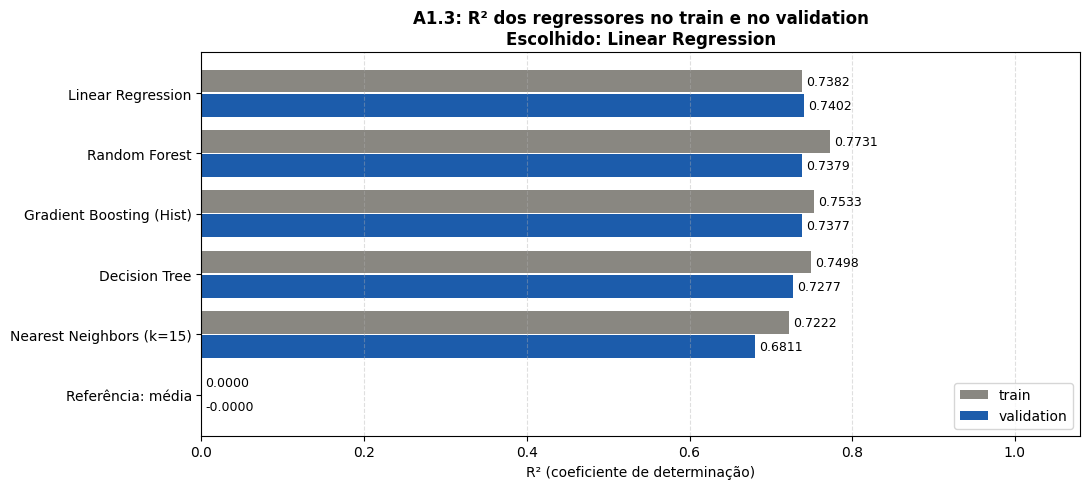

Regressor escolhido (maior R² no validation): Linear Regression


In [22]:
resultado_A1_3 = AtividadeA1_3()

### Qual regressor escolhi e por quê

*   Comparei 5 regressores com uma referência que sempre prevê o gasto médio. Treinei todos no train e medi no validation. O test ficou guardado para a avaliação final.
*   **O escolhido foi a Linear Regression, com R² de 0,7402 no validation**: ela explica 74% da variação do gasto por nota fiscal. O erro típico (RMSE) caiu de R\$ 841,65 na referência para R\$ 429,01, quase pela metade. O erro absoluto médio (MAE) ficou em R\$ 280,09.
*   Os modelos mais complexos não superaram a reta:

    | Regressor | R² no validation |
    |---|---|
    | Random Forest | 0,7379 |
    | Gradient Boosting | 0,7377 |
    | Decision Tree | 0,7277 |
    | Nearest Neighbors | 0,6811 (o pior) |

    Isso mostra que a relação do gasto com as variáveis é essencialmente linear. Não há curvas nem interações escondidas que as árvores consigam aproveitar.
*   A Linear Regression é também a única **sem sinal de overfitting**: o R² no validation (0,7402) é até um pouco maior que no train (0,7382). O Random Forest perde 0,035 do train para o validation, e o Nearest Neighbors perde 0,041. Ou seja, os dois decoraram parte do train.
*   Ela também é a mais fácil de explicar aos gestores e a mais rápida: treinou em 0,2 segundo, contra 203 segundos do Random Forest.
*   *   Todos os modelos param perto de 0,74. O diagnóstico da Atividade A1.4.2 mostra o motivo: o gasto de cada nota é a renda multiplicada por uma fração sorteada entre 4% e 18%, e nenhuma variável da base indica qual fração será usada. Por isso, 0,74 é o máximo que qualquer modelo consegue com estes dados.

Maior diferença entre os coeficientes do scikit-learn e do statsmodels: 9.77e-13
Intercepto: R$ 824.57 (gasto previsto para o perfil de referência, com as numéricas na média)
Variáveis significativas a 5%: 1 de 26


,coeficiente (R$),IC inferior,IC superior,p-valor (%),significativa a 5%
variável,,,,,
RENDA BRUTO (R$),720.6550,712.9607,728.3492,0.0000,True
REGIÃO_NORTE,14.2552,-3.0908,31.6012,10.7240,False
TIPO DA CONTA_PRIME,12.0647,-5.5256,29.6551,17.8857,False
ESTADO CIVIL_DESQUITADO(A) / VIÚVO(A),-7.1733,-15.7149,1.3683,9.9764,False
REGIÃO_SUDESTE,4.9445,-3.0007,12.8896,22.2564,False
REGIÃO_SUL,3.8636,-5.4694,13.1966,41.7150,False
REGIÃO_NORDESTE,-2.3408,-14.2281,9.5464,69.9529,False
SEXO_MASCULINO,-1.8990,-8.6057,4.8078,57.8932,False
MEAN: ash,1.7572,-0.4936,4.0080,12.5979,False


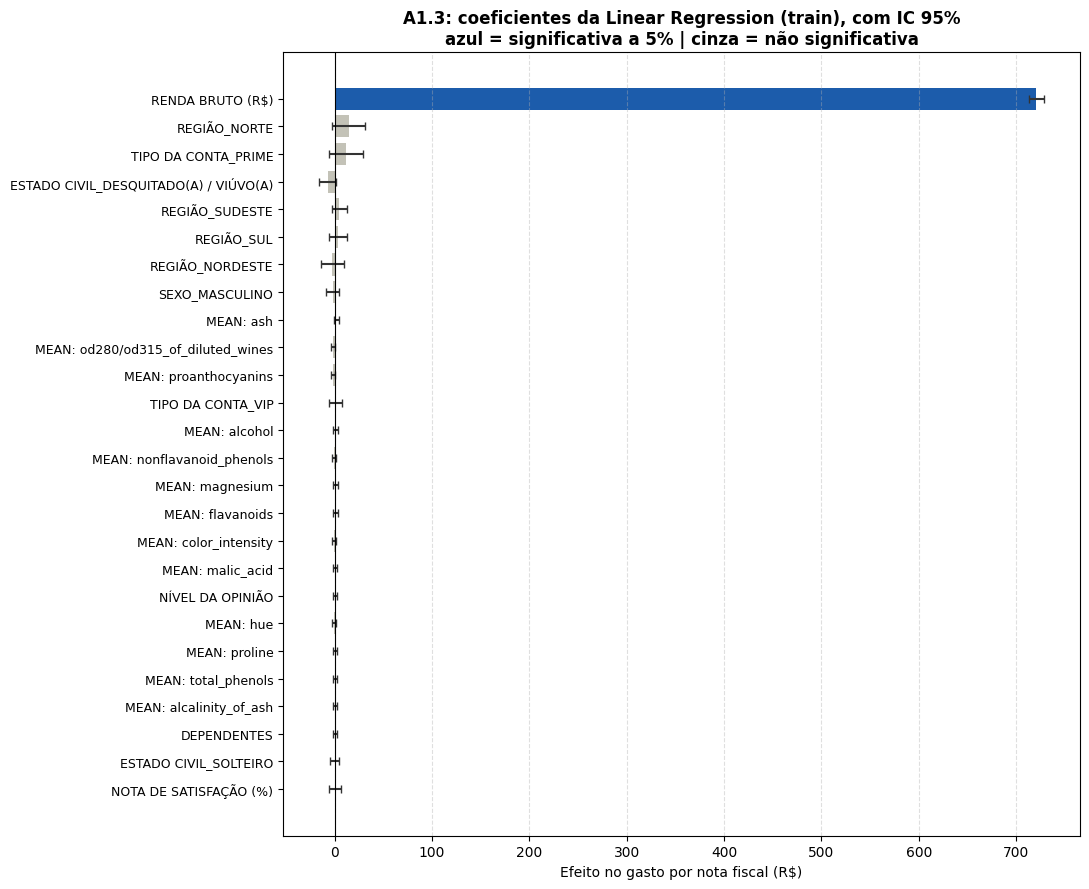

In [23]:
coeficientes_A1_3 = coeficientes_regressao()

### O que os coeficientes mostram

*   A reta do statsmodels é a mesma do scikit-learn: a maior diferença entre os coeficientes foi de 0,000000000001.
*   **Só uma das 26 variáveis é significativa: a RENDA.** Cada desvio padrão a mais de renda soma **R\$ 720,66** ao gasto por nota fiscal (IC 95%: R\$ 712,96 a R\$ 728,35, p-valor < 0,01%).
*   **Depois que a renda entra no modelo, o tipo de conta não acrescenta nada.** Com a renda fixa, um cliente PRIME gasta só R\$ 12,06 a mais que um ESSENTIAL, e um VIP só R\$ 1,12 a mais. Nenhuma dessas diferenças é significativa (p-valores de 17,9% e 74,1%). A diferença de gasto entre os tipos de conta que vimos na Parte 1 (o PRIME gasta 5,2 vezes o ESSENTIAL) vem da renda: o PRIME gasta mais porque ganha mais, e não por ser PRIME.
*   Região, sexo, estado civil, dependentes, nível da opinião, nota de satisfação e as 13 medidas do vinho têm efeitos entre −R\$ 7,17 e +R\$ 14,26, todos com p-valor acima de 9%. Isso confirma o que a Parte 1 já indicava: o perfil demográfico e as características do vinho não mudam o quanto o cliente gasta.
*   O intercepto, **R\$ 824,57**, é o gasto previsto para o perfil de referência (ESSENTIAL, CENTRO-OESTE, FEMININO e CASADO) com renda e demais numéricas na média.
*   Para os gestores, a conclusão é direta: **para prever o tamanho de uma compra no UVVine, basta saber a renda do cliente.**

In [24]:
# Converto o efeito da renda para reais: quanto o gasto sobe a cada R$ 1.000 a mais de renda
escala = resultado_A1_1["preparador"].named_transformers_["normalizadas"]
desvio_renda = escala.scale_[NUMERICAS_BASE.index(RENDA)]
efeito = coeficientes_A1_3["coeficientes"].loc[RENDA, ["coeficiente (R$)", "IC inferior", "IC superior"]] / desvio_renda * 1000
print(f"Desvio padrão da renda no train: R$ {desvio_renda:,.2f}")
print(f"A cada R$ 1.000 a mais de renda, o gasto por nota sobe R$ {efeito.iloc[0]:,.2f} "
      f"(IC 95%: R$ {efeito.iloc[1]:,.2f} a R$ {efeito.iloc[2]:,.2f})")

Desvio padrão da renda no train: R$ 6,584.27
A cada R$ 1.000 a mais de renda, o gasto por nota sobe R$ 109.45 (IC 95%: R$ 108.28 a R$ 110.62)


*   Em reais, o desvio padrão da renda no train é de R\$ 6.584,27. Ou seja, **a cada R\$ 1.000 a mais de renda, o gasto por nota fiscal sobe R\$ 109,45** (IC 95%: R\$ 108,28 a R\$ 110,62). Na prática, o cliente destina perto de 11% de cada real a mais de renda ao clube.

### A1.3.1: Intervalo de confiança: Train

1. Validação cruzada no train (10 folds)


,R²,RMSE (R$),MAE (R$)
fold,,,
1,0.7447,434.5310,283.5393
2,0.7355,432.0495,280.8054
3,0.7403,435.3635,280.7842
4,0.7425,432.9266,281.4479
5,0.7315,428.3596,280.3014
6,0.7348,430.4429,280.0357
7,0.7301,434.4871,283.6492
8,0.7373,431.1364,279.4849
9,0.7427,428.1270,278.5681


,R²,RMSE (R$),MAE (R$)
média,0.7379,431.6258,280.8420
desvio,0.0049,2.6834,1.6520
mínimo,0.7301,428.1270,278.5681
máximo,0.7447,435.3635,283.6492



2. Intervalo de confiança de 95% (bootstrap das previsões fora do fold)


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
R²,0.7380,0.0015,0.7350,0.7409
RMSE (R$),431.6334,1.3807,428.9089,434.3277
MAE (R$),280.8420,0.8669,279.1256,282.5244


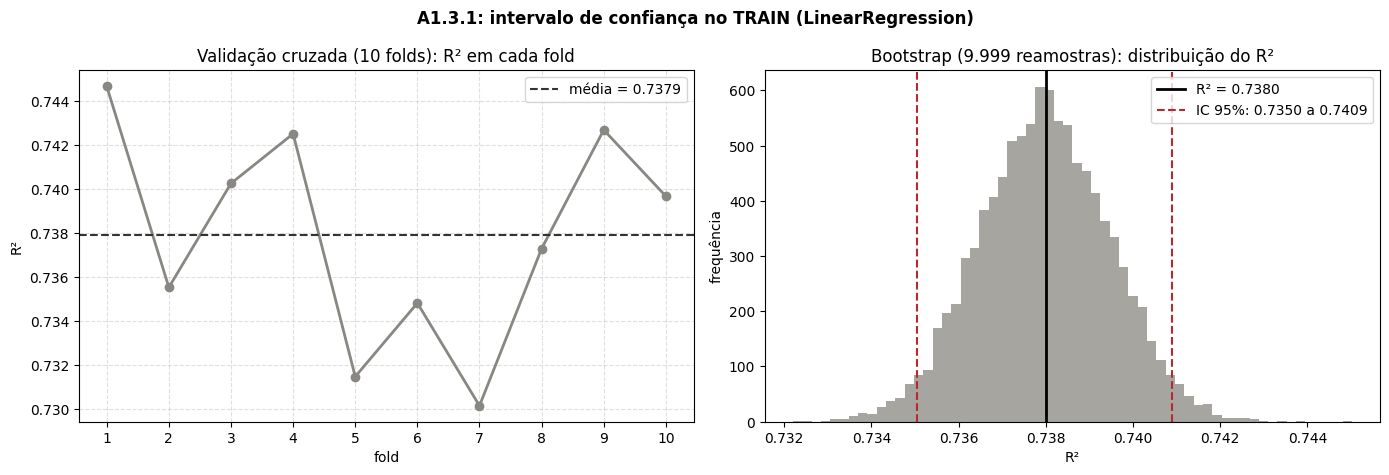

In [25]:
# Validação Cruzada e Análise Bootstrapping
resultado_A1_3_1 = AtividadeA1_3_1()

### O que a validação cruzada e o bootstrap mostraram no train

*   **Validação cruzada (10 folds):** dividi o train em 10 partes. Em cada rodada, o modelo treinou em 9 partes e foi medido na parte que ficou de fora.
    *   O R² variou entre 0,7301 e 0,7447, com **média de 0,7379** e desvio de apenas 0,0049.
    *   O erro típico (RMSE) ficou entre R\$ 428,13 e R\$ 435,36, e o MAE entre R\$ 278,57 e R\$ 283,65.
    *   Nenhum pedaço do train foge do padrão: a reta funciona igual em qualquer parte da amostra.
*   **Bootstrap (9.999 reamostras)** das previsões feitas fora do fold, ou seja, sempre com notas que o modelo não viu no treino:
    *   R² de **0,7380 (IC 95%: 0,7350 a 0,7409)**;
    *   RMSE de **R\$ 431,63 (IC 95%: R\$ 428,91 a R\$ 434,33)**;
    *   MAE de **R\$ 280,84 (IC 95%: R\$ 279,13 a R\$ 282,52)**.
    *   A distribuição do R² tem formato de sino, como prevê o Teorema Central do Limite.
*   O R² medido em notas novas (0,7380) é praticamente igual ao do train inteiro na A1.3 (0,7382). Isso mostra que o modelo não decorou o train: o desempenho dele vem de um padrão real, e não do acaso.

### A1.3.2: Intervalo de confiança: Validation

1. Intervalo de confiança de 95% no validation (modelo treinado no train)


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
R²,0.7402,0.0015,0.7372,0.7430
RMSE (R$),429.0052,1.3501,426.3988,431.6453
MAE (R$),280.0872,0.8533,278.4225,281.7579



2. Validação cruzada dentro do validation (10 folds)


,R²,RMSE (R$),MAE (R$)
fold,,,
1,0.7432,430.1158,281.3395
2,0.7406,433.6768,283.3759
3,0.7359,434.7197,282.5031
4,0.7399,429.5527,280.6749
5,0.7390,422.1704,275.2626
6,0.7298,433.3250,283.0406
7,0.7443,419.0221,273.8979
8,0.7454,433.8506,282.4858
9,0.7438,425.0212,278.5067


,R²,RMSE (R$),MAE (R$)
média,0.7401,429.0043,280.1101
desvio,0.0047,5.3808,3.2851
mínimo,0.7298,419.0221,273.8979
máximo,0.7454,434.7197,283.3759



3. Comparação dos intervalos: train x validation


,train (fora do fold),validation,intervalos se sobrepõem
R²,0.7380 (0.7350 a 0.7409),0.7402 (0.7372 a 0.7430),True
RMSE (R$),431.6334 (428.9089 a 434.3277),429.0052 (426.3988 a 431.6453),True
MAE (R$),280.8420 (279.1256 a 282.5244),280.0872 (278.4225 a 281.7579),True


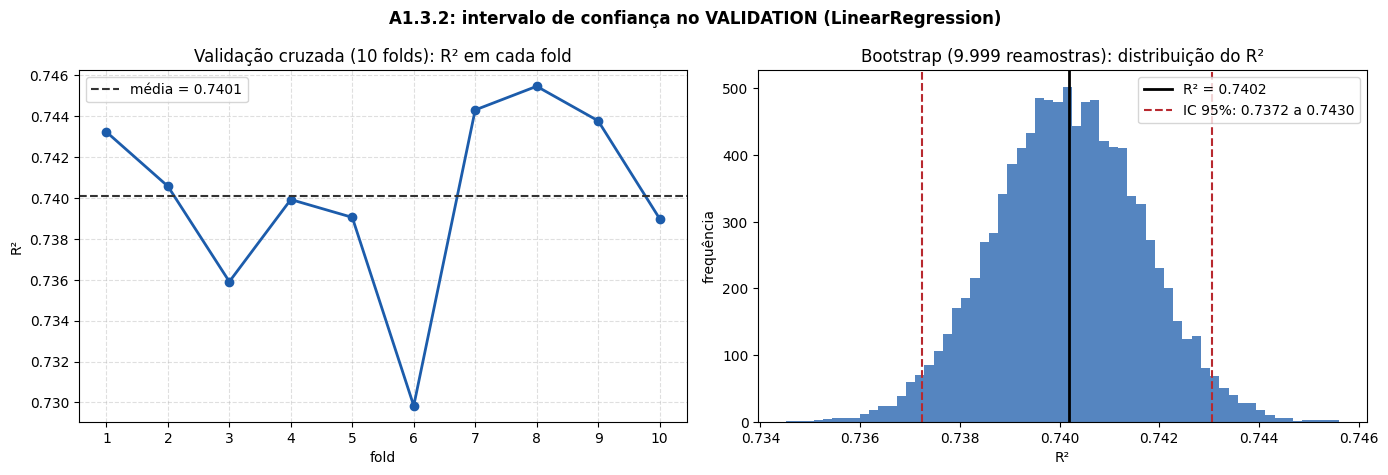

In [26]:
# Validação Cruzada e Análise Bootstrapping
resultado_A1_3_2 = AtividadeA1_3_2()

### O que a validação cruzada e o bootstrap mostraram no validation

*   **Modelo treinado no train, aplicado às 141.900 notas do validation:**

    | Métrica | Estimativa | IC 95% |
    |---|---|---|
    | R² | **0,7402** | 0,7372 a 0,7430 |
    | RMSE | R\$ 429,01 | R\$ 426,40 a R\$ 431,65 |
    | MAE | R\$ 280,09 | R\$ 278,42 a R\$ 281,76 |

*   **Validação cruzada dentro do validation:** aqui o modelo treinou do zero, numa amostra independente. O R² médio foi **0,7401** (de 0,7298 a 0,7454, com desvio de 0,0047). É o mesmo valor do modelo treinado no train. Ou seja, os coeficientes aprendidos no train funcionam tão bem quanto os que o próprio validation produziria.
*   **Os intervalos de confiança do train e do validation se sobrepõem nas três métricas** (R², RMSE e MAE). Não há diferença estatística entre o desempenho nos dados de treino e em dados novos. O modelo generaliza, sem overfitting.
*   A Linear Regression está validada para a avaliação final no conjunto de teste.

##Atividade A1.4 (4º Passo): Medir a acurácia (score) dos Modelos de Regressão:

### A1.4.1: Exibir os Coeficientes de Determinação ($R^2$)

* Conjunto de Treinamento: **R² = 0,7382** (IC 95%: 0,7352 a 0,7410)

* Conjunto de Validação: **R² = 0,7402** (IC 95%: 0,7372 a 0,7430)

* Conjunto de Teste: **R² = 0,7341** (IC 95%: 0,7311 a 0,7371)

In [27]:
# Train
resultado_A1_4_1_train = AtividadeA1_4_1("train")

Conjunto TRAIN: R² = 0.7382 (IC 95%: 0.7352 a 0.7410)


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
R²,0.7382,0.0015,0.7352,0.7410
RMSE (R$),431.5118,1.3802,428.7874,434.2034
MAE (R$),280.7560,0.8667,279.0366,282.4395


Métricas dentro de cada tipo de conta


,notas,R²,RMSE (R$),MAE (R$)
ESSENTIAL,84477.0,0.6482,192.2715,140.3455
VIP,33273.0,0.3732,377.8189,310.5867
PRIME,24150.0,0.3147,876.4110,730.8142


In [28]:
# Validation
resultado_A1_4_1_validation = AtividadeA1_4_1("validation")

Conjunto VALIDATION: R² = 0.7402 (IC 95%: 0.7372 a 0.7430)


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
R²,0.7402,0.0015,0.7372,0.7430
RMSE (R$),429.0052,1.3501,426.3988,431.6453
MAE (R$),280.0872,0.8533,278.4225,281.7579


Métricas dentro de cada tipo de conta


,notas,R²,RMSE (R$),MAE (R$)
ESSENTIAL,84539.0,0.6590,193.6857,140.4512
VIP,33187.0,0.3788,380.5601,313.9836
PRIME,24174.0,0.3214,866.2117,721.8742


In [29]:
# Teste
resultado_A1_4_1_test = AtividadeA1_4_1("test")

Conjunto TEST: R² = 0.7341 (IC 95%: 0.7311 a 0.7371)


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
R²,0.7341,0.0015,0.7311,0.7371
RMSE (R$),434.3464,1.3938,431.5558,437.0232
MAE (R$),282.3989,0.8854,280.6229,284.0936


Métricas dentro de cada tipo de conta


,notas,R²,RMSE (R$),MAE (R$)
ESSENTIAL,84665.0,0.6505,193.5637,140.9350
VIP,32875.0,0.3745,377.8324,311.7336
PRIME,24360.0,0.3106,880.9495,734.4788


### O que o R² mostrou nos três conjuntos

| Conjunto | R² (IC 95%) | RMSE (R\$) | MAE (R\$) |
|---|---|---|---|
| Train | 0,7382 (0,7352 a 0,7410) | 431,51 | 280,76 |
| Validation | 0,7402 (0,7372 a 0,7430) | 429,01 | 280,09 |
| **Test** | **0,7341 (0,7311 a 0,7371)** | **434,35** | **282,40** |

*   **No conjunto de teste, que o modelo nunca viu, a Linear Regression explica 73,4% da variação do gasto por nota fiscal**, com erro típico (RMSE) de R\$ 434,35 e erro absoluto médio de R\$ 282,40. Esse é o score final do regressor.
*   Os três conjuntos ficam no mesmo patamar. O R² do test fica 0,006 abaixo do validation, e os intervalos dos dois não se encostam por 0,0001. Mesmo assim, o test se sobrepõe ao intervalo do train e fica dentro da faixa dos folds da validação cruzada (0,7298 a 0,7454). Em reais, a diferença é de cerca de 1% no RMSE. Leio isso como variação de sorteio entre amostras, e não como perda de desempenho.
*   **Dentro de cada tipo de conta, o desempenho se repete nos três conjuntos:**

    | Tipo de conta | R² | RMSE |
    |---|---|---|
    | ESSENTIAL | 0,65 a 0,66 | R\$ 192 a R\$ 194 |
    | VIP | 0,37 a 0,38 | R\$ 378 a R\$ 381 |
    | PRIME | 0,31 a 0,32 | R\$ 866 a R\$ 881 |

    O R² dentro do estrato é menor que o geral porque a renda varia pouco dentro de cada tipo de conta. Boa parte dos 0,73 do geral vem de distinguir os estratos entre si.
*   **O erro cresce com o gasto, mas na mesma proporção:** o RMSE dividido pelo gasto médio dá 46% no ESSENTIAL, 41% no VIP e 41% no PRIME. O modelo erra uma fatia parecida do gasto em qualquer tipo de conta.

### A1.4.2: Plotagem dos Conjuntos - REAL ($y$) x ESTIMADO ($\hat{y}$):

* Conjunto de Treinamento: **R² = 0,7382**. A nuvem segue a linha real = estimado, com os raios do PRIME e as faixas horizontais do VIP e do ESSENTIAL. Nenhum tipo de conta tem viés: a média estimada é igual à média real nos três estratos (diferença de R\$ 0,00, por construção da reta).

* Conjunto de Validação: **R² = 0,7402**. O desenho é o mesmo do train. A média estimada fica muito perto da real:
    * ESSENTIAL: R\$ 1,68 abaixo (0,4%);
    * VIP: R\$ 6,55 abaixo (0,7%);
    * PRIME: R\$ 4,05 acima (0,2%).

* Conjunto de Teste: **R² = 0,7341**. O desenho é o mesmo, em dados que o modelo nunca viu. A média estimada fica muito perto da real:
    * ESSENTIAL: R\$ 1,06 abaixo (0,3%);
    * VIP: R\$ 1,63 abaixo (0,2%);
    * PRIME: R\$ 9,96 acima (0,5%).

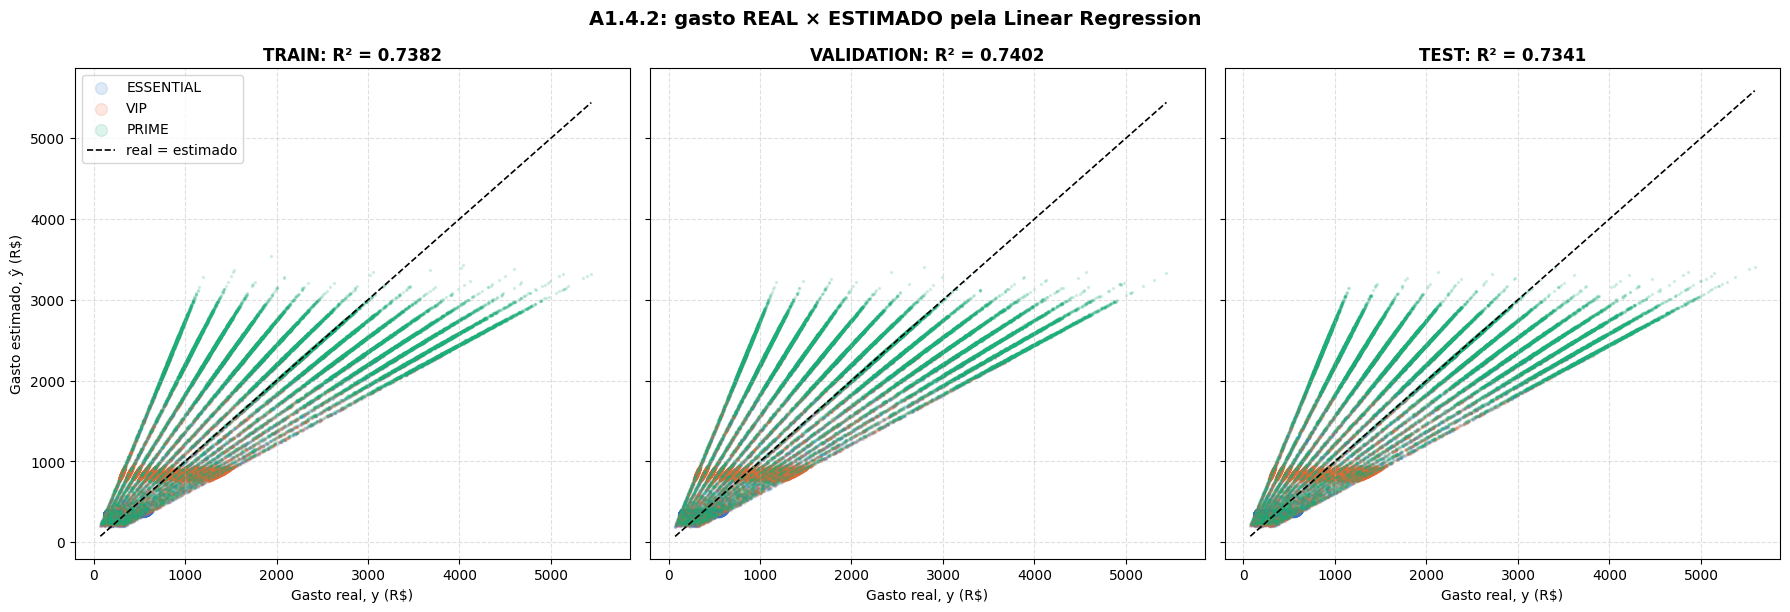

média real (R$)  média estimada (R$)  diferença (R$)
conjunto   tipo de conta                                                      
train      ESSENTIAL               413.85               413.85            0.00
           VIP                     918.14               918.14           -0.00
           PRIME                  2156.55              2156.55           -0.00
validation ESSENTIAL               418.02               416.34           -1.68
           VIP                     927.08               920.53           -6.55
           PRIME                  2149.54              2153.58            4.05
test       ESSENTIAL               415.88               414.82           -1.06
           VIP                     918.04               916.41           -1.63
           PRIME                  2141.29              2151.25            9.96

In [30]:
resultado_A1_4_2 = AtividadeA1_4_2()

### O que o gráfico real × estimado mostrou

*   Nos três conjuntos, a nuvem de pontos segue a linha real = estimado, com o mesmo formato no train, no validation e no test.
*   **O modelo não tem viés em nenhum tipo de conta.** A média estimada fica colada na média real em todos os estratos. No train a diferença é zero por construção. No validation e no test, a maior diferença é de R\$ 9,96, no PRIME do test, ou seja, 0,5% do gasto médio desse estrato.
*   Os pontos do PRIME formam **raios retos que saem da origem**. No VIP e no ESSENTIAL aparecem **faixas horizontais**, porque a renda varia pouco dentro desses estratos e a previsão fica quase constante, enquanto o gasto real varia. Esse desenho indica que o gasto de cada nota é uma fração fixa da renda do cliente. O diagnóstico a seguir confirma essa leitura.

1. Razão p no train: 30 valores distintos (arredondando em 3 casas)
   Os 20 valores mais comuns cobrem 71.63% das notas


,notas,%,% acumulado
p = TOTAL / RENDA,,,
0.041,5463,3.85,19.34
0.051,5371,3.79,38.39
0.060,4092,2.88,71.63
0.061,5502,3.88,7.76
0.070,4121,2.90,65.85
0.071,5489,3.87,11.63
0.081,5415,3.82,26.98
0.090,4126,2.91,62.95
0.091,5406,3.81,34.61



2. Razão p por tipo de conta


,média,mediana,desvio,mínimo,máximo
TIPO DA CONTA,,,,,
ESSENTIAL,0.1104,0.1106,0.0432,0.0401,0.1811
VIP,0.1099,0.1103,0.0431,0.0401,0.1810
PRIME,0.1102,0.1101,0.0432,0.0401,0.1811



3. Previsor só com a renda: ŷ = 0.1101 × RENDA (k aprendido no train)


,R² de ŷ = k × RENDA,R² da Linear Regression (26 variáveis)
conjunto,,
train,0.7381,0.7382
validation,0.7402,0.7402
test,0.7341,0.7341


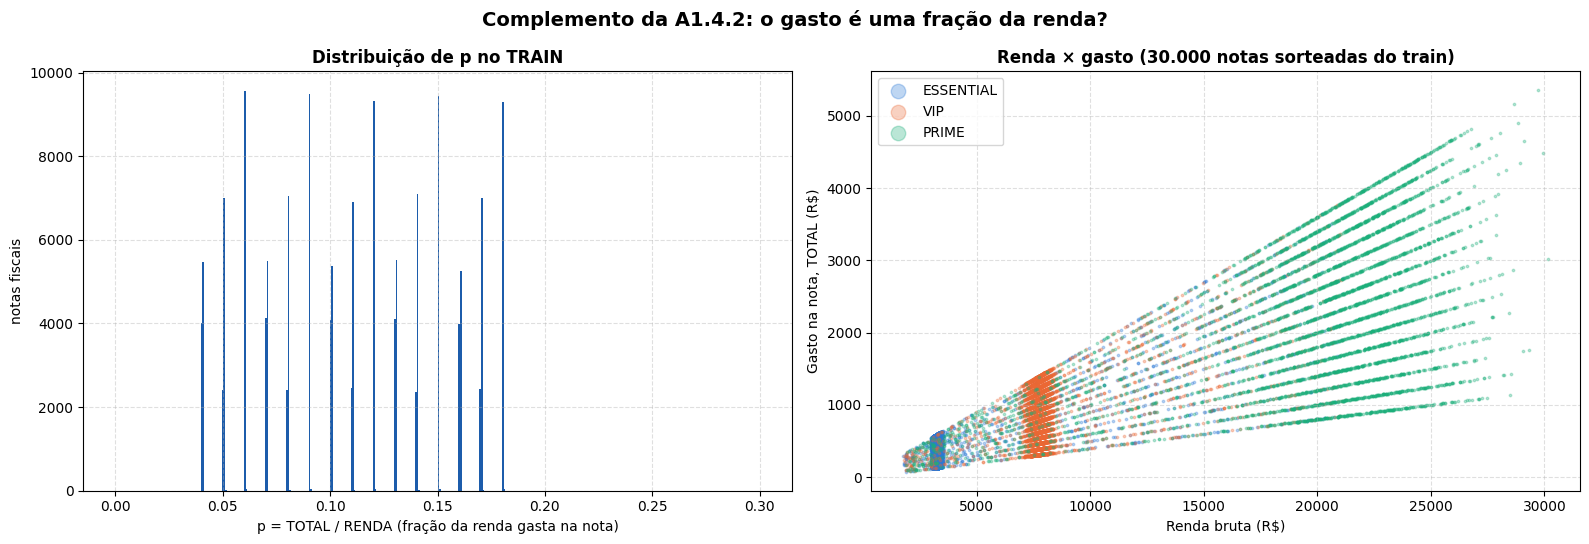

In [31]:
diagnostico_A1_4_2 = diagnostico_razao_gasto_renda()

### O que o diagnóstico mostrou: o gasto é uma fração sorteada da renda

*   Para cada nota fiscal, calculei p = TOTAL ÷ RENDA, a fração da renda gasta na nota. **O p só assume 15 valores: de 4% a 18%, de 1 em 1 ponto percentual.** Cada valor aparece em cerca de 1/15 das notas, como um sorteio com chances iguais. Nenhuma das 141.900 notas do train fica fora dessa grade. A tabela mostra 30 valores porque, com 3 casas decimais, cada fração se divide entre dois arredondamentos vizinhos (0,060 e 0,061, por exemplo).
*   **A fração não depende do tipo de conta.** A média de p é 11,04% no ESSENTIAL, 10,99% no VIP e 11,02% no PRIME, e os três estratos têm o mesmo desvio, o mesmo mínimo e o mesmo máximo. O PRIME não gasta uma parte maior da renda: gasta mais em reais porque ganha mais.
*   **Uma única multiplicação faz o trabalho do modelo inteiro.** Prever o gasto como ŷ = 0,1101 × RENDA dá R² de 0,7381 no train, 0,7402 no validation e 0,7341 no test. São os mesmos valores da Linear Regression com 26 variáveis, até a quarta casa decimal.
*   Isso explica tudo o que a regressão mostrou até aqui:
    *   **Nenhum modelo passa de 0,74:** qual das 15 frações cada nota vai usar é sorteado, e nenhuma variável da base informa esse sorteio. O melhor possível é prever a fração média (11%) vezes a renda, e é o que a reta faz. O teto de 0,74 vem desse sorteio, e não de falhas do modelo.
    *   **A reta empatou com as árvores:** a relação entre renda e gasto é uma proporção, ou seja, uma reta.
    *   **O erro cresce com o gasto na mesma proporção:** o desvio de p é cerca de 39% da média, e é por isso que o erro do modelo fica perto de 40% a 46% do gasto em todos os tipos de conta.
    *   **Os raios no gráfico real × estimado:** cada raio é uma das 15 frações.
*   O gráfico renda × gasto mostra um ponto que liga a regressão ao classificador. Há notas ESSENTIAL (azul) com renda de PRIME e notas PRIME (verde) com renda de ESSENTIAL. Os "outliers" que vimos na Parte 1 não são gastos estranhos, porque todos seguem a mesma regra de fração da renda. São **clientes cuja renda não combina com o tipo de conta**. Isso deve limitar a acurácia do classificador na Atividade A3.

### A1.4.3: Análise dos Resíduos: $\epsilon = y_{real} - y_{estimado}$

* Conjunto de Treinamento: resíduo médio de **R\$ 0,00** e desvio de R\$ 431,51. Simétrico (assimetria 0,01), mas com pico alto e caudas largas (curtose em excesso 3,81): 80,6% das notas ficam dentro de ±1 desvio, contra 68,3% numa normal. Normalidade rejeitada (Anderson-Darling, p-valor < 0,01%).

* Conjunto de Validação: resíduo médio de **R\$ 1,84** e desvio de R\$ 429,00. Simétrico (assimetria −0,01), com curtose em excesso de 3,75 e 80,4% das notas dentro de ±1 desvio. Normalidade rejeitada (p-valor < 0,01%).

* Conjunto de Teste: resíduo médio de **−R\$ 0,70** e desvio de R\$ 434,35. Simétrico (assimetria −0,02), com curtose em excesso de 3,81 e 80,6% das notas dentro de ±1 desvio. Normalidade rejeitada (p-valor < 0,01%).

1. Estatísticas dos resíduos (uma normal teria 68,3% dentro de ±1 desvio e 95,4% dentro de ±2)


,train,validation,test
média (R$),-0.0000,1.8445,-0.6981
desvio (R$),431.5133,429.0027,434.3473
mediana (R$),0.5553,1.2156,0.4028
assimetria,0.0054,-0.0133,-0.0171
curtose (excesso),3.8080,3.7465,3.8080
% dentro de ±1 desvio,80.5560,80.3904,80.5736
% dentro de ±2 desvios,92.2875,92.3080,92.2199
p-valor Anderson-Darling (%),0.0000,0.0000,0.0000



2. Resíduos por tipo de conta


média do resíduo (R$)  desvio do resíduo (R$)
train      ESSENTIAL                  -0.00                  192.27
           VIP                         0.00                  377.82
           PRIME                       0.00                  876.43
validation ESSENTIAL                   1.68                  193.68
           VIP                         6.55                  380.51
           PRIME                      -4.05                  866.22
test       ESSENTIAL                   1.06                  193.56
           VIP                         1.63                  377.83
           PRIME                      -9.96                  880.91

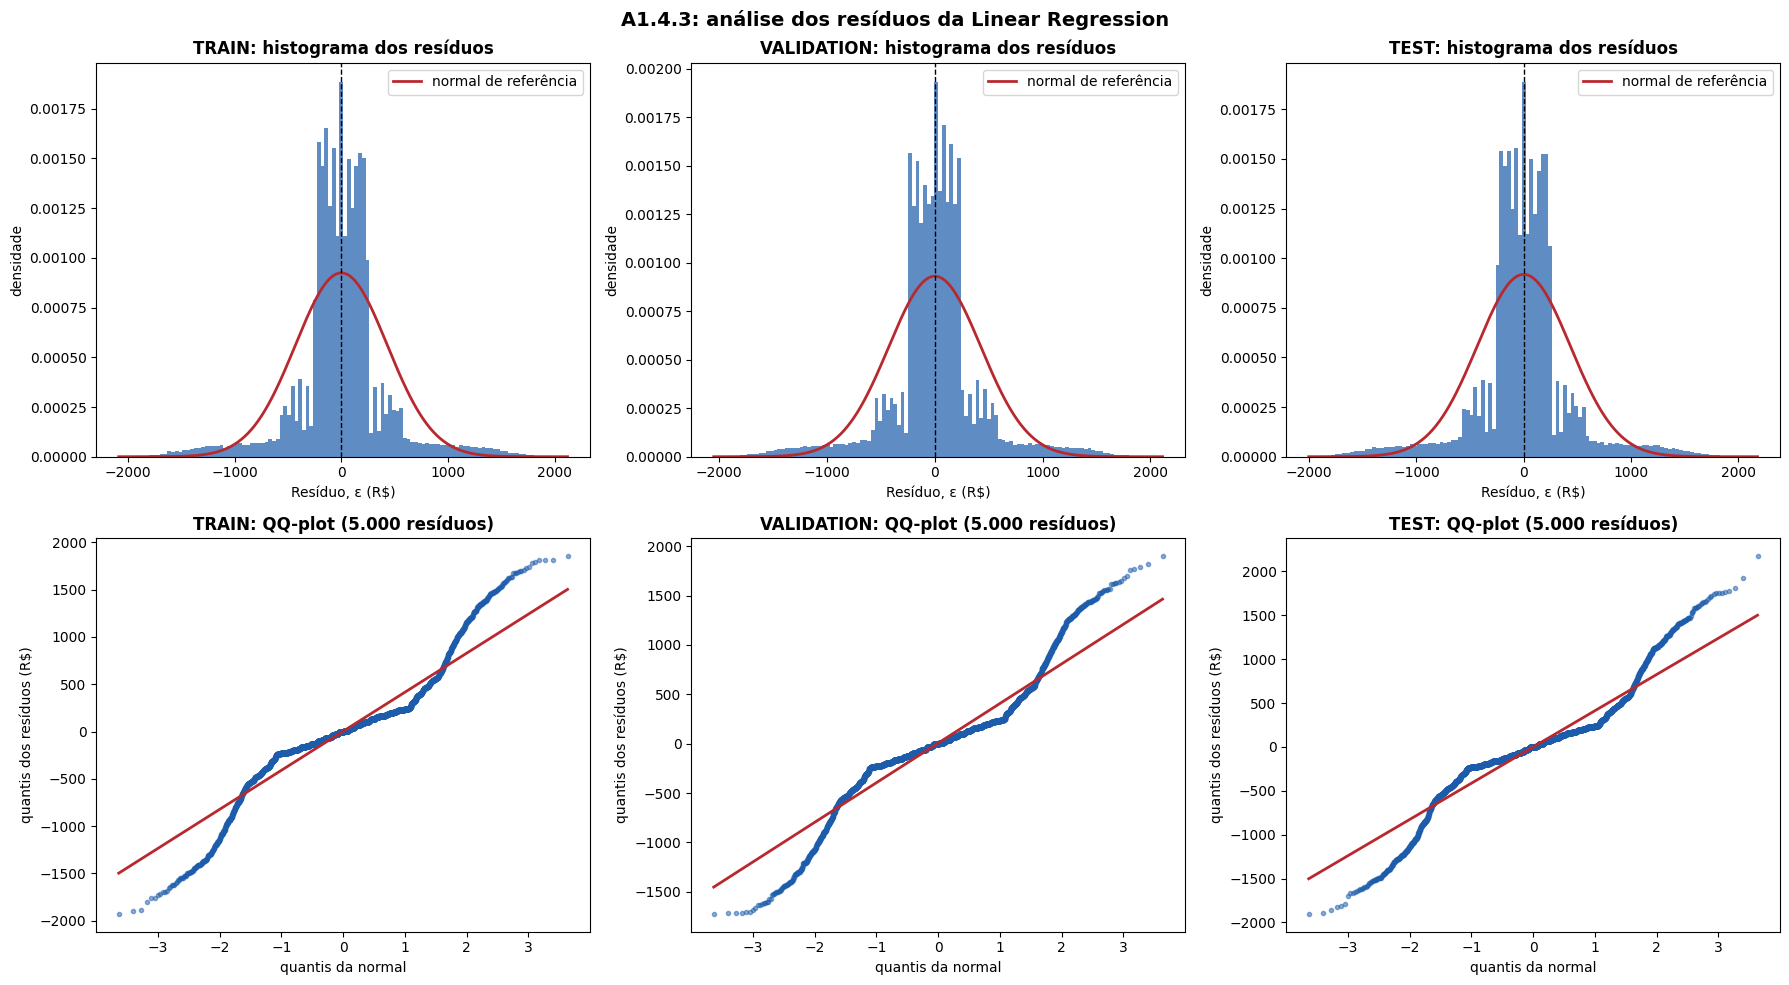

In [32]:
resultado_A1_4_3 = AtividadeA1_4_3()

### O que a análise dos resíduos mostrou

*   **O modelo não erra sistematicamente para nenhum lado.** O resíduo médio é praticamente zero nos três conjuntos (R\$ 0,00, R\$ 1,84 e −R\$ 0,70), diante de um desvio de cerca de R\$ 430. A mediana também fica perto de zero, e a assimetria é nula: o modelo superestima e subestima na mesma medida.
*   **Os resíduos não são normais, e o formato deles tem explicação exata.** Como o gasto é a renda vezes uma fração sorteada entre 4% e 18%, e o modelo prevê a fração média (11%), o resíduo de cada nota é **renda × (fração sorteada − 11%)**. A fração pode se afastar no máximo 7 pontos da média. Por isso, cada tipo de conta tem a sua faixa de erro:
    *   no **ESSENTIAL** (renda perto de R\$ 3.200), os erros ficam dentro de cerca de ±R\$ 225: é o bloco alto do centro do histograma;
    *   no **VIP** (renda perto de R\$ 7.800), os erros chegam a cerca de ±R\$ 550: são os degraus dos lados;
    *   no **PRIME** (renda perto de R\$ 22.000), os erros chegam a cerca de ±R\$ 1.500, e a mais de R\$ 2.000 nas rendas mais altas: são as caudas longas e baixas.
*   A soma dessas três faixas gera o pico alto e as caudas largas (curtose em excesso de 3,8). Há mais notas perto de zero do que numa normal (80,5% dentro de ±1 desvio, contra 68,3%) e também mais notas longe (7,7% fora de ±2 desvios, contra 4,6%). O QQ-plot em forma de "S" mostra a mesma coisa: centro achatado e pontas que fogem da reta.
*   O desvio do resíduo acompanha a renda de cada estrato: cerca de R\$ 193 no ESSENTIAL, R\$ 378 no VIP e R\$ 876 no PRIME, igual nos três conjuntos.
*   **A falta de normalidade não compromete os resultados.** A previsão não depende dela. Os intervalos de confiança do R² vieram do bootstrap, que não supõe normalidade. Os intervalos dos coeficientes usaram erros padrão robustos (HC3) e se apoiam no Teorema Central do Limite, válido com 141.900 notas.

### A1.4.4: JOINT: Resíduos ($\epsilon$) vs Valores Estimado ($\hat{y}$)

* Conjunto de Treinamento: os resíduos formam um **leque de raios que saem da origem**, simétrico em torno de zero. O desvio do resíduo cresce de **R\$ 136,22** na faixa mais baixa de gasto estimado (até R\$ 355) para **R\$ 866,51** na mais alta (acima de R\$ 1.055).

* Conjunto de Validação: o mesmo leque. O desvio cresce de **R\$ 135,75** na faixa mais baixa para **R\$ 855,93** na mais alta.

* Conjunto de Teste: o mesmo leque, em dados que o modelo nunca viu. O desvio cresce de **R\$ 136,20** na faixa mais baixa para **R\$ 871,60** na mais alta.

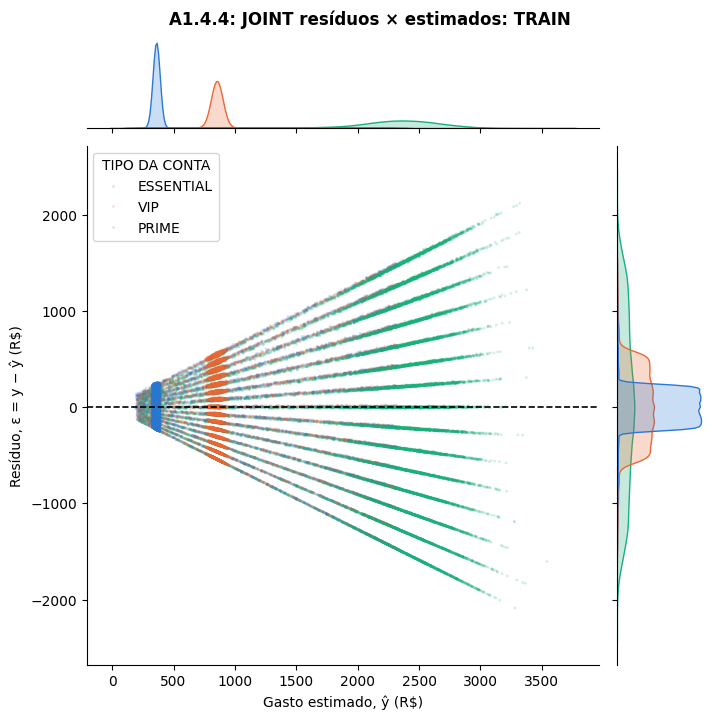

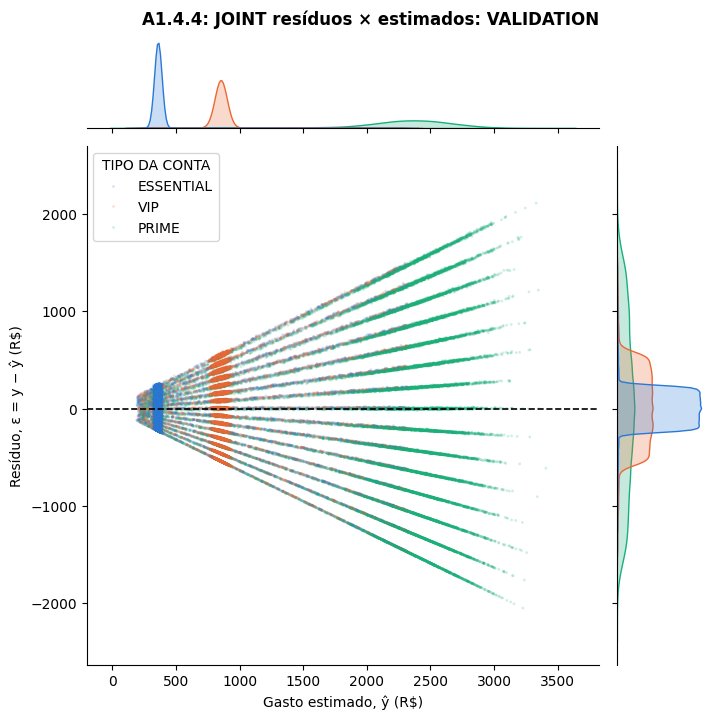

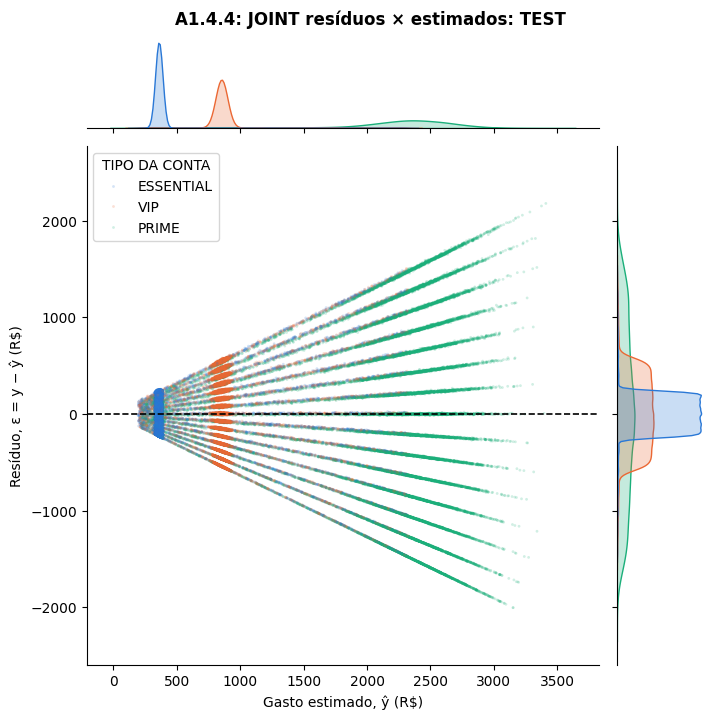

Desvio dos resíduos (R$) por faixa de gasto estimado (faixas = quintis de ŷ no train)


,train: notas,train: desvio (R$),validation: notas,validation: desvio (R$),test: notas,test: desvio (R$)
faixa de ŷ,,,,,,
1ª faixa: até R$ 355,28380,136.22,28594,135.75,28397,136.20
2ª faixa: R$ 355 a R$ 364,28380,140.99,27850,140.32,28308,141.09
3ª faixa: R$ 364 a R$ 802,28380,168.41,28503,169.02,28535,167.49
4ª faixa: R$ 802 a R$ 1.055,28380,336.76,28322,338.79,28153,338.33
5ª faixa: acima de R$ 1.055,28380,866.51,28631,855.93,28507,871.60


In [33]:
resultado_A1_4_4 = AtividadeA1_4_4()

### O que o gráfico JOINT mostrou

*   **Os resíduos não formam curva:** os raios ficam distribuídos por igual acima e abaixo de zero ao longo de todo o eixo do gasto estimado. A reta não deixa nenhum padrão não linear para trás, o que confirma que uma relação linear é a forma certa para estes dados.
*   **Cada raio é uma das 15 frações da renda.** O resíduo de cada nota é o gasto estimado multiplicado por (fração sorteada ÷ 11% − 1). As 7 frações acima de 11% formam os raios de cima, e as 7 abaixo formam os de baixo. A fração de 11%, igual à média, forma o raio horizontal colado em zero.
*   *   **O espalhamento cresce com o gasto estimado (heterocedasticidade), em formato de funil.** Dividindo as notas em 5 faixas de gasto estimado, o desvio do resíduo passa por R\$ 136, R\$ 141, R\$ 168, R\$ 337 e R\$ 867 no train, com valores praticamente iguais no validation e no test. As duas primeiras faixas são quase só ESSENTIAL, a quarta é VIP, e a última é PRIME. O erro acompanha a renda, e por isso fica sempre perto de 40% do gasto.
*   As margens do gráfico separam os tipos de conta:
    *   o **ESSENTIAL** é um pico estreito perto de R\$ 355 de gasto estimado, com resíduos dentro de ±R\$ 225;
    *   o **VIP** fica perto de R\$ 850, com resíduos de até ±R\$ 550;
    *   o **PRIME** se espalha entre R\$ 1.100 e R\$ 3.500, com resíduos de até ±R\$ 2.000.
*   Pontos azuis e laranja ao longo dos raios do PRIME são clientes ESSENTIAL e VIP com renda alta, os mesmos que apareceram no diagnóstico da A1.4.2.
*   A heterocedasticidade não distorce as previsões, que continuam sem viés. Ela só pede cuidado com os erros padrão, e por isso os coeficientes usaram erros padrão robustos (HC3). Para os gestores, o recado é que **a previsão de gasto deve ser lida com margem proporcional**: cerca de ±40% do valor previsto, e não um valor fixo em reais.

##Atividade A1.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

1. Desempenho na população inteira (621.823 notas)


,notas,R²,RMSE (R$),MAE (R$),erro médio (R$)
GERAL,621823.0,0.7368,432.4658,281.6047,-0.3956
ESSENTIAL,369816.0,0.6534,193.1284,140.6279,-1.5262
VIP,145559.0,0.3694,378.0834,312.1195,-0.7842
PRIME,106448.0,0.3141,876.0590,729.6525,4.0636



2. R² em 200 amostras aleatórias do tamanho ideal, sorteadas da população


,valor
amostras,200.0000
notas por amostra,141900.0000
R² médio,0.7367
desvio do R²,0.0013
"percentil 2,5%",0.7341
"percentil 97,5%",0.7392
mínimo,0.7327
máximo,0.7399
% das amostras com R² abaixo do test,2.5000



3. R² em todos os conjuntos (IC 95% por bootstrap; nas amostras, percentis 2,5% e 97,5%)


,R²,inferior,superior
conjunto,,,
train,0.7382,0.7352,0.7410
validation,0.7402,0.7372,0.7430
test,0.7341,0.7311,0.7371
amostras da população,0.7367,0.7341,0.7392
população inteira,0.7368,NaN,NaN


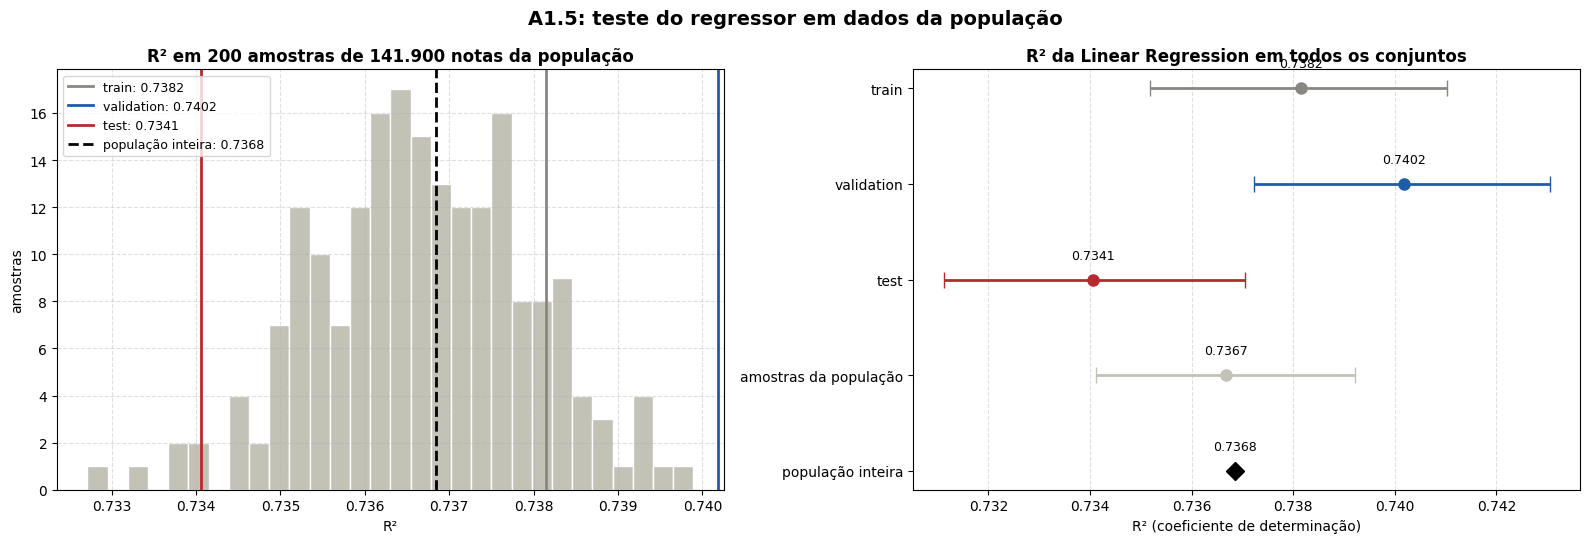


4. Exemplos: 10 notas sorteadas da população


,tipo de conta,renda (R$),gasto real (R$),gasto estimado (R$),erro (R$),erro (%),fração da renda gasta (%)
exemplo,,,,,,,
1,VIP,2876.40,145.81,320.58,174.77,119.86,5.07
2,ESSENTIAL,3318.77,300.68,368.48,67.80,22.55,9.06
3,ESSENTIAL,10119.78,1013.97,1109.54,95.57,9.43,10.02
4,ESSENTIAL,3303.63,134.14,363.74,229.60,171.17,4.06
5,VIP,7186.57,648.78,779.74,130.96,20.18,9.03
6,ESSENTIAL,3210.88,483.62,353.95,-129.67,-26.81,15.06
7,ESSENTIAL,3226.07,550.42,359.83,-190.59,-34.63,17.06
8,PRIME,17873.15,1253.11,1968.32,715.21,57.08,7.01
9,ESSENTIAL,3314.17,134.56,360.83,226.27,168.16,4.06


In [34]:
resultado_A1_5 = AtividadeA1_5()

### O que o teste na população mostrou

*   **Na população inteira, ou seja, nas 621.823 notas que não entraram em nenhum conjunto, a Linear Regression teve R² de 0,7368**, com RMSE de R\$ 432,47, MAE de R\$ 281,60 e erro médio de apenas −R\$ 0,40. Por tipo de conta, os números repetem os dos outros conjuntos:

    | Tipo de conta | R² | RMSE (R\$) |
    |---|---|---|
    | ESSENTIAL | 0,65 | 193 |
    | VIP | 0,37 | 378 |
    | PRIME | 0,31 | 876 |

*   Sorteei 200 amostras aleatórias do tamanho ideal (141.900 notas) da população. **O R² variou entre 0,7341 e 0,7392 em 95% delas**, com média de 0,7367 e desvio de 0,0013. Esse desvio bate com a conta: é o erro padrão do bootstrap (0,0015) corrigido pelo tamanho finito da população, 0,0015 × √(1 − 141.900 ÷ 621.823) ≈ 0,0013.
*   **Isso explica a pequena diferença entre o validation e o test.** Os dois estão nas pontas da variação natural, um de cada lado do valor da população:
    *   o validation (0,7402) ficou acima de todas as 200 amostras;
    *   o test (0,7341) ficou exatamente no percentil 2,5%;
    *   o train (0,7382) ficou no meio.

    Nenhum deles indica problema no modelo. A melhor estimativa do desempenho real é a da população: **R² ≈ 0,737**.
*   **As 10 notas de exemplo mostram como o modelo se comporta na prática:**
    *   quando o cliente gasta perto de 10% a 11% da renda, o erro é pequeno (exemplo 3: erro de 9%);
    *   quando gasta só 4% da renda, o modelo superestima em mais de 160% (exemplos 4 e 9);
    *   quando gasta 17%, o modelo subestima em cerca de 35% (exemplo 7).

    Os exemplos 1 e 3 são clientes com renda que não combina com o tipo de conta: um VIP com renda de R\$ 2.876 e um ESSENTIAL com renda de R\$ 10.120. O modelo acerta os dois mesmo assim, porque olha a renda, e não o tipo de conta.

## RELATÓRIO PARCIAL - MODELO DE REGRESSÃO

Fazer aqui o **RRELATÓRIO PARCIAL - MODELO DE REGRESSÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ **Objetivo:** prever o gasto de cada nota fiscal, TOTAL (R\$), a partir do perfil do cliente. Usei os conjuntos da Parte 1, cada um com o tamanho ideal de 141.900 notas: treinei no train, escolhi o modelo no validation e guardei o test para a avaliação final. Depois, testei o modelo nas 621.823 notas restantes da população.

*   ✅ **Modelo escolhido: Linear Regression.** Comparei 6 opções (média, Linear Regression, Decision Tree, Random Forest, Gradient Boosting e Nearest Neighbors). A reta teve o maior R² no validation (0,7402), não mostrou overfitting e treina em menos de 1 segundo. Os modelos de árvore empataram ou ficaram abaixo, o que mostra que a relação é linear.

*   ✅ **Score final:** a reta explica cerca de **74% da variação do gasto** por nota:

    | Conjunto | R² | IC 95% | RMSE (R\$) |
    |---|---|---|---|
    | Train | 0,7382 | 0,7352 a 0,7410 | 431,51 |
    | Validation | 0,7402 | 0,7372 a 0,7430 | 429,01 |
    | **Test** | **0,7341** | **0,7311 a 0,7371** | **434,35** |
    | População (621.823 notas) | 0,7368 | — | 432,47 |

    Validação cruzada (10 folds) e bootstrap (9.999 reamostras) confirmaram a estabilidade. O erro absoluto médio fica perto de R\$ 281 por nota.

*   ✅ **O que determina o gasto é a renda, e só ela.** Das 26 variáveis, só a renda é significativa: **cada R\$ 1.000 a mais de renda soma R\$ 109,45 ao gasto por nota** (IC 95%: R\$ 108,28 a R\$ 110,62). Com a renda fixa, o tipo de conta não muda o gasto. Região, sexo, estado civil, dependentes, opinião, nota de satisfação e as 13 características do vinho também não mudam.

*   ✅ **A regra por trás dos dados:** cada nota gasta uma fração da renda do cliente, sorteada entre 15 valores (de 4% a 18%), com a mesma chance e da mesma forma nos três tipos de conta. Prever "11% da renda" dá o mesmo R² do modelo completo. Como nenhuma variável indica qual fração será usada, **0,74 é o teto para estes dados**, e o modelo já chegou nele.

*   ✅ **Precisão:** o modelo não tem viés. O erro médio é praticamente zero em todos os tipos de conta, então as previsões de faturamento total são confiáveis. Para uma nota individual, o erro é proporcional ao valor: cerca de ±40% do gasto previsto, ou seja, ±R\$ 190 no ESSENTIAL, ±R\$ 380 no VIP e ±R\$ 880 no PRIME.

*   ✅ **Achado para os gestores:** o PRIME gasta 5,2 vezes mais que o ESSENTIAL, mas não porque é PRIME, e sim porque ganha mais. Todos os tipos de conta destinam em média a mesma fatia da renda (11%) a cada compra. A satisfação também não aumenta o gasto: clientes satisfeitos e insatisfeitos gastam a mesma fração da renda.

*   ✅ **Recomendações:**
    1.  Usar a renda do cliente, e não o tipo de conta, para projetar o faturamento e definir metas por cliente.
    2.  Investigar o que leva um cliente a gastar 4% ou 18% da renda em uma compra (ocasião, promoções, frequência, canal). A base atual não tem essa informação, e é ela que pode levar a previsão além de 74%.
    3.  Revisar a classificação dos clientes: há clientes ESSENTIAL com renda de PRIME e o contrário. Isso será medido no classificador (Atividade A3).

#Atividade A2: Modelo de Clusterização

##Atividade A2.1 (1º Passo): Normalizar - Mapear - Discretizar

In [35]:
resultado_A2_1 = AtividadeA2_1()

1. Discretização da OPINIÃO DO CLIENTE (train)


,satisfação,notas no train,%
nível,,,
1,Muito insatisfeito,1441,1.02
2,Insatisfeito,5716,4.03
3,Indiferente,21270,14.99
4,Satisfeito,109210,76.96
5,Muito satisfeito,4263,3.00



2. Tratamento de cada coluna


,tratamento,vira
coluna,,
DEPENDENTES,"normalizada (média 0, desvio 1)",DEPENDENTES
RENDA BRUTO (R$),"normalizada (média 0, desvio 1)",RENDA BRUTO (R$)
OPINIÃO DO CLIENTE,mapeada para 1 a 5 e normalizada,NÍVEL DA OPINIÃO
NOTA DE SATISFAÇÃO (%),"normalizada (média 0, desvio 1)",NOTA DE SATISFAÇÃO (%)
MEAN: alcohol,"normalizada (média 0, desvio 1)",MEAN: alcohol
MEAN: malic_acid,"normalizada (média 0, desvio 1)",MEAN: malic_acid
MEAN: ash,"normalizada (média 0, desvio 1)",MEAN: ash
MEAN: alcalinity_of_ash,"normalizada (média 0, desvio 1)",MEAN: alcalinity_of_ash
MEAN: magnesium,"normalizada (média 0, desvio 1)",MEAN: magnesium



3. Conferência da normalização e tamanho dos conjuntos


,linhas,variáveis de entrada,maior |média| das normalizadas,menor desvio das normalizadas,maior desvio das normalizadas
train,141900.0,24.0,0.0000,1.0000,1.0000
validation,141900.0,24.0,0.0086,0.9956,1.0083
test,141900.0,24.0,0.0127,0.9941,1.0123
populacao,621823.0,24.0,0.0087,0.9953,1.0051



Variáveis de entrada (X): 24 | saída (y): não existe na clusterização


### O que a preparação mostrou

*   Usei a mesma preparação da regressão: a opinião foi discretizada na escala de 1 a 5, com as mesmas proporções da A1.1. Região, sexo e estado civil viraram colunas 0/1, e as numéricas foram normalizadas com médias e desvios aprendidos só no train.
*   Saíram três colunas: a NOTA FISCAL, por ser só um identificador, e o **TOTAL (R\$)** e o **TIPO DA CONTA**, para não haver vazamento de informação. Assim, os grupos são formados sem que o modelo conheça o gasto nem o tipo de conta, e esses dois servem depois para avaliar se os grupos fazem sentido.
*   O modelo recebe **24 variáveis de entrada**: 17 numéricas e 7 colunas 0/1. Validation, test e população têm a mesma escala do train: as médias ficaram no máximo a 0,013 desvio de zero, e os desvios ficaram entre 0,994 e 1,012.

##Atividade A2.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [36]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
resultado_A2_2 = AtividadeA2_2()

,"X (linhas, colunas)",tipo de X,y,referência guardada à parte
conjunto,,,,
train,"(141900, 24)",ndarray,não existe,"TIPO DA CONTA, TOTAL (R$), RENDA BRUTO (R$)"
validation,"(141900, 24)",ndarray,não existe,"TIPO DA CONTA, TOTAL (R$), RENDA BRUTO (R$)"
test,"(141900, 24)",ndarray,não existe,"TIPO DA CONTA, TOTAL (R$), RENDA BRUTO (R$)"
populacao,"(621823, 24)",ndarray,não existe,"TIPO DA CONTA, TOTAL (R$), RENDA BRUTO (R$)"


### O que a separação mostrou

*   Na clusterização **não existe saída (y)**: o modelo forma os grupos olhando só para a entrada X, que tem 24 colunas em todos os conjuntos (141.900 linhas em train, validation e test e 621.823 na população), em formato ndarray.
*   O tipo de conta, o gasto e a renda de cada nota foram guardados à parte. Eles não entram no modelo e servem só para descrever e interpretar os clusters nas próximas atividades.

##Atividade A2.3 (3º Passo): Aplicar o Método do Cotovelo

todas (24): pronto
perfil do cliente (11): pronto
só a renda (1): pronto

1. Inércia que sobra em relação a k = 1 (%)


,todas (24),perfil do cliente (11),só a renda (1)
k,,,
1,100.00,100.00,100.00
2,93.85,77.36,13.79
3,90.12,63.67,4.63
4,87.24,52.79,2.25
5,84.44,41.44,1.24
6,82.67,38.40,0.86
7,80.45,35.72,0.64
8,79.17,33.63,0.50
9,78.06,32.41,0.42


2. Cotovelo de cada grupo de variáveis


,k do cotovelo
todas (24),5
perfil do cliente (11),5
só a renda (1),2


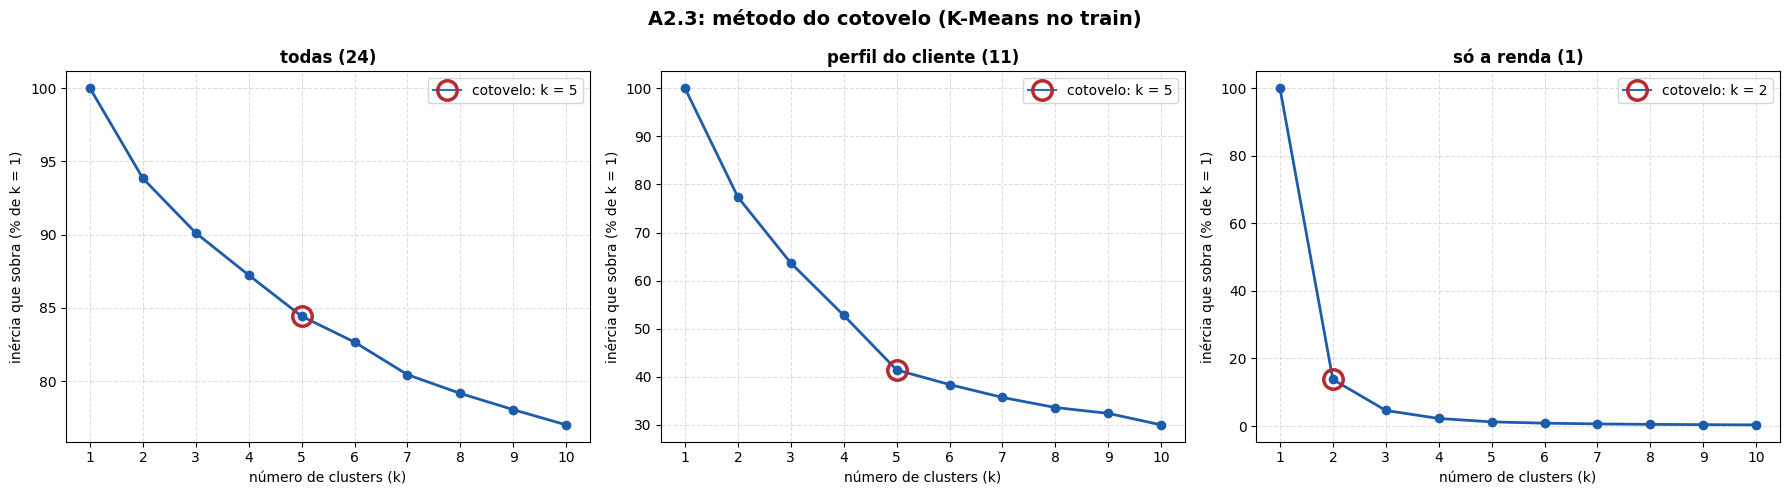

In [37]:
resultado_A2_3 = AtividadeA2_3()

### O que o método do cotovelo mostrou

*   **Com as 24 variáveis, não há cotovelo de verdade.** A curva desce quase em linha reta: com 10 clusters ainda sobram 77% da inércia inicial. O ponto que a regra marca, k = 5 (84,4%), é só uma leve mudança de inclinação. Esse é o comportamento típico de dados sem grupos naturais: cada cluster novo apenas "fatia" um pouco mais a nuvem. As 13 medidas do vinho, independentes entre si e sem relação com o cliente (como vimos na Parte 1), espalham as notas de forma uniforme e escondem qualquer estrutura.
*   **Sem as medidas do vinho (perfil do cliente, 11 variáveis), aparece um cotovelo em k = 5.** A inércia cai rápido até 41,4% e depois quase não muda, ficando em 30,0% com k = 10. Esse perfil tem variáveis com poucos valores possíveis (dependentes de 0 a 4, nível da opinião de 1 a 5, nota de satisfação quase constante) e a renda com três faixas. O K-Means aproveita esses degraus para formar grupos.
*   **Só com a renda, a estrutura é muito forte.** Dois clusters já eliminam 86% da inércia (sobram 13,8%), e três eliminam 95% (sobram 4,6%). Depois disso, os ganhos são mínimos. A regra marca k = 2 porque o maior salto é separar as rendas altas (PRIME) do resto. Mas o terceiro cluster ainda reduz a inércia restante em dois terços, o que indica que k = 3, uma faixa para cada tipo de conta, também é candidato.
*   A inércia só mostra quanto cada cluster novo ajuda, e não quão separados os clusters estão. Por isso, a escolha final do grupo de variáveis e do k fica com o método da silhueta, na A2.4.

##Atividade A2.4 (4º Passo): Aplicar o Método da Silhueta

todas (24): pronto
perfil do cliente (11): pronto
só a renda (1): pronto

1. Silhueta média (3 sorteios de 10.000 notas do train)


,todas (24),perfil do cliente (11),só a renda (1)
k,,,
2,0.1276,0.3911,0.8309
3,0.0734,0.3127,0.8690
4,0.0462,0.3092,0.8482
5,0.0499,0.3341,0.8545
6,0.0457,0.2524,0.8541
7,0.0460,0.2498,0.8531
8,0.0440,0.2485,0.8525
9,0.0436,0.2523,0.8445
10,0.0438,0.2701,0.8266


2. Desvio da silhueta entre os sorteios


,todas (24),perfil do cliente (11),só a renda (1)
k,,,
2,0.0008,0.0022,0.0018
3,0.0014,0.0017,0.0016
4,0.0010,0.0021,0.0014
5,0.0006,0.0018,0.0019
6,0.0001,0.0022,0.0023
7,0.0004,0.0015,0.0008
8,0.0001,0.0016,0.0019
9,0.0004,0.0016,0.0009
10,0.0007,0.0013,0.0009


3. Melhor k de cada grupo de variáveis


,melhor k,silhueta
todas (24),2,0.1276
perfil do cliente (11),2,0.3911
só a renda (1),3,0.8690


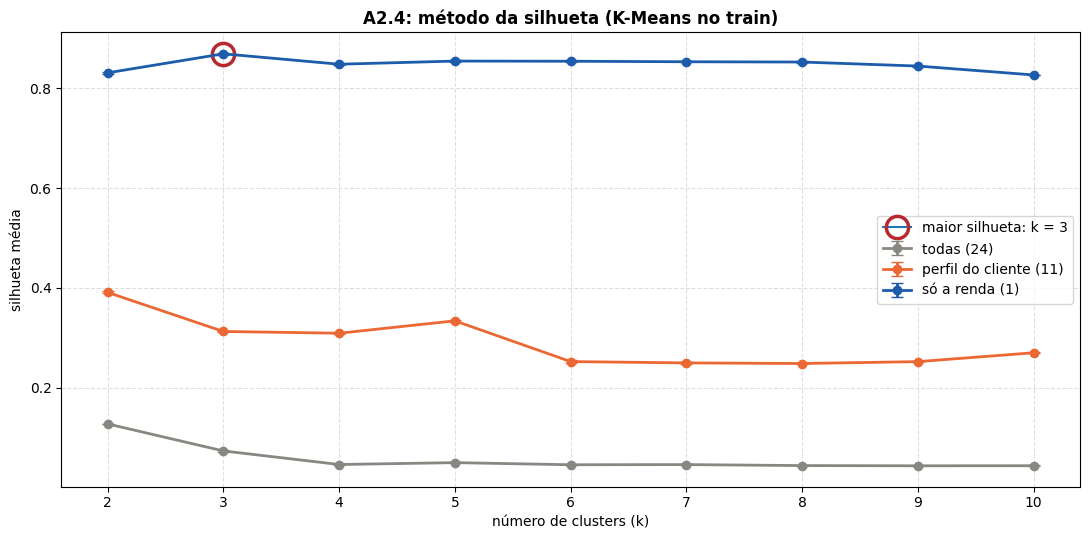

Maior silhueta: só a renda (1), com k = 3 (silhueta 0.8690)


In [38]:
resultado_A2_4 = AtividadeA2_4()

### O que o método da silhueta mostrou

*   **Com as 24 variáveis, não existem grupos de verdade.** A silhueta fica entre 0,04 e 0,13 para qualquer k. Ou seja, as notas estão praticamente tão perto do cluster vizinho quanto do próprio. O K-Means divide a nuvem porque recebeu a ordem de dividir, mas os pedaços não são grupos naturais.
*   **Com o perfil do cliente (11 variáveis), a separação melhora, mas continua fraca.** A melhor silhueta é 0,39, com k = 2, e cai para 0,25 a 0,33 nos outros valores de k. O cotovelo em k = 5 da A2.3 não se confirma como um agrupamento bem separado.
*   **Só com a renda, os grupos são muito bem separados em qualquer k**, com silhueta entre 0,83 e 0,87. **O máximo é em k = 3, com silhueta de 0,869**, acima de k = 2 (0,831). Isso resolve a dúvida que o cotovelo deixou: o terceiro cluster representa uma separação real.
*   A variação entre os 3 sorteios de 10.000 notas é pequena (desvio de no máximo 0,002), então a ordem entre os grupos de variáveis e os valores de k é confiável.
*   **Escolha: K-Means com 3 clusters, usando só a renda.** É o maior score entre todas as opções testadas. A escolha também tem sentido de negócio: a A1 mostrou que a renda é a única variável que determina o comportamento de compra, e as demais variáveis só acrescentam ruído aos grupos. Uma ressalva: com menos variáveis a silhueta tende a ser mais alta. Por isso, na A2.6, confiro se os 3 clusters fazem sentido olhando o gasto e o tipo de conta de cada um.

##Atividade A2.5 (5º Passo): Criar o Modelo: **Clusters**

In [39]:
# NDARRAY - TRANINING: train e validation
resultado_A2_5 = AtividadeA2_5_treino()

Modelo: K-Means com k = 3. variáveis: só a renda (1). treinado com train + validation (283.800 notas)


,centro da renda (R$),faixa de renda,notas no treinamento,%
cluster,,,,
Cluster 1,3270.61,"mínimo a R$ 5,764.26",164717,58.04
Cluster 2,8257.91,"R$ 5,764.26 a R$ 14,578.66",70380,24.80
Cluster 3,20899.40,"R$ 14,578.66 a máximo",48703,17.16


Com uma variável só, a fronteira entre dois clusters é o ponto médio entre os centros: R$ 5,764.26 | R$ 14,578.66
Silhueta no treinamento: 0.8725 (desvio entre sorteios: 0.0013)


### O modelo de clusterização criado

*   Treinei o K-Means final com **3 clusters, usando só a renda**, com train e validation juntos (283.800 notas) e 10 inícios diferentes. Os clusters foram numerados da menor para a maior renda:

    | Cluster | Centro da renda | Faixa de renda | Notas | % |
    |---|---|---|---|---|
    | Cluster 1 | R\$ 3.270,61 | até R\$ 5.764,26 | 164.717 | 58,04% |
    | Cluster 2 | R\$ 8.257,91 | de R\$ 5.764,26 a R\$ 14.578,66 | 70.380 | 24,80% |
    | Cluster 3 | R\$ 20.899,40 | acima de R\$ 14.578,66 | 48.703 | 17,16% |

*   Como o modelo usa uma variável só, cada fronteira é o ponto médio entre dois centros. Na prática, o K-Means encontrou sozinho **duas linhas de corte na renda: R\$ 5.764,26 e R\$ 14.578,66**.
*   Os centros ficam muito perto do miolo de renda de cada tipo de conta que vimos na Parte 1: cerca de R\$ 3.200 no ESSENTIAL, R\$ 7.800 no VIP e R\$ 22.000 no PRIME. As proporções dos clusters também ficam perto das dos tipos de conta (59,5%, 23,4% e 17,1%). Sem nunca ter visto o tipo de conta, o modelo reconstruiu uma divisão muito parecida com ele.
*   A silhueta no treinamento é **0,8725**: os clusters estão muito bem separados.

In [40]:
# NDARRAY - TESTE: test
resultado_A2_5_teste = AtividadeA2_5_teste()

,notas no test,%
cluster,,
Cluster 1,82634,58.23
Cluster 2,34881,24.58
Cluster 3,24385,17.18


Silhueta no test: 0.8717 (desvio entre sorteios: 0.0038) | no treinamento: 0.8725


### O modelo aplicado ao conjunto de teste

*   Sem nenhum ajuste novo, o modelo atribuiu um cluster a cada uma das 141.900 notas do test: 58,23% no Cluster 1, 24,58% no Cluster 2 e 17,18% no Cluster 3. Esses valores diferem no máximo 0,22 ponto percentual das proporções do treinamento.
*   A silhueta no test é **0,8717**, praticamente igual à do treinamento (0,8725). Os grupos se mantêm em dados que o modelo nunca viu: a divisão por renda é uma estrutura estável da base, e não um acaso do treino.

##Atividade A2.6 (6º Passo): Medir a acurácia (score) dos Modelos de Clusterização:

####Atividade A2.6.1: Medir a Proporção dos clusters: Conjunto TRAIN

1. Proporção dos clusters no TRAIN (141.900 notas)


,notas,%,renda mínima (R$),renda mediana (R$),renda máxima (R$),gasto médio (R$)
cluster,,,,,,
Cluster 1,82424,58.09,1765.04,3252.61,5763.51,361.15
Cluster 2,35169,24.78,5765.06,7802.32,14574.94,904.34
Cluster 3,24307,17.13,14578.74,20921.96,32236.52,2304.63


2a. Composição de cada cluster por tipo de conta (% da linha)


TIPO DA CONTA,ESSENTIAL,VIP,PRIME
cluster,,,
Cluster 1,97.42,1.32,1.26
Cluster 2,6.98,86.28,6.74
Cluster 3,7.08,7.58,85.34


2b. Em que cluster caiu cada tipo de conta (% da linha)


cluster,Cluster 1,Cluster 2,Cluster 3
TIPO DA CONTA,,,
ESSENTIAL,95.06,2.90,2.04
VIP,3.27,91.20,5.54
PRIME,4.29,9.82,85.89


3. Adjusted Rand Index (clusters × tipo de conta): 0.8171
   Notas em que o cluster bate com o tipo de conta: 92.59%


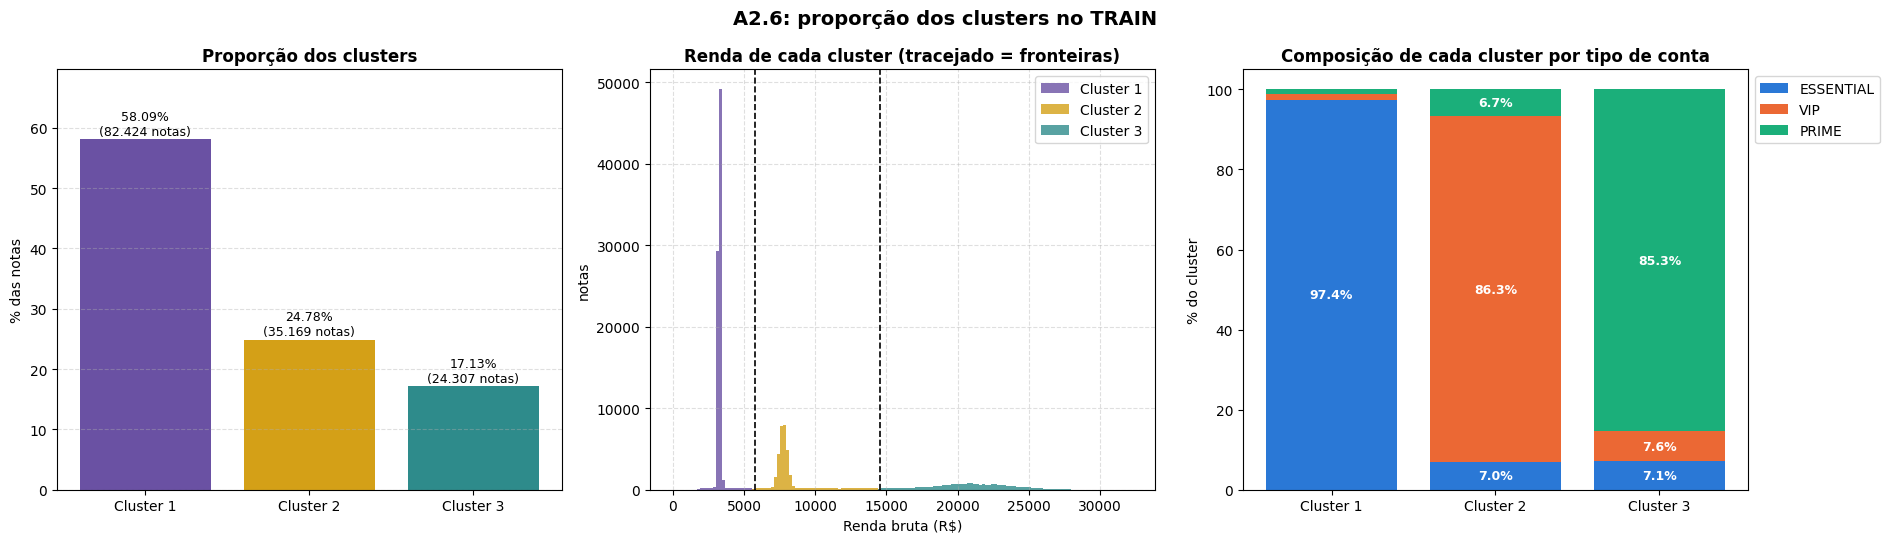

In [41]:
resultado_A2_6_1 = AtividadeA2_6("train")

### O que a proporção dos clusters mostrou no train

*   **Os três clusters são faixas de renda bem definidas e separam também o gasto**, mesmo sem o TOTAL ter entrado no modelo:

    | Cluster | Notas | % | Renda mediana | Faixa de renda | Gasto médio |
    |---|---|---|---|---|---|
    | Cluster 1 | 82.424 | 58,09% | R\$ 3.252,61 | R\$ 1.765 a R\$ 5.764 | **R\$ 361,15** |
    | Cluster 2 | 35.169 | 24,78% | R\$ 7.802,32 | R\$ 5.765 a R\$ 14.575 | **R\$ 904,34** |
    | Cluster 3 | 24.307 | 17,13% | R\$ 20.921,96 | R\$ 14.579 a R\$ 32.237 | **R\$ 2.304,63** |

*   **O gasto separa melhor por cluster do que por tipo de conta.** O Cluster 3 gasta 6,4 vezes o Cluster 1. Entre os tipos de conta, o PRIME gasta 5,2 vezes o ESSENTIAL (Parte 1). Agrupar os clientes pela renda produz segmentos de consumo mais nítidos que a classificação atual.
*   **Cada cluster corresponde, em sua maioria, a um tipo de conta:**
    *   o Cluster 1 é 97,42% ESSENTIAL;
    *   o Cluster 2 é 86,28% VIP;
    *   o Cluster 3 é 85,34% PRIME.
*   **Concordância entre clusters e tipos de conta:**
    *   em **92,59% das notas**, o cluster coincide com o tipo de conta;
    *   o Adjusted Rand Index é **0,8171**, numa escala em que 1 é coincidência total e 0 é acaso.
*   **Os 7,41% restantes são clientes cuja renda não combina com o tipo de conta.** É o grupo que a regressão já havia revelado, agora medido:
    *   95,06% dos ESSENTIAL estão no Cluster 1, mas 4,94% têm renda das faixas de VIP ou PRIME;
    *   91,20% dos VIP estão no Cluster 2;
    *   o **PRIME é o tipo de conta mais misturado**: só 85,89% têm renda de PRIME, e 4,29% têm renda da faixa do ESSENTIAL.

####Atividade A2.6.2: Medir a Proporção dos clusters: Conjunto VALIDATION

1. Proporção dos clusters no VALIDATION (141.900 notas)


,notas,%,renda mínima (R$),renda mediana (R$),renda máxima (R$),gasto médio (R$)
cluster,,,,,,
Cluster 1,82293,57.99,1758.25,3251.85,5764.17,362.33
Cluster 2,35211,24.81,5764.67,7804.58,14577.85,913.81
Cluster 3,24396,17.19,14580.03,20897.69,31015.16,2298.56


2a. Composição de cada cluster por tipo de conta (% da linha)


TIPO DA CONTA,ESSENTIAL,VIP,PRIME
cluster,,,
Cluster 1,97.45,1.31,1.24
Cluster 2,7.15,85.85,6.99
Cluster 3,7.49,7.71,84.80


2b. Em que cluster caiu cada tipo de conta (% da linha)


cluster,Cluster 1,Cluster 2,Cluster 3
TIPO DA CONTA,,,
ESSENTIAL,94.86,2.98,2.16
VIP,3.25,91.09,5.66
PRIME,4.23,10.18,85.58


3. Adjusted Rand Index (clusters × tipo de conta): 0.8128
   Notas em que o cluster bate com o tipo de conta: 92.40%


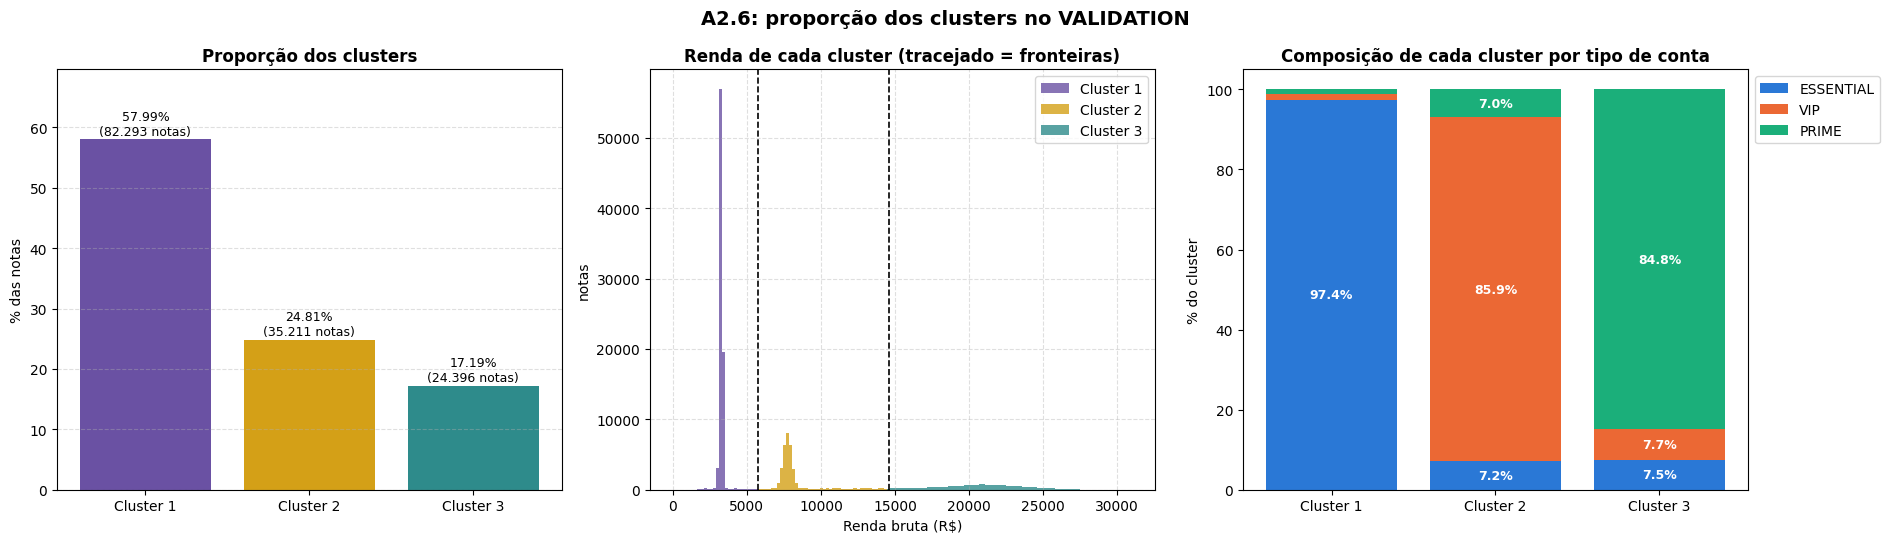

In [42]:
resultado_A2_6_2 = AtividadeA2_6("validation")

### O que a proporção dos clusters mostrou no validation

*   As proporções repetem as do train: **57,99%** no Cluster 1, **24,81%** no Cluster 2 e **17,19%** no Cluster 3. A diferença é de no máximo 0,10 ponto percentual.
*   O gasto médio continua crescendo com a renda, mesmo sem o TOTAL ter entrado no modelo:

    | Cluster | Gasto médio | Renda mediana |
    |---|---|---|
    | Cluster 1 | R\$ 362,33 | R\$ 3.251,85 |
    | Cluster 2 | R\$ 913,81 | R\$ 7.804,58 |
    | Cluster 3 | R\$ 2.298,56 | R\$ 20.897,69 |

    O Cluster 3 gasta 6,3 vezes o Cluster 1, de novo acima da diferença entre PRIME e ESSENTIAL.
*   Cada cluster continua dominado por um tipo de conta: 97,45% de ESSENTIAL no Cluster 1, 85,85% de VIP no Cluster 2 e 84,80% de PRIME no Cluster 3.
*   **A concordância entre clusters e tipos de conta é de 92,40%**, com Adjusted Rand Index de **0,8128**. Os números do train eram 92,59% e 0,8171. A parcela de clientes com renda incompatível com o tipo de conta se mantém em cerca de 7,6%, e o PRIME segue como o tipo mais misturado: só 85,58% têm renda de PRIME, e 4,23% têm renda da faixa do ESSENTIAL.

####Atividade A2.6.3: Medir a Proporção dos clusters: Conjunto TEST

1. Proporção dos clusters no TEST (141.900 notas)


,notas,%,renda mínima (R$),renda mediana (R$),renda máxima (R$),gasto médio (R$)
cluster,,,,,,
Cluster 1,82634,58.23,1766.01,3252.74,5762.60,362.53
Cluster 2,34881,24.58,5764.67,7801.17,14578.07,908.29
Cluster 3,24385,17.18,14579.32,20946.05,31034.63,2292.97


2a. Composição de cada cluster por tipo de conta (% da linha)


TIPO DA CONTA,ESSENTIAL,VIP,PRIME
cluster,,,
Cluster 1,97.40,1.30,1.30
Cluster 2,6.81,86.14,7.05
Cluster 3,7.40,7.21,85.39


2b. Em que cluster caiu cada tipo de conta (% da linha)


cluster,Cluster 1,Cluster 2,Cluster 3
TIPO DA CONTA,,,
ESSENTIAL,95.06,2.81,2.13
VIP,3.26,91.39,5.35
PRIME,4.43,10.09,85.48


3. Adjusted Rand Index (clusters × tipo de conta): 0.8167
   Notas em que o cluster bate com o tipo de conta: 92.57%


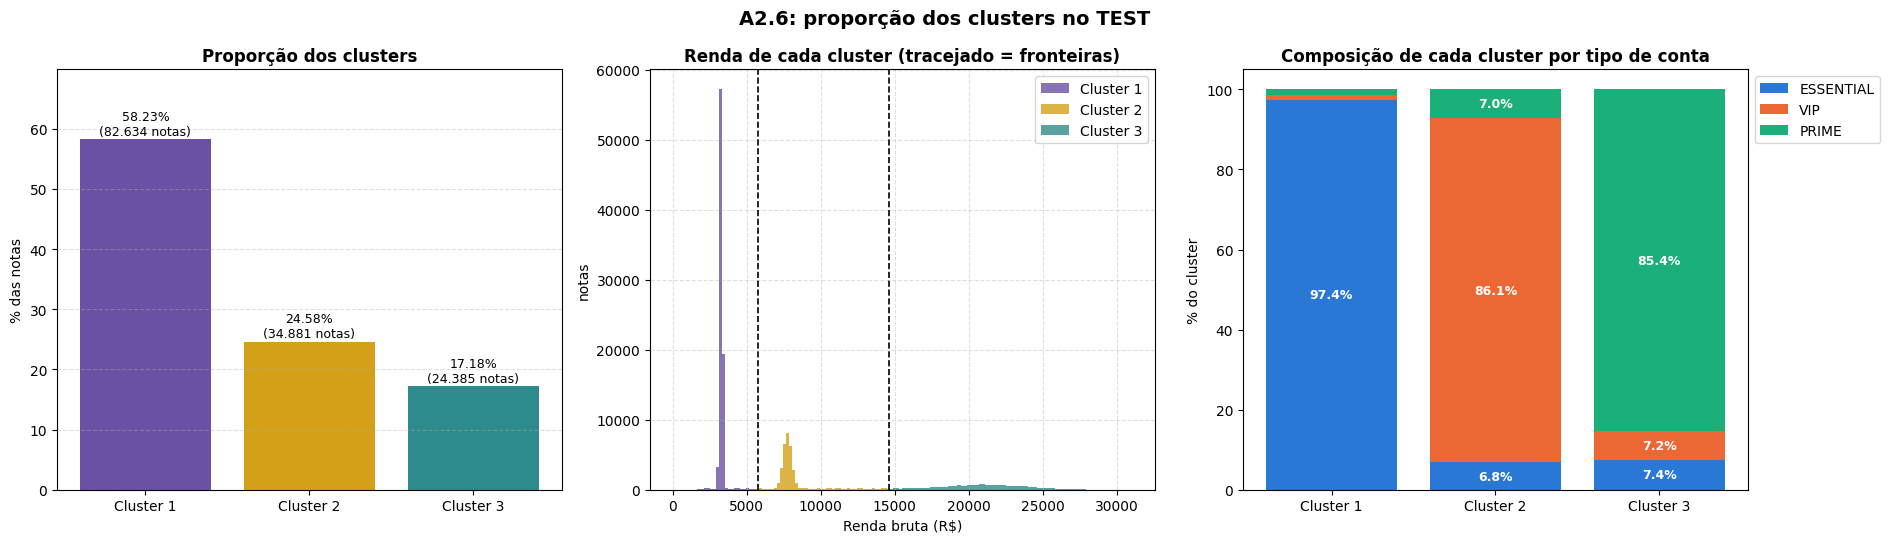

In [43]:
resultado_A2_6_3 = AtividadeA2_6("test")

### O que a proporção dos clusters mostrou no test

*   Em dados que o modelo nunca viu, as proporções se mantêm: **58,23%** no Cluster 1, **24,58%** no Cluster 2 e **17,18%** no Cluster 3.
*   O gasto médio repete o padrão: R\$ 362,53, R\$ 908,29 e R\$ 2.292,97. O Cluster 3 gasta 6,3 vezes o Cluster 1.
*   **A concordância entre clusters e tipos de conta é de 92,57%**, com Adjusted Rand Index de **0,8167**.
*   **Resumo dos três conjuntos:**

    | Conjunto | Cluster 1 | Cluster 2 | Cluster 3 | Concordância | ARI |
    |---|---|---|---|---|---|
    | Train | 58,09% | 24,78% | 17,13% | 92,59% | 0,8171 |
    | Validation | 57,99% | 24,81% | 17,19% | 92,40% | 0,8128 |
    | Test | 58,23% | 24,58% | 17,18% | 92,57% | 0,8167 |

    As proporções variam no máximo 0,24 ponto percentual, e a concordância, 0,19 ponto. **Os clusters são uma estrutura estável da base**: aparecem iguais em qualquer amostra do tamanho ideal.
*   **Em todos os conjuntos, cerca de 7,5% das notas pertencem a clientes cuja renda não combina com o tipo de conta.** O PRIME é sempre o tipo mais misturado: só cerca de 85,5% têm renda de PRIME, e cerca de 4,3% têm renda da faixa do ESSENTIAL.

##Atividade A2.7 (7º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

PARTE 1: proporção dos clusters na população inteira
1. Proporção dos clusters no POPULACAO (621.823 notas)


,notas,%,renda mínima (R$),renda mediana (R$),renda máxima (R$),gasto médio (R$)
cluster,,,,,,
Cluster 1,361086,58.07,1743.20,3252.73,5764.09,362.19
Cluster 2,154128,24.79,5764.69,7800.10,14578.48,909.53
Cluster 3,106609,17.14,14578.93,20928.15,31600.85,2299.52


2a. Composição de cada cluster por tipo de conta (% da linha)


TIPO DA CONTA,ESSENTIAL,VIP,PRIME
cluster,,,
Cluster 1,97.39,1.34,1.28
Cluster 2,6.85,86.16,6.99
Cluster 3,7.13,7.45,85.41


2b. Em que cluster caiu cada tipo de conta (% da linha)


cluster,Cluster 1,Cluster 2,Cluster 3
TIPO DA CONTA,,,
ESSENTIAL,95.09,2.85,2.06
VIP,3.31,91.23,5.46
PRIME,4.33,10.13,85.54


3. Adjusted Rand Index (clusters × tipo de conta): 0.8166
   Notas em que o cluster bate com o tipo de conta: 92.55%


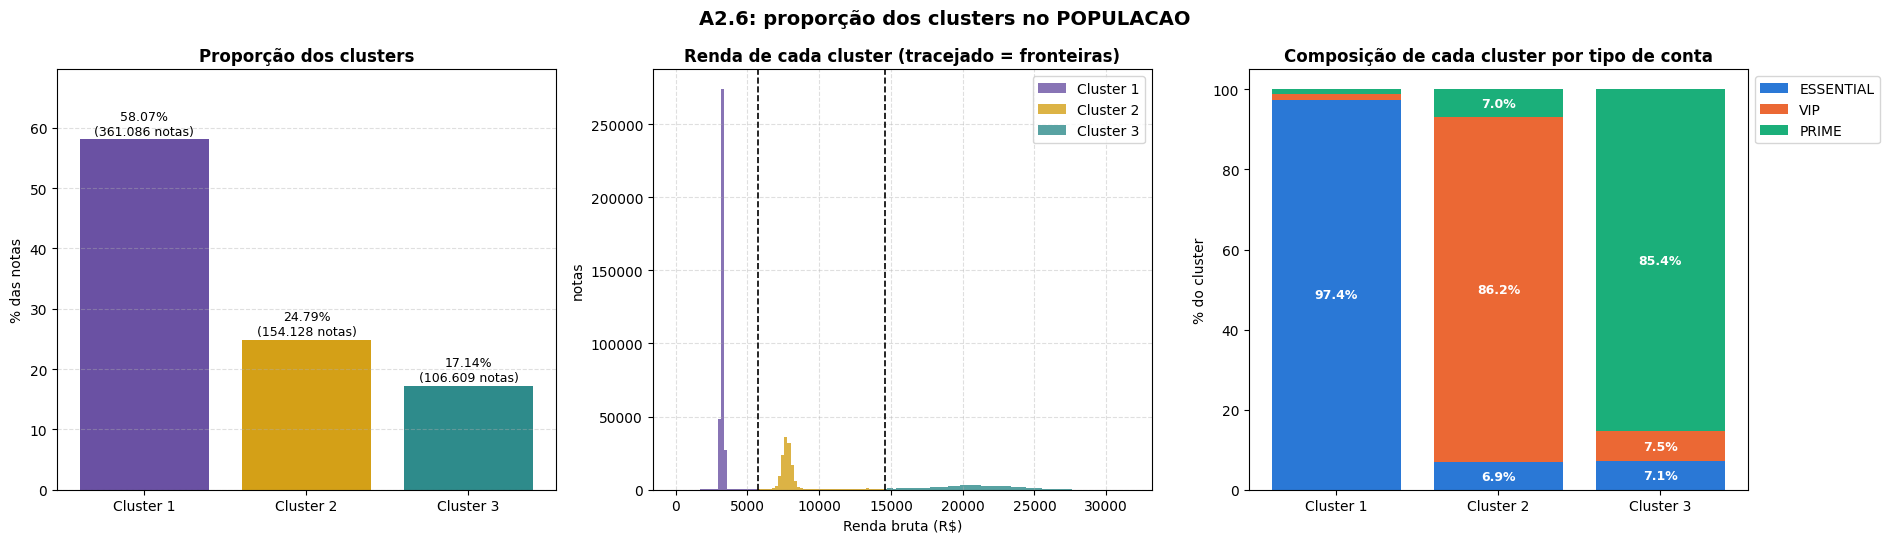

Silhueta na população: 0.8682 (desvio entre sorteios: 0.0039)

PARTE 2: gasto médio (R$) por tipo de conta e cluster


,Cluster 1,Cluster 2,Cluster 3
TIPO DA CONTA,,,
ESSENTIAL,360.54,1124.37,1968.38
VIP,419.51,874.22,1959.43
PRIME,427.93,1134.10,2356.84


Número de notas por tipo de conta e cluster


,Cluster 1,Cluster 2,Cluster 3
TIPO DA CONTA,,,
ESSENTIAL,351654,10558,7604
VIP,4821,132792,7946
PRIME,4611,10778,91059



PARTE 3: concordância e ARI em 200 amostras de 141.900 notas. comparados com os conjuntos


,concordância (%),ARI
conjunto,,
train,92.5920,0.8171
validation,92.3975,0.8128
test,92.5666,0.8167
amostras da população: média,92.5565,0.8167
"amostras da população: percentil 2,5%",92.4488,0.8140
"amostras da população: percentil 97,5%",92.6754,0.8197
população inteira,92.5513,0.8166


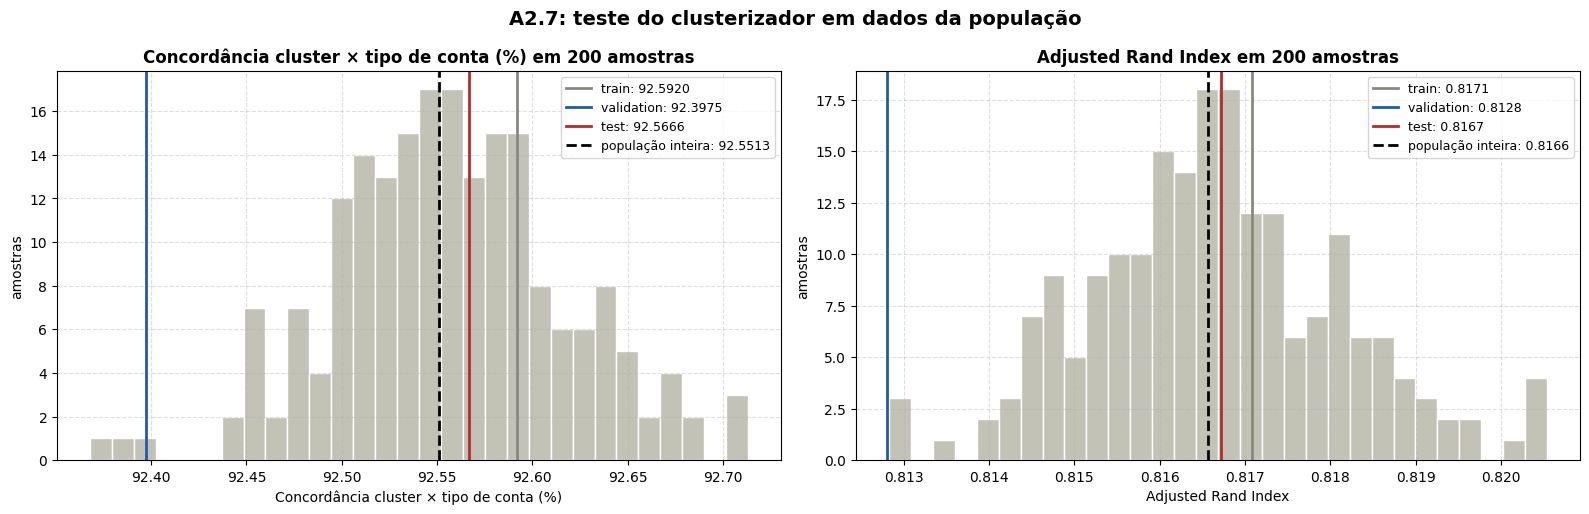

In [44]:
resultado_A2_7 = AtividadeA2_7()

### O que o teste na população mostrou

*   **Na população inteira (621.823 notas), o modelo repete os resultados de todos os conjuntos:**
    *   58,07% das notas no Cluster 1, 24,79% no Cluster 2 e 17,14% no Cluster 3;
    *   gasto médio de R\$ 362,19, R\$ 909,53 e R\$ 2.299,52;
    *   silhueta de **0,8682**;
    *   concordância de **92,55%** com o tipo de conta, com Adjusted Rand Index de **0,8166**.
*   **O gasto acompanha a renda, e não o tipo de conta.** Cruzando tipo de conta e cluster:

    | Gasto médio (R\$) | Cluster 1 (renda baixa) | Cluster 2 (renda média) | Cluster 3 (renda alta) |
    |---|---|---|---|
    | ESSENTIAL | 360,54 | 1.124,37 | 1.968,38 |
    | VIP | 419,51 | 874,22 | 1.959,43 |
    | PRIME | 427,93 | 1.134,10 | 2.356,84 |

    Os 4.611 registros PRIME com renda da faixa do ESSENTIAL gastam R\$ 427,93 por nota, perto dos R\$ 360,54 do ESSENTIAL típico. Já os 7.604 registros ESSENTIAL com renda alta gastam R\$ 1.968,38, quase seis vezes o ESSENTIAL típico. Dentro de cada coluna, os três tipos de conta gastam em faixas parecidas. Ao mudar de coluna, o gasto muda de patamar.
*   **Cerca de 7,45% das notas (46.318 na população) pertencem a clientes com renda incompatível com o tipo de conta.** Em cada cluster, os dois tipos de conta "de fora" aparecem em quantidades quase iguais:
    *   no Cluster 2, há 10.558 ESSENTIAL e 10.778 PRIME;
    *   no Cluster 3, há 7.604 ESSENTIAL e 7.946 VIP;
    *   no Cluster 1, há 4.821 VIP e 4.611 PRIME.

    Isso acontece mesmo com o ESSENTIAL sendo 3,5 vezes maior que o PRIME. Esses clientes parecem estar distribuídos em número igual entre os tipos de conta, e por isso o PRIME, o menor grupo, é o que aparece mais misturado em percentual.
*   **Em 200 amostras aleatórias do tamanho ideal, a concordância variou entre 92,45% e 92,68% (95% das amostras), e o ARI entre 0,8140 e 0,8197.** O train (92,59%) e o test (92,57%) caem no meio dessa faixa. O validation (92,40%) fica 0,05 ponto abaixo do limite inferior: uma diferença de cerca de 70 notas em 141.900, sem efeito prático.

## RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO

Fazer aqui o **RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ **Objetivo:** agrupar os clientes sem usar o gasto (TOTAL) nem o tipo de conta, para descobrir que segmentos existem naturalmente na base e se eles coincidem com a classificação atual. Usei os conjuntos de tamanho ideal: escolhi o modelo no train, treinei o modelo final com train e validation, apliquei no test e conferi na população (621.823 notas).

*   ✅ **Modelo escolhido: K-Means com 3 clusters, usando a renda.** Comparei três grupos de variáveis (as 24 variáveis, o perfil do cliente sem as medidas do vinho e só a renda) com 1 a 10 clusters, pelo método do cotovelo e pelo método da silhueta. Com as 24 variáveis, a silhueta não passa de 0,13: não existem grupos naturais. A renda sozinha, com 3 clusters, teve a **maior silhueta: 0,869**, o que indica grupos muito bem separados.

*   ✅ **Os três segmentos de clientes:**

    | Segmento | Renda | % das notas | Gasto médio por nota |
    |---|---|---|---|
    | Cluster 1: renda baixa | até R\$ 5.764 | 58% | R\$ 362 |
    | Cluster 2: renda média | de R\$ 5.764 a R\$ 14.579 | 25% | R\$ 910 |
    | Cluster 3: renda alta | acima de R\$ 14.579 | 17% | R\$ 2.300 |

*   ✅ **Estabilidade:** os segmentos se repetem em todos os conjuntos. A silhueta fica entre 0,868 e 0,873, as proporções variam no máximo 0,24 ponto percentual, e a concordância com os tipos de conta fica entre 92,40% e 92,59%. É uma estrutura real da base, e não um acaso do treino.

*   ✅ **O modelo redescobriu os tipos de conta sozinho.** Sem nunca ver o tipo de conta, em **92,55% das notas** o cluster coincide com ele (Adjusted Rand Index de 0,817). Os centros dos clusters (R\$ 3.271, R\$ 8.258 e R\$ 20.899) ficam no miolo de renda do ESSENTIAL, do VIP e do PRIME.

*   ✅ **Achado 1: a renda segmenta melhor que o tipo de conta.** O Cluster 3 gasta 6,3 vezes o Cluster 1, enquanto o PRIME gasta 5,2 vezes o ESSENTIAL. E o gasto segue a renda: um cliente PRIME com renda de ESSENTIAL gasta R\$ 428 por nota, quase o mesmo que um ESSENTIAL típico (R\$ 361). Já um ESSENTIAL com renda alta gasta R\$ 1.968.

*   ✅ **Achado 2: cerca de 7,5% das notas são de clientes com renda incompatível com o tipo de conta**, o que dá cerca de 46 mil notas na população. O PRIME é o tipo mais afetado em percentual: só 85,5% dos PRIME têm renda de PRIME.

*   ✅ **Achado 3:** região, sexo, estado civil, dependentes, opinião e as características do vinho **não formam segmentos**. O perfil demográfico e as preferências de vinho não distinguem grupos de clientes nesta base.

*   ✅ **Recomendações:**
    1.  Usar os três segmentos de renda para campanhas, metas de venda e projeção de faturamento, porque eles separam o consumo melhor que os tipos de conta atuais.
    2.  Revisar o enquadramento dos clientes com renda incompatível:
        *   ESSENTIAL com renda média ou alta (cerca de 18 mil notas na população) são candidatos a uma oferta de upgrade, porque já gastam como VIP ou PRIME;
        *   PRIME com renda baixa gastam como ESSENTIAL, e vale avaliar se os benefícios do PRIME se pagam para eles.
    3.  Os ~7,5% de clientes fora do lugar indicam o limite do classificador de tipo de conta (Atividade A3): pela renda, nenhum modelo deve passar de cerca de 92,5% de acerto.

#Atividade A3: Modelo de Classificação

##Atividade A3.1 (1º Passo): Normalizar - Mapear - Discretizar

In [45]:
resultado_A3_1 = AtividadeA3_1()

1. Discretização da OPINIÃO DO CLIENTE (train)


,satisfação,notas no train,%
nível,,,
1,Muito insatisfeito,1441,1.02
2,Insatisfeito,5716,4.03
3,Indiferente,21270,14.99
4,Satisfeito,109210,76.96
5,Muito satisfeito,4263,3.00



2. Tratamento de cada coluna


,tratamento,vira
coluna,,
DEPENDENTES,"normalizada (média 0, desvio 1)",DEPENDENTES
RENDA BRUTO (R$),"normalizada (média 0, desvio 1)",RENDA BRUTO (R$)
OPINIÃO DO CLIENTE,mapeada para 1 a 5 e normalizada,NÍVEL DA OPINIÃO
NOTA DE SATISFAÇÃO (%),"normalizada (média 0, desvio 1)",NOTA DE SATISFAÇÃO (%)
MEAN: alcohol,"normalizada (média 0, desvio 1)",MEAN: alcohol
MEAN: malic_acid,"normalizada (média 0, desvio 1)",MEAN: malic_acid
MEAN: ash,"normalizada (média 0, desvio 1)",MEAN: ash
MEAN: alcalinity_of_ash,"normalizada (média 0, desvio 1)",MEAN: alcalinity_of_ash
MEAN: magnesium,"normalizada (média 0, desvio 1)",MEAN: magnesium



3. Conferência da normalização e tamanho dos conjuntos


,linhas,variáveis de entrada,maior |média| das normalizadas,menor desvio das normalizadas,maior desvio das normalizadas
train,141900.0,24.0,0.0000,1.0000,1.0000
validation,141900.0,24.0,0.0086,0.9956,1.0083
test,141900.0,24.0,0.0127,0.9941,1.0123
populacao,621823.0,24.0,0.0087,0.9953,1.0051



4. Distribuição da saída (tipo de conta) em cada conjunto (%)


,ESSENTIAL,VIP,PRIME
train,59.53,23.45,17.02
validation,59.58,23.39,17.04
test,59.67,23.17,17.17
populacao,59.47,23.41,17.12



Variáveis de entrada (X): 24 | saída (y): TIPO DA CONTA


### O que fiz na A3.1

Preparei os quatro conjuntos (train, validation, test e população) para o modelo de classificação. A saída (y) é o **TIPO DA CONTA**: ESSENTIAL, VIP ou PRIME. A preparação é a mesma da regressão e da clusterização, para os três modelos partirem da mesma base.

* **Discretização da opinião:** a OPINIÃO DO CLIENTE virou a escala de 1 a 5. No train, 76,96% das notas estão em "Satisfeito" e só 3,00% em "Muito satisfeito", o mesmo retrato da Parte 1.
* **Variáveis removidas:**
  * a **NOTA FISCAL**, que é só um identificador;
  * o **TOTAL (R\$)**. Na regressão (A1.4.2) mostrei que o gasto é a renda multiplicada por uma fração sorteada, igual nos três tipos de conta. Depois que o modelo conhece a renda, o gasto não diz nada novo sobre o tipo de conta. Além disso, um cliente novo ainda não tem gasto no momento do cadastro, e é aí que o classificador seria usado.
* **24 variáveis de entrada:** as numéricas normalizadas (média 0, desvio 1) e as categorias em colunas 0/1. Médias e desvios foram aprendidos **só no train**. A maior média absoluta fora do train é 0,0127 (test), e os desvios ficam entre 0,994 e 1,012. Não houve vazamento, e os conjuntos são equivalentes.
* **Distribuição das classes:** as proporções são praticamente iguais nos quatro conjuntos. No train são 59,53% ESSENTIAL, 23,45% VIP e 17,02% PRIME. A maior diferença é de 0,28 p.p. (VIP, train × test).

Isso define a régua da A3.3. Um classificador que sempre responde "ESSENTIAL" já acerta cerca de 59,6% do validation, então qualquer modelo precisa ficar bem acima disso. Como as classes são desbalanceadas, além da acurácia também uso a **acurácia balanceada** e o **F1 macro**, que dão o mesmo peso ao VIP e ao PRIME.

##Atividade A3.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [46]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
resultado_A3_2 = AtividadeA3_2()

,"X (linhas, colunas)","y (linhas,)",tipo de X,tipo de y
conjunto,,,,
train,"(141900, 24)","(141900,)",ndarray,ndarray
validation,"(141900, 24)","(141900,)",ndarray,ndarray
test,"(141900, 24)","(141900,)",ndarray,ndarray
populacao,"(621823, 24)","(621823,)",ndarray,ndarray


### O que fiz na A3.2

Separei a entrada (X) da saída (y) em cada conjunto. X tem as 24 variáveis de entrada, e y tem o tipo de conta. Train, validation e test ficaram com 141.900 notas cada, e a população com 621.823, todos em **ndarray** (numpy), o formato que os classificadores do scikit-learn recebem.

##Atividade A3.3 (3º Passo): Escolher / Criar o Modelo: **Classifiers**

Escolher enter os seguintes - **Classifiers**:

1.   Nearest Neighbors
2.   Linear SVM
2.   RBF SVM
2.   Gaussian Process
2.   Decision Tree
2.   Random Forest
2.   Neural Net
2.   AdaBoost
2.   Naive Bayes
2.   QDA

**Qual obteve o maior SCORE ?**

Referência: classe mais comum: pronto em 0.1 s (treinou com 141.900 notas)
Nearest Neighbors: pronto em 257.4 s (treinou com 141.900 notas)
Linear SVM: pronto em 6.2 s (treinou com 141.900 notas)
RBF SVM: pronto em 99.4 s (treinou com 10.000 notas)
Gaussian Process: pronto em 87.6 s (treinou com 1.000 notas)
Decision Tree: pronto em 5.1 s (treinou com 141.900 notas)
Random Forest: pronto em 28.5 s (treinou com 141.900 notas)
Neural Net: pronto em 103.2 s (treinou com 141.900 notas)
AdaBoost: pronto em 88.9 s (treinou com 141.900 notas)
Naive Bayes: pronto em 0.3 s (treinou com 141.900 notas)


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


QDA: pronto em 0.6 s (treinou com 141.900 notas)

Comparação dos classificadores (ordenados pela acurácia no validation)


,notas no treino,acurácia train (%),acurácia validation (%),train − validation (p.p.),acurácia balanceada validation (%),F1 macro validation (%),tempo de treino (s),tempo de previsão (s)
classificador,,,,,,,,
AdaBoost,141900,92.67,92.46,0.21,90.95,89.96,83.49,5.37
Neural Net,141900,93.10,92.44,0.66,90.81,89.93,102.94,0.26
Random Forest,141900,92.82,92.39,0.43,90.84,89.81,25.71,2.82
Decision Tree,141900,93.23,92.36,0.87,90.45,89.90,5.10,0.05
RBF SVM,10000,92.51,92.21,0.30,90.29,89.70,3.30,96.15
Nearest Neighbors,141900,77.83,75.46,2.37,65.34,65.29,0.20,257.16
Linear SVM,141900,72.98,72.91,0.07,62.36,57.92,6.11,0.08
Naive Bayes,141900,72.80,72.77,0.03,60.56,57.06,0.24,0.08
QDA,141900,68.04,68.07,-0.03,49.95,48.46,0.37,0.21


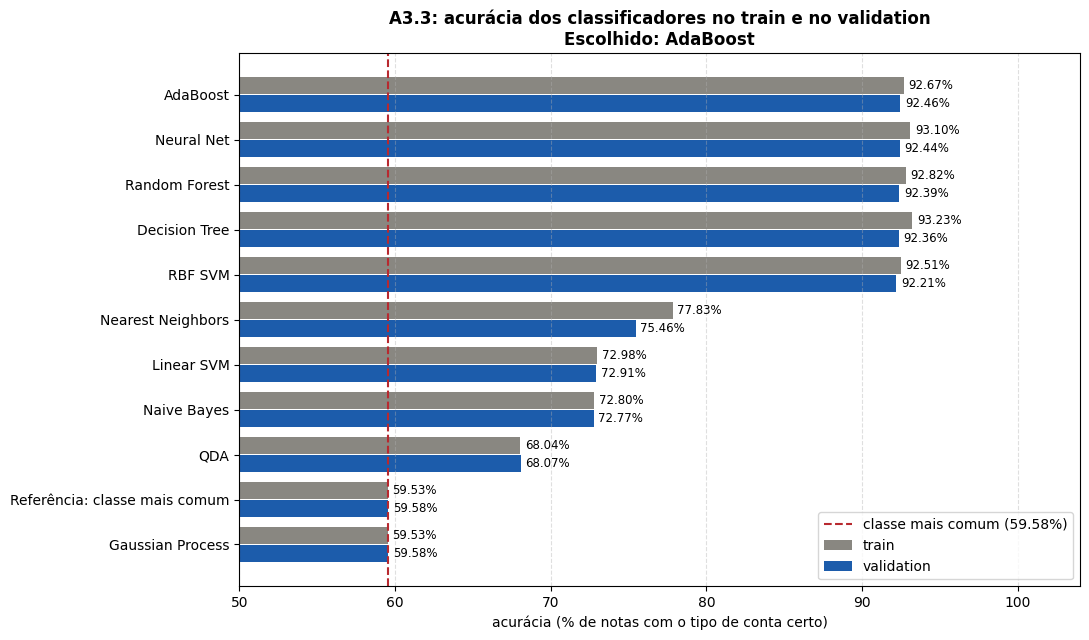

Classificador escolhido (maior acurácia no validation): AdaBoost (92.46%)


In [47]:
resultado_A3_3 = AtividadeA3_3()

### Qual obteve o maior SCORE?

**AdaBoost**, com **92,46%** de acurácia no validation: acertou o tipo de conta de 92,46% das 141.900 notas. A referência que sempre responde "ESSENTIAL" acerta 59,58%, então o modelo fica 32,9 p.p. acima do piso.

* **Os cinco primeiros empataram na prática.** AdaBoost, Neural Net, Random Forest, Decision Tree e RBF SVM ficaram entre 92,21% e 92,46%. A diferença entre o 1º e o 2º (Neural Net, 92,44%) é de 0,02 p.p., cerca de 30 notas em 141.900, bem abaixo do erro de amostragem. Segui a regra do roteiro (maior score) e fiquei com o AdaBoost. Ele também tem a menor diferença entre train e validation dos cinco (0,21 p.p.), ou seja, é o que menos decorou o train.
* **O teto fica perto de 92,5%, e eu já esperava isso.** Na clusterização (A2.6), só os três grupos de renda já concordavam com o tipo de conta em 92,6% das notas. Os melhores classificadores chegam ao mesmo número porque, na prática, aprenderam a mesma regra: dois cortes de renda. Os cerca de 7,5% de clientes com renda incompatível com o próprio tipo de conta são impossíveis de acertar com as variáveis da base.
* **Sem overfitting nos melhores:** a diferença entre train e validation ficou abaixo de 1 p.p. em todos os cinco. A acurácia balanceada (90,95%) e o F1 macro (89,96%) ficam um pouco abaixo da acurácia. Isso mostra que o modelo erra um pouco mais no VIP e no PRIME, que são as classes menores.
* **Por que alguns ficaram para trás:**
  * O **Nearest Neighbors** (75,46%) mede a distância usando as 24 variáveis com o mesmo peso. A renda é só uma delas, então os "vizinhos" acabam escolhidos pelos vinhos e pelos dados demográficos, que não dizem nada sobre o tipo de conta. Também foi o único com diferença relevante entre train e validation (2,37 p.p.).
  * O **Linear SVM** (72,91%), o **Naive Bayes** (72,77%) e o **QDA** (68,07%) têm formatos rígidos. O VIP ocupa a faixa do meio da renda, e uma reta não consegue isolar uma faixa do meio. O Naive Bayes e o QDA supõem uma distribuição normal dentro de cada classe. No QDA, o aviso do scikit-learn também mostra que a matriz de covariância do ESSENTIAL não tem posto cheio, o que deixa o modelo instável.
  * O **Gaussian Process** só conseguiu treinar com 1.000 notas, e com um único comprimento de escala para as 24 variáveis. Nessa configuração ele não separou as classes e passou a responder sempre "ESSENTIAL", empatando com a referência. Esse é o preço do custo computacional dele, que cresce com o cubo do número de notas.

Importância das variáveis no AdaBoostClassifier (as 10 maiores)


,importância (%)
RENDA BRUTO (R$),85.83
NOTA DE SATISFAÇÃO (%),14.17
DEPENDENTES,0.00
NÍVEL DA OPINIÃO,0.00
MEAN: alcohol,0.00
MEAN: malic_acid,0.00
MEAN: ash,0.00
MEAN: alcalinity_of_ash,0.00
MEAN: magnesium,0.00
MEAN: total_phenols,0.00


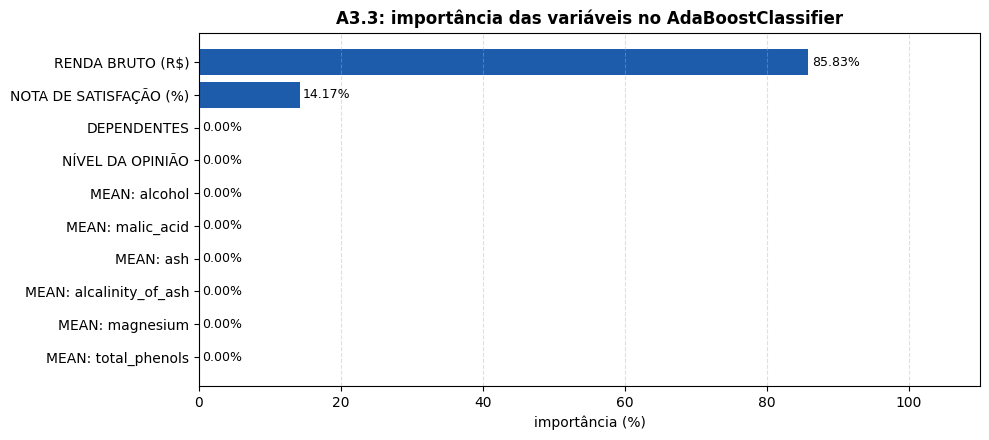

In [48]:
importancia_A3_3 = importancia_variaveis()

### Importância das variáveis no AdaBoost

O AdaBoost usou só **2 das 24 variáveis**. A **RENDA BRUTO (R\$)** responde por **85,83%** da importância e a **NOTA DE SATISFAÇÃO (%)** por **14,17%**. As outras 22 variáveis (dependentes, opinião, região, sexo, estado civil e todas as medidas dos vinhos) ficaram com 0%.

* O resultado confirma o que a regressão e a clusterização já mostravam: **a renda é o que define o tipo de conta**. O AdaBoost combina 100 árvores de um único corte cada ("tocos"), e quase todos os cortes importantes são feitos na renda.
* Os cortes que ele faz na nota de satisfação são uma surpresa, porque essa variável não apareceu como relevante em nenhuma etapa anterior. Por isso, fiz o diagnóstico abaixo para medir se ela realmente ajuda a acertar o tipo de conta ou se é só um ajuste fino nos casos difíceis.

In [49]:
diagnostico_A3_3 = diagnostico_satisfacao_tipo()

1. Árvores de um corte do AdaBoost, por variável


,árvores,soma dos pesos,menor corte,maior corte,peso (%)
variável,,,,,
RENDA BRUTO (R$),75,19.14,2935.59,21216.81,85.83
NOTA DE SATISFAÇÃO (%),25,3.16,68.73,69.54,14.17



Onde ficam os cortes na renda


,árvores
"corte na renda (R$, arredondado)",
2940.0,1
2960.0,3
2980.0,4
2990.0,2
3010.0,1
3030.0,2
3040.0,5
3070.0,1
3080.0,1



2. NOTA DE SATISFAÇÃO (%) por tipo de conta (train)


,média,mediana,desvio,notas
TIPO DA CONTA,,,,
ESSENTIAL,68.68,68.68,0.00,84477
VIP,68.68,68.68,0.04,33273
PRIME,70.63,68.68,3.11,24150


Kruskal-Wallis: H = 55789.86 | p-valor = 0.00% → distribuições diferentes a 5%

3. AdaBoost com menos variáveis (medido no validation)


,quantidade,acurácia validation (%),acurácia balanceada validation (%),ganho sobre só a renda (p.p.)
variáveis de entrada,,,,
só a renda,1,92.36,90.75,0.0
renda + nota de satisfação,2,92.46,90.95,0.1
todas (modelo da A3.3),24,92.46,90.95,0.1


### O que o diagnóstico mostrou

* **A nota de satisfação é praticamente uma constante.** Ela vale 68,68% em todas as notas do ESSENTIAL (desvio 0,00) e em quase todas do VIP (desvio 0,04). Só no PRIME ela varia (média 70,63%, desvio 3,11). Mesmo assim, a mediana do PRIME continua em 68,68%, então mais da metade dos PRIME também tem o valor fixo.
* **Por isso os 25 tocos da nota cortam entre 68,73% e 69,54%.** A regra que o AdaBoost aprendeu é simples: "nota de satisfação diferente de 68,68% → PRIME". O teste de Kruskal-Wallis confirma que a distribuição muda entre os tipos de conta (p-valor < 0,01%), então o sinal é real.
* **Mas o ganho prático é pequeno:**
  * só com a renda, o AdaBoost acerta 92,36% do validation;
  * com a renda e a nota, acerta 92,46% (+0,10 p.p., cerca de 140 notas em 141.900);
  * as outras 22 variáveis não acrescentam nada: o modelo com as 24 chega aos mesmos 92,46%.
  
  O ganho só pode vir de notas que a renda sozinha errava, ou seja, de clientes PRIME com renda abaixo do esperado para o tipo de conta.
* **Lição:** com 141.900 notas, qualquer diferença vira "estatisticamente significativa". O que importa é o tamanho do efeito, e aqui ele é de 0,1 p.p.
* **Cortes na renda:** os 75 tocos da renda se concentram em quatro regiões:
  * entre R\$ 2.900 e R\$ 3.600;
  * entre R\$ 6.800 e R\$ 8.900;
  * perto de R\$ 15.100;
  * perto de R\$ 21.200, com 30 árvores.
  
  Cada toco é só um voto ponderado, e a decisão final sai da soma dos votos. Por isso, esses cortes individuais não são as fronteiras finais entre os tipos de conta.

### A3.3.1: Intervalo de confiança: Train

1. Validação cruzada no train (10 folds estratificados)


,acurácia (%),acurácia balanceada (%),F1 macro (%)
fold,,,
1,92.29,90.60,89.69
2,92.64,91.07,90.17
3,92.54,90.98,90.05
4,92.77,91.43,90.43
5,93.00,91.52,90.72
6,92.73,91.04,90.18
7,92.80,91.21,90.34
8,92.84,91.34,90.47
9,92.76,91.34,90.42


,acurácia (%),acurácia balanceada (%),F1 macro (%)
média,92.66,91.14,90.23
desvio,0.23,0.29,0.32
mínimo,92.28,90.60,89.69
máximo,93.00,91.52,90.72



2. Intervalo de confiança de 95% (bootstrap das previsões fora do fold)


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
acurácia (%),92.66,0.07,92.53,92.80
acurácia balanceada (%),91.14,0.09,90.96,91.32
F1 macro (%),90.23,0.09,90.05,90.41


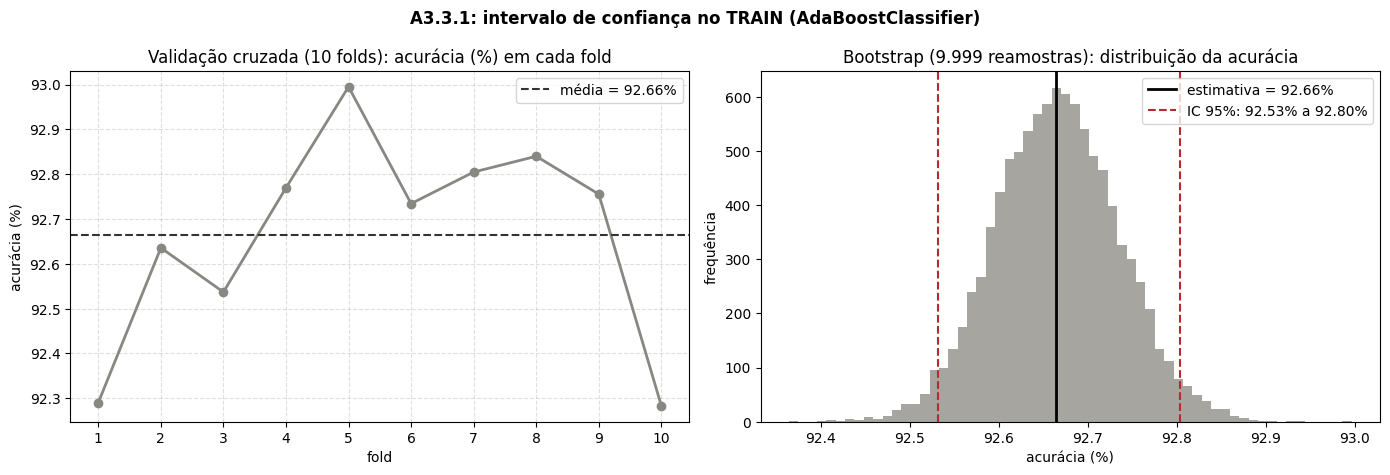

In [50]:
resultado_A3_3_1 = AtividadeA3_3_1()

### O que a A3.3.1 mostrou

* **Validação cruzada no train (10 folds estratificados):**
  * acurácia média de **92,66%** (desvio de 0,23 p.p., de 92,28% a 93,00%);
  * acurácia balanceada de 91,14%;
  * F1 macro de 90,23%.
* **A variação entre os folds é a que o sorteio explica sozinho.** Cada fold tem 14.190 notas, e o erro de amostragem de uma acurácia de 92,7% com esse tamanho é de cerca de 0,22 p.p., praticamente o desvio observado (0,23). Nenhum fold destoa.
* **Bootstrap das previsões feitas fora do fold** (9.999 reamostras), com IC 95%:
  * acurácia: **92,53% a 92,80%** (erro padrão 0,07 p.p.);
  * acurácia balanceada: 90,96% a 91,32%;
  * F1 macro: 90,05% a 90,41%.
* **O AdaBoost não decora o train.** A acurácia medida em notas que o modelo não viu (92,66%) é praticamente igual à do modelo final medido no próprio train (92,67%, A3.3).

### A3.3.2: Intervalo de confiança: Validation

1. Intervalo de confiança de 95% no validation (modelo treinado no train)


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
acurácia (%),92.46,0.07,92.33,92.60
acurácia balanceada (%),90.95,0.09,90.77,91.13
F1 macro (%),89.96,0.09,89.78,90.15



2. Validação cruzada dentro do validation (10 folds estratificados)


,acurácia (%),acurácia balanceada (%),F1 macro (%)
fold,,,
1,92.47,90.82,89.95
2,92.58,90.91,90.13
3,92.20,90.41,89.64
4,92.48,91.05,90.01
5,92.34,90.79,89.82
6,92.66,91.10,90.28
7,91.97,90.28,89.31
8,92.68,90.88,90.17
9,92.34,90.70,89.84


,acurácia (%),acurácia balanceada (%),F1 macro (%)
média,92.43,90.81,89.93
desvio,0.22,0.28,0.29
mínimo,91.97,90.28,89.31
máximo,92.68,91.12,90.28



3. Comparação dos intervalos: train (A3.3.1) × validation


,train: estimativa,train: IC inferior,train: IC superior,validation: estimativa,validation: IC inferior,validation: IC superior,intervalos se sobrepõem
acurácia (%),92.66,92.53,92.80,92.46,92.33,92.60,True
acurácia balanceada (%),91.14,90.96,91.32,90.95,90.77,91.13,True
F1 macro (%),90.23,90.05,90.41,89.96,89.78,90.15,True


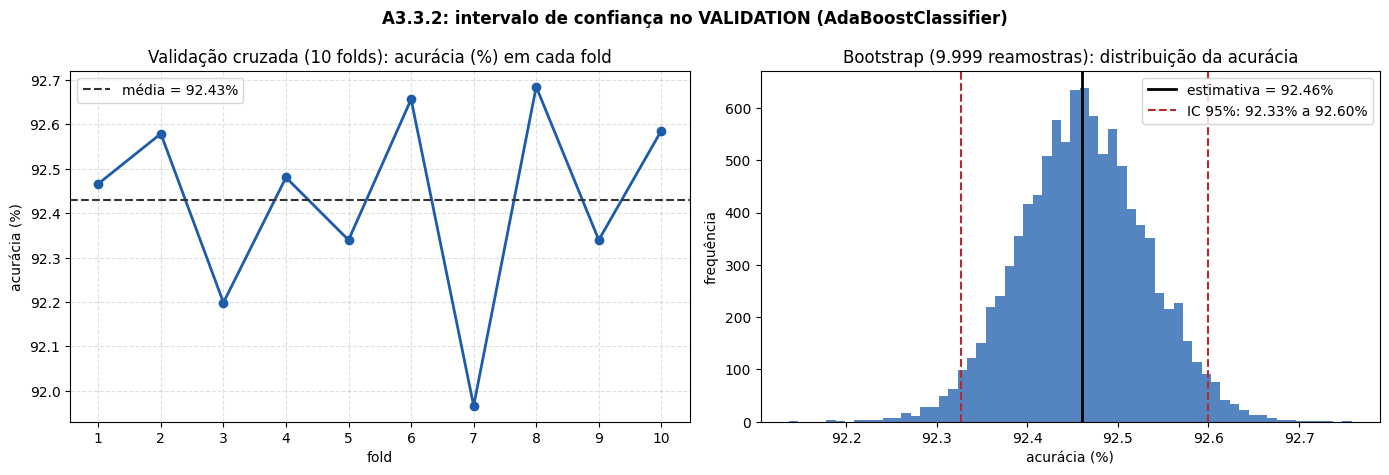

In [51]:
resultado_A3_3_2 = AtividadeA3_3_2()

### O que a A3.3.2 mostrou

* **O modelo treinado no train, aplicado ao validation**, tem os seguintes IC 95%:
  * acurácia: **92,46%** (de 92,33% a 92,60%);
  * acurácia balanceada: 90,95% (de 90,77% a 91,13%);
  * F1 macro: 89,96% (de 89,78% a 90,15%).
* **Validação cruzada dentro do validation:** um AdaBoost treinado do zero nessa amostra independente chega a 92,43% (desvio de 0,22 p.p.). É praticamente o mesmo número do modelo que veio do train, ou seja, o modelo do train generaliza por completo.
* **Os intervalos do train e do validation se sobrepõem nas três métricas.**
* **Por que o validation fica 0,2 p.p. abaixo do train?** A diferença não é overfitting, por dois motivos:
  1. Treinar no próprio validation também dá 92,43%.
  2. Na clusterização (A2.6), os grupos de renda concordaram com o tipo de conta em 92,59% do train e em 92,40% do validation, a mesma diferença de 0,19 p.p.
  
  O validation simplesmente sorteou um pouco mais de clientes "fora do lugar", que nenhum modelo consegue acertar.

##Atividade A3.4 (4º Passo): Medir a acurácia (score) dos Modelos de Classificação:

####Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TRAIN

1. Matriz de confusão: TRAIN (linhas = tipo real, colunas = tipo previsto)


previsto,ESSENTIAL,VIP,PRIME
real,,,
ESSENTIAL,79748,3144,1585
VIP,510,31057,1706
PRIME,481,2971,20698



2. Desempenho por classe


,notas reais,notas previstas,precisão (%),recall (%),F1 (%)
ESSENTIAL,84477,80739,98.77,94.40,96.54
VIP,33273,37172,83.55,93.34,88.17
PRIME,24150,23989,86.28,85.71,85.99



3. Métricas gerais com intervalo de confiança de 95%


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
acurácia (%),92.67,0.07,92.54,92.81
acurácia balanceada (%),91.15,0.09,90.97,91.33
F1 macro (%),90.23,0.09,90.06,90.42



4. Renda das notas acertadas e erradas, por tipo de conta real


,renda mediana dos acertos (R$),renda mediana dos erros (R$),erros
tipo real,,,
ESSENTIAL,3251.26,12218.02,4729
VIP,7762.47,17186.26,2216
PRIME,21457.54,8277.39,3452


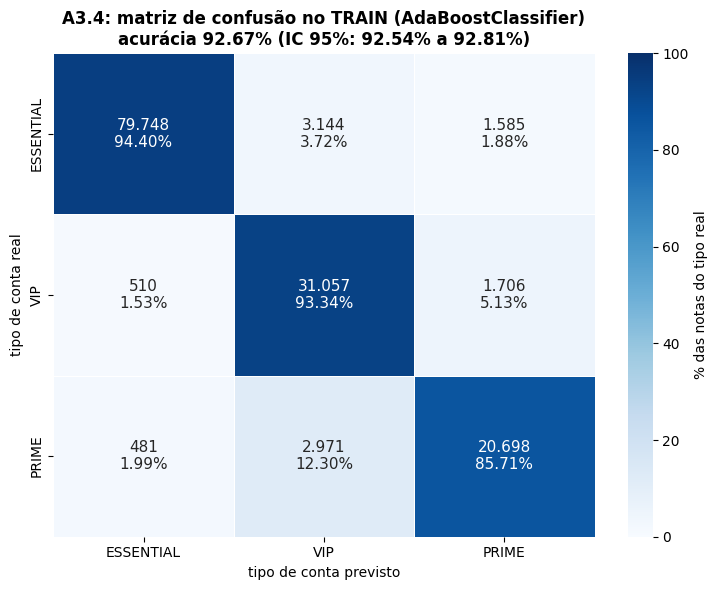

In [52]:
resultado_A3_4_1 = AtividadeA3_4("train")

### O que a matriz de confusão do TRAIN mostra

* **Acurácia de 92,67%** (IC 95%: 92,54% a 92,81%): 131.503 das 141.900 notas com o tipo de conta certo.
* **Acerto dentro de cada tipo (recall):** ESSENTIAL 94,40%, VIP 93,34% e **PRIME 85,71%**. O erro mais comum é o **PRIME previsto como VIP**: 2.971 notas, ou 12,30% dos PRIME.
* **Confiança de cada previsão (precisão):**
  * quando o modelo diz ESSENTIAL, acerta **98,77%** das vezes;
  * quando diz PRIME, acerta 86,28%;
  * quando diz VIP, acerta 83,55%. O VIP recebe tanto os ESSENTIAL quanto os PRIME com renda de faixa intermediária.
* **Os erros seguem a renda.** A renda mediana dos ESSENTIAL errados é R\$ 12.218, contra R\$ 3.251 nos acertados. Nos PRIME errados é R\$ 8.277, contra R\$ 21.458 nos acertados. Nos VIP errados é R\$ 17.186, contra R\$ 7.762. O modelo "erra" porque esses clientes têm a renda de outro tipo de conta.
* Há 1.585 ESSENTIAL (1,88%) previstos como **PRIME**. Não é um erro "de vizinho": são clientes ESSENTIAL com renda de PRIME.

####Atividade A3.4.2: Medir a acurácia (score) - Matriz de Confusão: Conjunto VALIDATION

1. Matriz de confusão: VALIDATION (linhas = tipo real, colunas = tipo previsto)


previsto,ESSENTIAL,VIP,PRIME
real,,,
ESSENTIAL,79600,3272,1667
VIP,488,30956,1743
PRIME,461,3067,20646



2. Desempenho por classe


,notas reais,notas previstas,precisão (%),recall (%),F1 (%)
ESSENTIAL,84539,80549,98.82,94.16,96.43
VIP,33187,37295,83.00,93.28,87.84
PRIME,24174,24056,85.82,85.41,85.61



3. Métricas gerais com intervalo de confiança de 95%


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
acurácia (%),92.46,0.07,92.33,92.60
acurácia balanceada (%),90.95,0.09,90.77,91.13
F1 macro (%),89.96,0.09,89.78,90.15



4. Renda das notas acertadas e erradas, por tipo de conta real


,renda mediana dos acertos (R$),renda mediana dos erros (R$),erros
tipo real,,,
ESSENTIAL,3250.26,12287.60,4939
VIP,7763.52,17190.56,2231
PRIME,21476.36,8442.36,3528


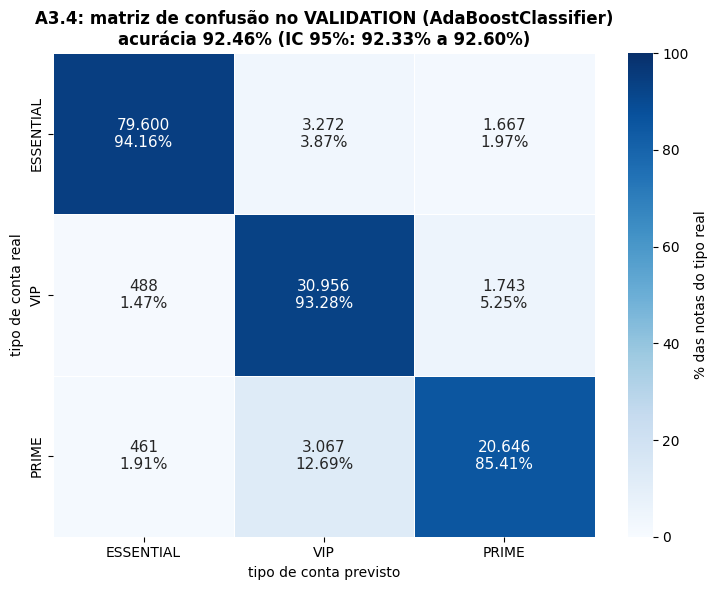

In [53]:
resultado_A3_4_2 = AtividadeA3_4("validation")

### O que a matriz de confusão do VALIDATION mostra

* **Acurácia de 92,46%** (IC 95%: 92,33% a 92,60%): 131.202 das 141.900 notas certas.
* **O padrão é o mesmo do train**, com variações de no máximo 0,3 p.p. por classe:
  * recall de 94,16% (ESSENTIAL), 93,28% (VIP) e 85,41% (PRIME);
  * precisão de 98,82%, 83,00% e 85,82%.
* O erro mais comum continua sendo o PRIME previsto como VIP: 3.067 notas (12,69%).
* A renda mediana dos erros é praticamente igual à do train: R\$ 12.288 nos ESSENTIAL, R\$ 17.191 nos VIP e R\$ 8.442 nos PRIME. São os mesmos clientes "fora do lugar".

####Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TEST

1. Matriz de confusão: TEST (linhas = tipo real, colunas = tipo previsto)


previsto,ESSENTIAL,VIP,PRIME
real,,,
ESSENTIAL,79885,3134,1646
VIP,481,30773,1621
PRIME,467,3126,20767



2. Desempenho por classe


,notas reais,notas previstas,precisão (%),recall (%),F1 (%)
ESSENTIAL,84665,80833,98.83,94.35,96.54
VIP,32875,37033,83.10,93.61,88.04
PRIME,24360,24034,86.41,85.25,85.82



3. Métricas gerais com intervalo de confiança de 95%


,estimativa,erro padrão (bootstrap),IC inferior,IC superior
acurácia (%),92.62,0.07,92.48,92.75
acurácia balanceada (%),91.07,0.09,90.89,91.25
F1 macro (%),90.13,0.09,89.95,90.32



4. Renda das notas acertadas e erradas, por tipo de conta real


,renda mediana dos acertos (R$),renda mediana dos erros (R$),erros
tipo real,,,
ESSENTIAL,3251.25,12357.57,4780
VIP,7761.47,17270.16,2102
PRIME,21471.15,8336.27,3593



5. Comparação com o validation (A3.3.2)


,validation: estimativa,validation: IC inferior,validation: IC superior,test: estimativa,test: IC inferior,test: IC superior,intervalos se sobrepõem
acurácia (%),92.46,92.33,92.60,92.62,92.48,92.75,True
acurácia balanceada (%),90.95,90.77,91.13,91.07,90.89,91.25,True
F1 macro (%),89.96,89.78,90.15,90.13,89.95,90.32,True


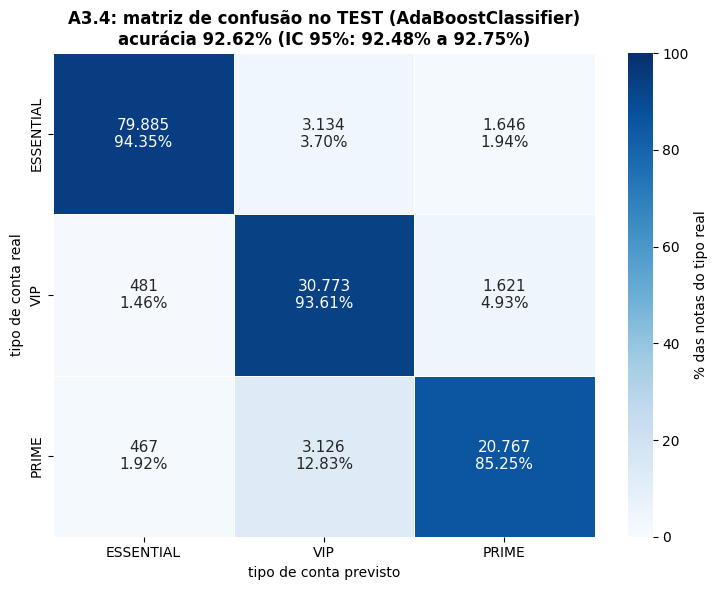

In [54]:
resultado_A3_4_3 = AtividadeA3_4("test")

### O que a matriz de confusão do TEST mostra

O test ficou guardado até agora, então esta é a **avaliação final e imparcial** do classificador.

* **Acurácia de 92,62%** (IC 95%: 92,48% a 92,75%): 131.425 das 141.900 notas certas.
* **Recall** de 94,35% (ESSENTIAL), 93,61% (VIP) e 85,25% (PRIME). **Precisão** de 98,83%, 83,10% e 86,41%. É o mesmo retrato do train e do validation.
* **Os intervalos do test e do validation se sobrepõem nas três métricas.** O test ficou até um pouco acima do validation e próximo do train. O modelo generaliza para notas que nunca viu.
* Na prática, a expectativa é acertar o tipo de conta de cerca de **92,6% dos clientes**. Os erros ficam concentrados nos clientes cuja renda não combina com o tipo de conta.

##Atividade A3.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

1. Métricas na população inteira (621.823 notas)


,população
acurácia (%),92.63
acurácia balanceada (%),91.08
F1 macro (%),90.17


previsto,ESSENTIAL,VIP,PRIME
real,,,
ESSENTIAL,349021,13805,6990
VIP,2196,136061,7302
PRIME,2011,13545,90892


Notas com o tipo de conta errado: 45.849 (7.37%)

2. 200 amostras aleatórias de 141.900 notas da população


,média,desvio,"P2,5","P97,5",mínimo,máximo
acurácia (%),92.63,0.06,92.52,92.76,92.46,92.79
acurácia balanceada (%),91.08,0.08,90.94,91.27,90.84,91.29
F1 macro (%),90.17,0.08,90.04,90.35,89.91,90.40



Comparação: população × amostras × validation × test


,população,média das 200 amostras,validation,test,validation: % das amostras abaixo,test: % das amostras abaixo,test dentro da faixa de 95%
acurácia (%),92.63,92.63,92.46,92.62,0.0,43.5,True
acurácia balanceada (%),91.08,91.08,90.95,91.07,4.0,42.5,True
F1 macro (%),90.17,90.17,89.96,90.13,1.0,31.0,True



3. Exemplos sorteados da população (5 acertos e 5 erros)


,NOTA FISCAL,RENDA BRUTO (R$),NOTA DE SATISFAÇÃO (%),tipo real,tipo previsto,acertou
0,1635796,3123.97,68.68,ESSENTIAL,ESSENTIAL,True
1,7550935,17231.04,68.68,PRIME,PRIME,True
2,3465075,8401.73,68.68,VIP,VIP,True
3,2808656,3392.10,68.68,ESSENTIAL,ESSENTIAL,True
4,4748968,7610.92,68.68,VIP,VIP,True
5,8266854,4468.88,68.68,PRIME,VIP,False
6,7344667,5287.43,68.68,PRIME,VIP,False
7,1901982,10746.59,68.68,PRIME,VIP,False
8,1013329,9025.81,68.68,PRIME,VIP,False
9,7361122,7056.71,68.68,PRIME,VIP,False


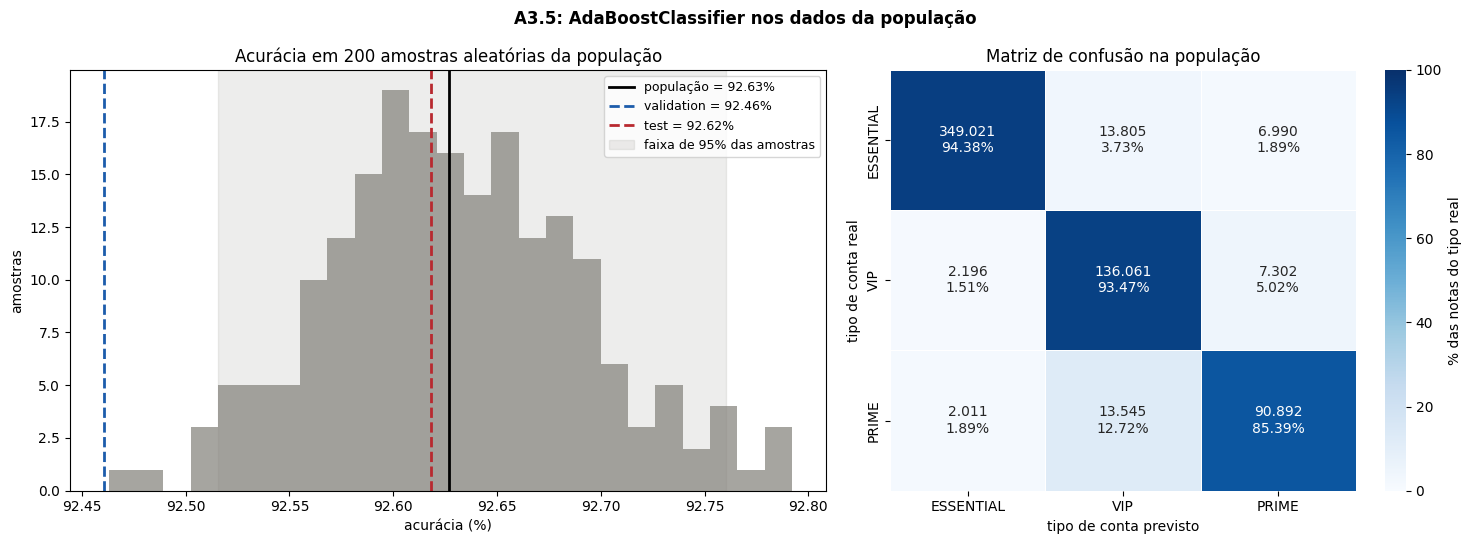

In [55]:
resultado_A3_5 = AtividadeA3_5()

### O que o teste na população mostrou

* **População inteira (621.823 notas):** acurácia de **92,63%**, acurácia balanceada de 91,08% e F1 macro de 90,17%. A matriz repete o padrão dos conjuntos: recall de 94,38%, 93,47% e 85,39%, e 12,72% dos PRIME previstos como VIP.
* **45.849 notas erradas (7,37%).** É quase o mesmo número dos 46.318 clientes "fora do lugar" encontrados na clusterização (A2.7). Os cortes otimizados do AdaBoost e a nota de satisfação recuperam só cerca de 470 notas. O limite vem da base, não do modelo.
* **200 amostras aleatórias de 141.900 notas:** acurácia média de 92,63% (desvio de 0,06 p.p.), com faixa de 95% de 92,52% a 92,76%.
  * O **test (92,62%) cai no centro da faixa** (43,5% das amostras ficam abaixo dele). É uma amostra típica da população.
  * O **validation (92,46%) ficou no limite inferior**: igual à menor das 200 amostras. Registro isso com honestidade: é um sorteio atípico, e o mesmo fenômeno já apareceu na clusterização (concordância 0,05 p.p. abaixo do P2,5), porque a acurácia e a concordância medem a mesma coisa, a renda de acordo com o tipo de conta. O validation simplesmente tem um pouco mais de clientes "fora do lugar". Isso não afeta a escolha do modelo, porque os 10 classificadores foram comparados no mesmo validation, e o test e a população confirmam os 92,6%.
* **Exemplos:** os 5 erros sorteados são todos clientes PRIME com renda entre R\$ 4.469 e R\$ 10.747, a faixa típica do VIP. O modelo os chama de VIP porque é isso que a renda deles indica.

## RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO

Fazer aqui o **RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ **Objetivo:** prever o tipo de conta do cliente (ESSENTIAL, VIP ou PRIME) a partir dos dados de cadastro, para enquadrar clientes novos e revisar o enquadramento dos atuais. Usei 24 variáveis de entrada e deixei de fora o gasto (TOTAL), que não existe no momento do cadastro e não acrescenta informação além da renda. Escolhi o modelo no train e no validation, fiz a avaliação final no test e conferi na população (621.823 notas).

*   ✅ **Modelo escolhido: AdaBoost.** Comparei os 10 classificadores do roteiro. Cinco deles empataram na prática, entre 92,21% e 92,46% de acurácia no validation: AdaBoost, Neural Net, Random Forest, Decision Tree e RBF SVM. O AdaBoost teve o **maior score (92,46%)** e a menor diferença entre train e validation. Para comparar: responder sempre "ESSENTIAL" acerta 59,58%.

*   ✅ **Desempenho estável em todos os conjuntos, sem overfitting:**

    | Conjunto | Acurácia | IC 95% |
    |---|---|---|
    | Train (validação cruzada, 10 folds) | 92,66% | 92,53% a 92,80% |
    | Validation | 92,46% | 92,33% a 92,60% |
    | Test (avaliação final) | 92,62% | 92,48% a 92,75% |
    | População (621.823 notas) | 92,63% | valor da população |

*   ✅ **Desempenho por tipo de conta (população):**

    | Tipo de conta | Acerto dentro do tipo (recall) | Confiança da previsão (precisão) |
    |---|---|---|
    | ESSENTIAL | 94,4% | 98,8% |
    | VIP | 93,5% | 83,3% |
    | PRIME | 85,4% | 86,4% |

*   ✅ **Achado 1: a renda decide o tipo de conta.** A renda responde por 85,83% da importância do modelo. Só com ela, o AdaBoost já acerta 92,36%. Região, sexo, estado civil, dependentes, opinião e as características dos vinhos não acrescentam nada. A nota de satisfação acrescenta 0,10 p.p.: ela é fixa em 68,68% para quase todos os clientes e só varia em parte dos PRIME.

*   ✅ **Achado 2: os "erros" são clientes com renda de outro tipo de conta.** Na população, são 45.849 notas (7,37%), quase as mesmas 46.318 encontradas pela clusterização. Um PRIME errado tem renda mediana de cerca de R\$ 8.300, contra R\$ 21.500 de um PRIME acertado. Um ESSENTIAL errado tem cerca de R\$ 12.300, contra R\$ 3.250. Mais do que uma falha do modelo, esses erros mostram uma **divergência entre a renda do cliente e a conta que ele tem**.

*   ✅ **Achado 3: o PRIME é o tipo mais desalinhado.** 14,6% das notas PRIME são de clientes com renda de VIP (12,7%) ou de ESSENTIAL (1,9%).

*   ✅ **Recomendações:**
    1.  Usar o classificador no cadastro de clientes novos para sugerir o tipo de conta. Uma previsão de ESSENTIAL é praticamente certa (98,8%).
    2.  Usar as divergências como lista de ação:
        *   ESSENTIAL previstos como VIP ou PRIME (20.795 notas na população) são candidatos a upgrade;
        *   PRIME previstos como VIP ou ESSENTIAL (15.556 notas) merecem uma revisão para saber se os benefícios do PRIME se pagam para eles.
    3.  Com os dados atuais, nenhum modelo deve passar de cerca de 92,6%. Para ir além, seria preciso coletar informações que expliquem a escolha da conta além da renda, como tempo de clube, canal de aquisição e frequência de compra.

# RELATÓRIO FINAL - VISÃO HOLÍSTICA SOBRE O PROJETO

Fazer aqui o **RELATÓRIO FINAL** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ **O projeto:** respondi três perguntas sobre os clientes da UVVine, com três modelos de aprendizado de máquina:
    1.  **Quanto o cliente gasta?** (regressão)
    2.  **Que grupos de clientes existem?** (clusterização, sem usar o gasto nem o tipo de conta)
    3.  **Que tipo de conta o cliente deve ter?** (classificação)

    Usei a base limpa da Parte 1 (1.047.523 notas fiscais). Ela foi dividida em train, validation e test, cada um com o **tamanho ideal de 141.900 notas** calculado na Parte 1. As 621.823 notas restantes formaram a população, usada como teste extra. O test ficou guardado até a avaliação final de cada modelo.

*   ✅ **Os três modelos:**

    | Pergunta | Modelo escolhido | Score no test | Score na população |
    |---|---|---|---|
    | Quanto gasta? | Linear Regression | R² = 0,7341 | R² = 0,7368 |
    | Que grupos existem? | K-Means, 3 clusters, só a renda | silhueta = 0,872; 92,57% de concordância com o tipo de conta | silhueta = 0,868; 92,55% |
    | Que conta deve ter? | AdaBoost | acurácia = 92,62% | acurácia = 92,63% |

    Em todos os casos, o resultado no test e na população ficou praticamente igual ao do treino. Não há overfitting, e os números valem para clientes que os modelos nunca viram.

*   ✅ **A conclusão central: a renda explica tudo.** Os três modelos chegaram à mesma resposta por caminhos independentes:
    *   na **regressão**, das 26 variáveis só a renda é significativa: cada R\$ 1.000 a mais de renda soma **R\$ 109,45** ao gasto por nota;
    *   na **clusterização**, o melhor agrupamento usa só a renda. Sem nunca ver o tipo de conta, ele reencontrou os três tipos em 92,6% das notas;
    *   na **classificação**, a renda responde por 86% da importância do modelo, e só com ela já se acerta 92,4% dos tipos de conta.

    Região, sexo, estado civil, dependentes, opinião e as 13 características do vinho **não explicam nem o gasto nem o tipo de conta** em nenhum dos três modelos.

*   ✅ **Os dois limites da base, e por que os modelos já chegaram neles:**
    1.  **O gasto é uma fração da renda sorteada entre 4% e 18%**, igual nos três tipos de conta, com média de 11%. Nenhuma variável indica qual fração será usada, então **R² = 0,74 é o máximo possível** para prever o gasto, e a regressão linear chegou lá.
    2.  **Cerca de 7,4% das notas são de clientes com renda incompatível com o tipo de conta:** 45.849 notas na população pelo classificador e 46.318 pela clusterização. São clientes PRIME com renda de VIP ou ESSENTIAL, e ESSENTIAL com renda de VIP ou PRIME. Por isso, **92,6% é o máximo de acerto** para o tipo de conta, e cinco classificadores diferentes pararam nesse mesmo ponto.

    Modelos mais complexos não vão melhorar esses números. O próximo ganho depende de **dados novos**.

*   ✅ **Confiabilidade:** cada resultado tem intervalo de confiança de 95%, calculado por validação cruzada (10 folds) e bootstrap (9.999 reamostras). Também conferi cada modelo em 200 amostras aleatórias da população. Os erros de amostragem ficam em torno de 0,003 no R² e de 0,07 p.p. na acurácia. Em alguns casos, o validation ou o test caiu na borda da faixa das 200 amostras. São diferenças de décimos de ponto percentual, explicadas pelo sorteio, e a população inteira confirma os números.

*   ✅ **O que isso significa para o negócio:**
    *   **O PRIME gasta 5,2 vezes mais que o ESSENTIAL porque ganha mais, não porque é PRIME.** Os três tipos de conta destinam a mesma fatia da renda (cerca de 11%) a cada compra.
    *   **Três faixas de renda separam o consumo melhor que os tipos de conta:** até R\$ 5.764, de R\$ 5.764 a R\$ 14.579 e acima de R\$ 14.579. A faixa alta gasta 6,3 vezes a faixa baixa.
    *   **Há clientes no tipo de conta "errado", e eles gastam conforme a renda.**
        *   Um ESSENTIAL com renda alta gasta R\$ 1.968 por nota, quase como um PRIME.
        *   Um PRIME com renda baixa gasta R\$ 428, quase como um ESSENTIAL.
        *   Na população, são 20.795 notas de ESSENTIAL que o classificador enquadra como VIP ou PRIME, e 15.556 notas de PRIME enquadradas como VIP ou ESSENTIAL.
    *   **A satisfação não move o negócio.** Na Parte 1, 80,2% dos clientes se disseram satisfeitos, mas só 3% "muito satisfeitos". A satisfação não muda o gasto nem o tipo de conta. Além disso, o campo NOTA DE SATISFAÇÃO (%) é praticamente fixo em 68,68% para quase todos os clientes, o que indica um problema na forma de medir.

*   ✅ **Recomendações aos gestores:**
    1.  **Colocar a renda no centro das decisões:**
        *   projetar o faturamento com cerca de 11% da renda por nota (regressão);
        *   segmentar campanhas pelas três faixas de renda (clusterização);
        *   sugerir o tipo de conta no cadastro de clientes novos (classificação). Uma previsão de ESSENTIAL acerta 98,8% das vezes.
    2.  **Realinhar os tipos de conta:**
        *   oferecer upgrade aos ESSENTIAL com renda de VIP ou PRIME, que já gastam como eles;
        *   revisar se os benefícios do PRIME se pagam para os PRIME com renda baixa.
    3.  **Coletar dados que a base não tem:** ocasião da compra, promoções, frequência, canal de aquisição e tempo de clube. São essas informações que podem explicar por que um cliente gasta 4% ou 18% da renda, e por que escolheu a conta que tem. É o único caminho para passar dos limites de 74% e 92,6%.
    4.  **Rever a pesquisa de satisfação:** corrigir o campo de nota, que é quase constante, e investigar o que separa o cliente "satisfeito" do "muito satisfeito". Hoje, a satisfação não se traduz em gasto.
    5.  **Atualizar os modelos com amostras do tamanho ideal:** 141.900 notas bastam para estimar o gasto com precisão (Parte 1). Os modelos podem ser refeitos periodicamente sem processar a base inteira.

*   ✅ **Limitações:**
    *   A unidade de análise é a nota fiscal, e não o cliente: um mesmo cliente pode aparecer em várias notas.
    *   A base tem padrões típicos de dados simulados: a fração da renda sorteada entre 15 valores fixos e a nota de satisfação quase constante.
    *   As conclusões valem para esta base. Antes de aplicá-las na operação, é preciso confirmá-las com dados reais da UVVine.